In [1]:

%pip install "numpy>=2.0,<3" "scipy>=1.14,<2" "pandas>=2.2,<3" "networkx>=3.3,<4" "matplotlib>=3.9,<4" "xarray>=2024.6" "statsmodels>=0.14,<1" "scikit-learn>=1.5,<2" "pyyaml>=6,<7" "pytest>=8,<10" "hypothesis>=6,<7"


   ---------------------------------------- 0.0/682.0 kB ? eta -:--:--
   ---------------------------------------- 0.0/682.0 kB ? eta -:--:--
   ---------------------------------------- 0.0/682.0 kB ? eta -:--:--
   ------------------------------ --------- 524.3/682.0 kB 2.1 MB/s eta 0:00:01
   ---------------------------------------- 682.0/682.0 kB 1.8 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

import sys
import numpy as np
import scipy
import pandas as pd
import networkx as nx
import matplotlib
import xarray as xr
import statsmodels
import sklearn
import pytest
import hypothesis

print("=" * 55)
print("SENOME–HYPERSENOME COMPUTATIONAL ENVIRONMENT")
print("=" * 55)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Pandas:", pd.__version__)
print("NetworkX:", nx.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Xarray:", xr.__version__)
print("Statsmodels:", statsmodels.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Pytest:", pytest.__version__)
print("Hypothesis:", hypothesis.__version__)

print("=" * 55)
print("ENVIRONMENT CHECK: PASSED")


SENOME–HYPERSENOME COMPUTATIONAL ENVIRONMENT
Python: 3.13.9
NumPy: 2.3.5
SciPy: 1.16.3
Pandas: 2.3.3
NetworkX: 3.5
Matplotlib: 3.10.6
Xarray: 2025.10.1
Statsmodels: 0.14.5
Scikit-learn: 1.7.2
Pytest: 8.4.2
Hypothesis: 6.168.5
ENVIRONMENT CHECK: PASSED


In [3]:

from pathlib import Path

# SENOME–HYPERSENOME RESEARCH PROJECT
# Stage 1: Computational Environment
# Script 03: Project Directory Initialization

PROJECT_ROOT = Path.cwd().resolve()

DIRECTORIES = [
    "configs",
    "data/raw",
    "data/synthetic",
    "data/processed",
    "src/senome/models",
    "src/senome/estimators",
    "src/senome/geometry",
    "src/senome/analysis",
    "tests/unit",
    "tests/analytical",
    "tests/integration",
    "tests/statistical",
    "results/figures",
    "results/tables",
    "results/logs",
    "results/validation",
]

print("=" * 65)
print("SENOME–HYPERSENOME RESEARCH PROJECT")
print("=" * 65)

print(f"\nProject location:\n{PROJECT_ROOT}\n")

for directory in DIRECTORIES:
    folder = PROJECT_ROOT / directory
    folder.mkdir(parents=True, exist_ok=True)
    print(f"[OK] {directory}")

assert all(
    (PROJECT_ROOT / directory).is_dir()
    for directory in DIRECTORIES
), "Directory initialization failed."

print("\n" + "=" * 65)
print("PROJECT STRUCTURE: SUCCESSFULLY INITIALIZED")
print(f"Directories verified: {len(DIRECTORIES)}")
print("=" * 65)


SENOME–HYPERSENOME RESEARCH PROJECT

Project location:
C:\Users\mahsa

[OK] configs
[OK] data/raw
[OK] data/synthetic
[OK] data/processed
[OK] src/senome/models
[OK] src/senome/estimators
[OK] src/senome/geometry
[OK] src/senome/analysis
[OK] tests/unit
[OK] tests/analytical
[OK] tests/integration
[OK] tests/statistical
[OK] results/figures
[OK] results/tables
[OK] results/logs
[OK] results/validation

PROJECT STRUCTURE: SUCCESSFULLY INITIALIZED
Directories verified: 16


In [4]:

# ============================================================
# SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
# STAGE 1 | SCRIPT 04
# Reproducibility Configuration and Environment Manifest
# ============================================================

from pathlib import Path
from importlib.metadata import version
import hashlib
import json
import platform
import sys
import numpy as np

# 1. Locate and verify the research project

PROJECT_ROOT = Path.cwd().resolve()

assert (PROJECT_ROOT / "configs").is_dir(), (
    "Project folders not found. Run Script 03 first."
)

# 2. Define reproducibility settings

CONFIG = {
    "project": "Senome-Hypersenome",
    "master_seed": 20261008,
    "random_generator": "PCG64DXSM",
    "simulation_type": "synthetic",
    "numerical_precision": "float64",
}

config_path = PROJECT_ROOT / "configs" / "reproducibility.json"

config_text = json.dumps(
    CONFIG,
    indent=4,
    sort_keys=True
) + "\n"

# Prevent accidental changes to existing settings

if config_path.exists():
    existing = json.loads(config_path.read_text(
        encoding="utf-8"
    ))
    assert existing == CONFIG, (
        "Existing configuration differs. "
        "Review it before continuing."
    )
else:
    config_path.write_text(
        config_text,
        encoding="utf-8"
    )

# 3. Build independent, reproducible random streams

def make_rng(stream_name: str) -> np.random.Generator:

    if not isinstance(stream_name, str) or not stream_name:
        raise ValueError("stream_name must be nonempty.")

    digest = hashlib.sha256(
        stream_name.encode("utf-8")
    ).digest()

    stream_words = [
        int.from_bytes(digest[i:i+4], "little")
        for i in range(0, 16, 4)
    ]

    seed_sequence = np.random.SeedSequence(
        [CONFIG["master_seed"], *stream_words]
    )

    return np.random.Generator(
        np.random.PCG64DXSM(seed_sequence)
    )

# 4. Test deterministic reproducibility

sample_a = make_rng("reproducibility_test").random(1000)
sample_b = make_rng("reproducibility_test").random(1000)
sample_c = make_rng("independent_test").random(1000)

assert np.array_equal(sample_a, sample_b), (
    "Reproducibility test failed."
)

assert not np.array_equal(sample_a, sample_c), (
    "Random streams are not distinct."
)

# 5. Record the computational environment

packages = [
    "numpy",
    "scipy",
    "pandas",
    "networkx",
    "matplotlib",
    "xarray",
    "statsmodels",
    "scikit-learn",
    "PyYAML",
    "pytest",
    "hypothesis",
]

manifest = {
    "python_version": platform.python_version(),
    "python_executable": sys.executable,
    "operating_system": platform.platform(),
    "packages": {
        package: version(package)
        for package in packages
    },
    "configuration_sha256": hashlib.sha256(
        config_path.read_bytes()
    ).hexdigest(),
}

manifest_path = (
    PROJECT_ROOT / "results" / "logs"
    / "environment_manifest.json"
)

manifest_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

manifest_path.write_text(
    json.dumps(manifest, indent=4, sort_keys=True),
    encoding="utf-8"
)

# 6. Final verification

assert config_path.is_file()
assert manifest_path.is_file()

print("=" * 60)
print("SENOME–HYPERSENOME REPRODUCIBILITY CHECK")
print("=" * 60)
print("[PASS] Configuration saved")
print("[PASS] Deterministic random stream")
print("[PASS] Distinct named random streams")
print("[PASS] Environment manifest saved")
print("[PASS] Configuration checksum recorded")
print("=" * 60)
print("SCRIPT 04: SUCCESSFULLY COMPLETED")


SENOME–HYPERSENOME REPRODUCIBILITY CHECK
[PASS] Configuration saved
[PASS] Deterministic random stream
[PASS] Distinct named random streams
[PASS] Environment manifest saved
[PASS] Configuration checksum recorded
SCRIPT 04: SUCCESSFULLY COMPLETED


In [5]:

# ============================================================
# SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
# STAGE 1 | SCRIPT 05
# Ground-Truth Network Environment Specification
# ============================================================

from pathlib import Path
import json
import hashlib
import networkx as nx

PROJECT_ROOT = Path.cwd().resolve()
CONFIG_DIR = PROJECT_ROOT / "configs"

assert CONFIG_DIR.is_dir(), (
    "Project configuration folder not found. "
    "Complete Script 03 first."
)

# ------------------------------------------------------------
# 1. Define the mathematical simulation environment
# ------------------------------------------------------------

MODEL = {
    "schema_version": 1,
    "model_class": "discrete_binary_stochastic_network",
    "data_type": "synthetic",

    "nodes": ["P1", "P2", "P3"],

    "coordinates": {
        "P1": 0.0,
        "P2": 1.0,
        "P3": 2.0
    },

    "time": {
        "unit": "abstract_time_unit",
        "sampling_interval": 1.0,
        "prediction_horizon_samples": 1,
        "window_samples": 256,
        "burn_in_samples": 1000,
        "recorded_samples": 8192
    },

    "observations": {
        "alphabet": [0, 1],
        "environmental_driver": "binary_shared_input"
    },

    "dynamics": {
        "transition_family": "Bernoulli_logistic",
        "node_bias": {
            "P1": -0.30,
            "P2": 0.00,
            "P3": 0.30
        },
        "self_memory_strength": 0.45,
        "coupling_strength": 1.20
    },

    "geometry": {
        "spatial_edges": [
            ["P1", "P2"],
            ["P2", "P3"]
        ],
        "characteristic_time": 256.0,
        "characteristic_length": 1.0,
        "diffusion_bandwidth": 0.5,
        "node_weighting": "uniform"
    },

    "curvature": {
        "alpha": 1.0,
        "beta": 1.0,
        "g0_calibration": "independent_positive_median"
    },

    "scenarios": {
        "disconnected": {
            "edges": [],
            "forcing_strength": 0.0
        },

        "shared_forcing": {
            "edges": [],
            "forcing_strength": 1.10
        },

        "feedforward": {
            "edges": [
                ["P1", "P2"],
                ["P1", "P3"]
            ],
            "forcing_strength": 0.0
        },

        "recurrent": {
            "edges": [
                ["P1", "P2"],
                ["P2", "P3"],
                ["P3", "P1"]
            ],
            "forcing_strength": 0.0
        },

        "feedback_disrupted": {
            "edges": [
                ["P1", "P2"],
                ["P2", "P3"]
            ],
            "forcing_strength": 0.0
        }
    }
}

# ------------------------------------------------------------
# 2. Validate basic scientific specifications
# ------------------------------------------------------------

nodes = MODEL["nodes"]

assert len(nodes) == len(set(nodes))
assert len(nodes) >= 2

time_config = MODEL["time"]

assert time_config["sampling_interval"] > 0
assert time_config["window_samples"] > 1
assert time_config["recorded_samples"] > (
    2 * time_config["window_samples"]
)
assert time_config["burn_in_samples"] >= 0

assert MODEL["curvature"]["alpha"] > 0
assert MODEL["curvature"]["beta"] > 0

assert MODEL["geometry"]["characteristic_time"] > 0
assert MODEL["geometry"]["characteristic_length"] > 0
assert MODEL["geometry"]["diffusion_bandwidth"] >= 0

# ------------------------------------------------------------
# 3. Independently verify network topology
# ------------------------------------------------------------

expected_cycles = {
    "disconnected": False,
    "shared_forcing": False,
    "feedforward": False,
    "recurrent": True,
    "feedback_disrupted": False
}

topology_results = {}

for name, scenario in MODEL["scenarios"].items():

    graph = nx.DiGraph()
    graph.add_nodes_from(nodes)
    graph.add_edges_from(scenario["edges"])

    assert set(graph.nodes()) == set(nodes)

    cycles = list(nx.simple_cycles(graph))

    # The manuscript defines interunit recurrent pathways
    # through cycles involving at least two distinct units.
    cycles = [c for c in cycles if len(c) >= 2]

    has_feedback = len(cycles) > 0

    assert has_feedback == expected_cycles[name], (
        f"Unexpected feedback topology: {name}"
    )

    topology_results[name] = {
        "number_of_edges": graph.number_of_edges(),
        "number_of_cycles": len(cycles),
        "has_recurrent_feedback": has_feedback
    }

# ------------------------------------------------------------
# 4. Verify spatial geometry separately
# ------------------------------------------------------------

spatial_graph = nx.Graph()
spatial_graph.add_nodes_from(nodes)
spatial_graph.add_edges_from(
    MODEL["geometry"]["spatial_edges"]
)

assert nx.is_connected(spatial_graph), (
    "Spatial measurement graph must be connected."
)

# Biological directed interactions and the spatial
# measurement graph are deliberately distinct.

# ------------------------------------------------------------
# 5. Save without overwriting a different specification
# ------------------------------------------------------------

config_path = CONFIG_DIR / "model_specification.json"

serialized = json.dumps(
    MODEL,
    indent=4,
    sort_keys=True
) + "\n"

if config_path.exists():

    existing = json.loads(
        config_path.read_text(encoding="utf-8")
    )

    assert existing == MODEL, (
        "An existing model specification differs. "
        "Do not overwrite without reviewing the changes."
    )

else:

    config_path.write_text(
        serialized,
        encoding="utf-8"
    )

# ------------------------------------------------------------
# 6. Verify saved configuration
# ------------------------------------------------------------

loaded = json.loads(
    config_path.read_text(encoding="utf-8")
)

assert loaded == MODEL

checksum = hashlib.sha256(
    config_path.read_bytes()
).hexdigest()

# ------------------------------------------------------------
# 7. Print verification report
# ------------------------------------------------------------

print("=" * 68)
print("SENOME–HYPERSENOME NETWORK SPECIFICATION")
print("=" * 68)

print(f"Number of nodes: {len(nodes)}")
print(f"Sampling interval: {time_config['sampling_interval']}")
print(f"Recorded samples: {time_config['recorded_samples']}")

print("\nGROUND-TRUTH NETWORK TOPOLOGIES")
print("-" * 68)

for name, result in topology_results.items():

    print(
        f"{name:<22} "
        f"Edges: {result['number_of_edges']}  "
        f"Cycles: {result['number_of_cycles']}  "
        f"Feedback: {result['has_recurrent_feedback']}"
    )

print("-" * 68)
print("Spatial measurement graph: CONNECTED")
print("Directed topology validation: PASSED")
print("Configuration persistence: PASSED")
print("Configuration SHA256:", checksum)
print("=" * 68)
print("SCRIPT 05: SUCCESSFULLY COMPLETED")


SENOME–HYPERSENOME NETWORK SPECIFICATION
Number of nodes: 3
Sampling interval: 1.0
Recorded samples: 8192

GROUND-TRUTH NETWORK TOPOLOGIES
--------------------------------------------------------------------
disconnected           Edges: 0  Cycles: 0  Feedback: False
shared_forcing         Edges: 0  Cycles: 0  Feedback: False
feedforward            Edges: 2  Cycles: 0  Feedback: False
recurrent              Edges: 3  Cycles: 1  Feedback: True
feedback_disrupted     Edges: 2  Cycles: 0  Feedback: False
--------------------------------------------------------------------
Spatial measurement graph: CONNECTED
Directed topology validation: PASSED
Configuration persistence: PASSED
Configuration SHA256: 187b21b22b10b1013afc19fc5aa925db1d60827c4f0027250829956f7b17714f
SCRIPT 05: SUCCESSFULLY COMPLETED


In [6]:

%%writefile src/senome/models/dynamics.py
"""
Senome–Hypersenome Computational Framework
Module: Stochastic Network Dynamics

Purpose
-------
Generate reproducible synthetic binary-state trajectories
from independently specified network mechanisms.

The simulator NEVER uses entropy, recursive gain,
informational curvature, or GAC to generate observations.

Model
-----
P(X_i[t+1] = 1 | X[t], U[t]) = sigmoid(

    b_i
    + a * (2*X_i[t] - 1)
    + c * SUM_j W[j,i]*(2*X_j[t] - 1)
    + d * (2*U[t] - 1)

)

W[j,i] represents a directed influence from j to i,
normalized by the number of incoming connections.

All nodes update synchronously from the previous state.
"""

from __future__ import annotations

from dataclasses import dataclass
from hashlib import sha256
from typing import Any, Mapping

import numpy as np
from numpy.typing import NDArray
from scipy.special import expit


@dataclass(frozen=True)
class SimulationResult:
    """Complete output of one synthetic simulation."""

    scenario: str
    node_names: tuple[str, ...]
    states: NDArray[np.uint8]
    common_input: NDArray[np.uint8]
    true_adjacency: NDArray[np.float64]
    sampling_interval: float
    burn_in_samples: int
    master_seed: int


def make_rng(
    master_seed: int,
    stream_name: str,
) -> np.random.Generator:
    """Create a reproducible, independently named RNG stream."""

    if isinstance(master_seed, bool) or not isinstance(
        master_seed, int
    ) or master_seed < 0:
        raise ValueError("master_seed must be a nonnegative integer.")

    if not isinstance(stream_name, str) or not stream_name:
        raise ValueError("stream_name must be nonempty.")

    digest = sha256(stream_name.encode("utf-8")).digest()

    stream_words = [
        int.from_bytes(digest[i:i + 4], "little")
        for i in range(0, 16, 4)
    ]

    seed_sequence = np.random.SeedSequence(
        [master_seed, *stream_words]
    )

    return np.random.Generator(
        np.random.PCG64DXSM(seed_sequence)
    )


def validate_model(spec: Mapping[str, Any]) -> None:
    """Reject invalid simulation specifications."""

    if spec.get("model_class") != "discrete_binary_stochastic_network":
        raise ValueError("Unsupported model class.")

    nodes = spec["nodes"]

    if len(nodes) < 2 or len(nodes) != len(set(nodes)):
        raise ValueError("Nodes must be distinct and >= 2.")

    node_set = set(nodes)

    dynamics = spec["dynamics"]
    time = spec["time"]

    if set(dynamics["node_bias"]) != node_set:
        raise ValueError("Node biases do not match the node list.")

    numerical_parameters = [
        *dynamics["node_bias"].values(),
        dynamics["self_memory_strength"],
        dynamics["coupling_strength"],
        time["sampling_interval"],
    ]

    if not all(np.isfinite(x) for x in numerical_parameters):
        raise ValueError("Model parameters must be finite.")

    if time["sampling_interval"] <= 0:
        raise ValueError("Sampling interval must be positive.")

    for key in ["burn_in_samples", "recorded_samples"]:
        value = time[key]

        if isinstance(value, bool) or not isinstance(value, int):
            raise ValueError(f"{key} must be an integer.")

        if value < (0 if key == "burn_in_samples" else 1):
            raise ValueError(f"Invalid {key}.")

    for name, scenario in spec["scenarios"].items():

        forcing = scenario["forcing_strength"]

        if not np.isfinite(forcing) or forcing < 0:
            raise ValueError(f"Invalid forcing in {name}.")

        edges = [tuple(edge) for edge in scenario["edges"]]

        if len(edges) != len(set(edges)):
            raise ValueError(f"Duplicate edges in {name}.")

        for source, target in edges:

            if source not in node_set or target not in node_set:
                raise ValueError(f"Unknown node in {name}.")

            if source == target:
                raise ValueError(
                    "Self-connections are represented by "
                    "the separate self-memory parameter."
                )


def build_adjacency(
    node_names: tuple[str, ...],
    edges: list[list[str]],
) -> NDArray[np.float64]:
    """Construct directed adjacency: source rows, target columns."""

    index = {name: i for i, name in enumerate(node_names)}

    n_nodes = len(node_names)

    adjacency = np.zeros(
        (n_nodes, n_nodes),
        dtype=np.float64,
    )

    for source, target in edges:
        adjacency[index[source], index[target]] = 1.0

    return adjacency


def simulate_network(
    spec: Mapping[str, Any],
    scenario_name: str,
    master_seed: int,
) -> SimulationResult:
    """
    Simulate an independently specified synthetic network.

    states[t+1] depends only on states[t] and input[t].

    Returned states contain N+1 observations for N transitions.
    common_input[t] generates the transition t -> t+1.

    This alignment prevents future-information leakage.
    """

    validate_model(spec)

    if scenario_name not in spec["scenarios"]:
        raise ValueError(f"Unknown scenario: {scenario_name}")

    scenario = spec["scenarios"][scenario_name]

    nodes = tuple(spec["nodes"])
    n_nodes = len(nodes)

    time = spec["time"]
    dynamics = spec["dynamics"]

    burn_in = int(time["burn_in_samples"])
    recorded = int(time["recorded_samples"])

    total_transitions = burn_in + recorded

    rng = make_rng(
        master_seed,
        f"simulation::{scenario_name}",
    )

    adjacency = build_adjacency(
        nodes,
        scenario["edges"],
    )

    incoming_degree = adjacency.sum(axis=0)

    normalized_adjacency = adjacency / np.maximum(
        incoming_degree, 1.0
    )

    bias = np.array(
        [dynamics["node_bias"][name] for name in nodes],
        dtype=np.float64,
    )

    memory_strength = float(
        dynamics["self_memory_strength"]
    )

    coupling_strength = float(
        dynamics["coupling_strength"]
    )

    forcing_strength = float(
        scenario["forcing_strength"]
    )

    # States include the initial observation.
    states = np.empty(
        (total_transitions + 1, n_nodes),
        dtype=np.uint8,
    )

    # Binary environmental input shared by all nodes.
    common_input = rng.integers(
        0,
        2,
        size=total_transitions,
        dtype=np.uint8,
    )

    # Initial conditions are sampled independently.
    states[0] = rng.integers(
        0,
        2,
        size=n_nodes,
        dtype=np.uint8,
    )

    for t in range(total_transitions):

        previous = states[t].astype(np.float64)

        centered_state = 2.0 * previous - 1.0

        self_memory = (
            memory_strength * centered_state
        )

        network_input = (
            coupling_strength
            * (centered_state @ normalized_adjacency)
        )

        external_input = (
            forcing_strength
            * (2.0 * float(common_input[t]) - 1.0)
        )

        logits = (
            bias
            + self_memory
            + network_input
            + external_input
        )

        probabilities = expit(logits)

        # Independent innovations conditional on the past.
        states[t + 1] = (
            rng.random(n_nodes) < probabilities
        ).astype(np.uint8)

    # Remove initialization transients.
    observed_states = states[burn_in:].copy()

    observed_input = common_input[burn_in:].copy()

    # Validate output dimensionality and state alphabet.
    if observed_states.shape != (recorded + 1, n_nodes):
        raise RuntimeError("Unexpected simulated state shape.")

    if observed_input.shape != (recorded,):
        raise RuntimeError("Unexpected input shape.")

    if not np.all(observed_states <= 1):
        raise RuntimeError("Nonbinary state generated.")

    return SimulationResult(
        scenario=scenario_name,
        node_names=nodes,
        states=observed_states,
        common_input=observed_input,
        true_adjacency=adjacency.copy(),
        sampling_interval=float(time["sampling_interval"]),
        burn_in_samples=burn_in,
        master_seed=master_seed,
    )


Writing src/senome/models/dynamics.py


In [7]:

# ============================================================
# SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
# STAGE 2 | SCRIPT 07
# Simulation Execution and Initial Validation
# ============================================================

from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import networkx as nx

# 1. Locate project and simulation module

PROJECT_ROOT = Path.cwd().resolve()
SOURCE_DIR = PROJECT_ROOT / "src"
MODEL_FILE = SOURCE_DIR / "senome/models/dynamics.py"
CONFIG_FILE = PROJECT_ROOT / "configs/model_specification.json"
REPRO_FILE = PROJECT_ROOT / "configs/reproducibility.json"

for file in [MODEL_FILE, CONFIG_FILE, REPRO_FILE]:
    assert file.is_file(), f"Required file missing: {file}"

if str(SOURCE_DIR) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIR))

from senome.models.dynamics import (
    simulate_network,
    validate_model,
)

# 2. Load previously established specifications

with open(CONFIG_FILE, "r", encoding="utf-8") as f:
    model = json.load(f)

with open(REPRO_FILE, "r", encoding="utf-8") as f:
    reproducibility = json.load(f)

validate_model(model)

master_seed = reproducibility["master_seed"]

# 3. Run all five network scenarios

scenario_results = {}
validation_records = []

for scenario_name in model["scenarios"]:

    print(f"\nRunning: {scenario_name}")

    result = simulate_network(
        spec=model,
        scenario_name=scenario_name,
        master_seed=master_seed,
    )

    # Repeat simulation to test exact reproducibility
    repeated = simulate_network(
        spec=model,
        scenario_name=scenario_name,
        master_seed=master_seed,
    )

    # 4. Mathematical and structural checks

    expected_shape = (
        model["time"]["recorded_samples"] + 1,
        len(model["nodes"]),
    )

    assert result.states.shape == expected_shape
    assert result.common_input.shape == (
        model["time"]["recorded_samples"],
    )

    assert np.array_equal(
        result.states,
        repeated.states,
    ), "Reproducibility failure."

    assert np.array_equal(
        result.common_input,
        repeated.common_input,
    ), "Environmental input reproducibility failure."

    assert np.array_equal(
        result.true_adjacency,
        repeated.true_adjacency,
    )

    assert np.isin(result.states, [0, 1]).all()
    assert np.isin(result.common_input, [0, 1]).all()

    assert np.isfinite(result.states).all()
    assert not np.any(np.diag(result.true_adjacency))

    # Verify directed topology against specification
    graph = nx.DiGraph()
    graph.add_nodes_from(result.node_names)
    graph.add_edges_from(
        model["scenarios"][scenario_name]["edges"]
    )

    expected_adjacency = nx.to_numpy_array(
        graph,
        nodelist=list(result.node_names),
        dtype=float,
    )

    assert np.array_equal(
        result.true_adjacency,
        expected_adjacency,
    ), "Ground-truth adjacency mismatch."

    cycles = [
        cycle for cycle in nx.simple_cycles(graph)
        if len(cycle) >= 2
    ]

    # 5. Summarize the generated observations

    node_probabilities = result.states.mean(axis=0)

    assert np.all(
        (node_probabilities > 0)
        & (node_probabilities < 1)
    ), "A node has no observed state variation."

    record = {
        "scenario": scenario_name,
        "edges": graph.number_of_edges(),
        "feedback_cycles": len(cycles),
        "samples": result.states.shape[0],
        "P1_mean": node_probabilities[0],
        "P2_mean": node_probabilities[1],
        "P3_mean": node_probabilities[2],
        "reproducible": True,
        "validation": "PASS",
    }

    validation_records.append(record)
    scenario_results[scenario_name] = result

# 6. Verify all scenarios are distinct

scenario_names = list(scenario_results)

for i in range(len(scenario_names)):
    for j in range(i + 1, len(scenario_names)):

        first = scenario_results[scenario_names[i]]
        second = scenario_results[scenario_names[j]]

        assert not np.array_equal(
            first.states,
            second.states,
        ), "Two scenario trajectories are identical."

# 7. Display validation summary

validation_table = pd.DataFrame(validation_records)

print("\n" + "=" * 75)
print("SENOME–HYPERSENOME SIMULATION VALIDATION")
print("=" * 75)

print(
    validation_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}",
    )
)

print("\n" + "=" * 75)
print("All network topologies verified")
print("All simulations reproducible")
print("All observations binary and finite")
print("Temporal dimensions verified")
print("Five distinct synthetic trajectories generated")
print("=" * 75)
print("SCRIPT 07: ALL INITIAL VALIDATION CHECKS PASSED")



Running: disconnected

Running: feedback_disrupted

Running: feedforward

Running: recurrent

Running: shared_forcing

SENOME–HYPERSENOME SIMULATION VALIDATION
          scenario  edges  feedback_cycles  samples  P1_mean  P2_mean  P3_mean  reproducible validation
      disconnected      0                0     8193   0.3980   0.5106   0.5894          True       PASS
feedback_disrupted      2                0     8193   0.4113   0.4357   0.5309          True       PASS
       feedforward      2                0     8193   0.4035   0.4392   0.4990          True       PASS
         recurrent      3                1     8193   0.4604   0.4782   0.5424          True       PASS
    shared_forcing      0                0     8193   0.4352   0.5005   0.5566          True       PASS

All network topologies verified
All simulations reproducible
All observations binary and finite
Temporal dimensions verified
Five distinct synthetic trajectories generated
SCRIPT 07: ALL INITIAL VALIDATION CHECKS P

In [8]:

# ============================================================
# SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
# STAGE 2 | SCRIPT 08
# Synthetic Dataset Archiving and Integrity Verification
# ============================================================

from pathlib import Path
import hashlib
import json
import numpy as np

PROJECT_ROOT = Path.cwd().resolve()
DATA_DIR = PROJECT_ROOT / "data" / "synthetic"
LOG_DIR = PROJECT_ROOT / "results" / "logs"

DATA_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

# Verify that Script 07 was executed in this kernel.
if "scenario_results" not in globals():
    raise RuntimeError(
        "Simulation results are missing. "
        "Run Script 07 again before continuing."
    )

model_path = PROJECT_ROOT / "configs" / "model_specification.json"
repro_path = PROJECT_ROOT / "configs" / "reproducibility.json"

with model_path.open("r", encoding="utf-8") as f:
    model_config = json.load(f)

with repro_path.open("r", encoding="utf-8") as f:
    repro_config = json.load(f)

assert set(scenario_results) == set(model_config["scenarios"])

def sha256_file(path: Path) -> str:
    """Calculate a cryptographic file checksum."""
    digest = hashlib.sha256()

    with path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()


def verify_archive(path, result):
    """Verify that a saved dataset matches its source exactly."""

    with np.load(path, allow_pickle=False) as data:

        expected_fields = {
            "states",
            "common_input",
            "true_adjacency",
            "node_names",
            "scenario",
            "sampling_interval",
            "master_seed",
            "burn_in_samples",
        }

        assert set(data.files) == expected_fields

        np.testing.assert_array_equal(
            data["states"], result.states
        )

        np.testing.assert_array_equal(
            data["common_input"], result.common_input
        )

        np.testing.assert_array_equal(
            data["true_adjacency"], result.true_adjacency
        )

        np.testing.assert_array_equal(
            data["node_names"],
            np.asarray(result.node_names)
        )

        assert data["scenario"].item() == result.scenario

        assert (
            data["sampling_interval"].item()
            == result.sampling_interval
        )

        assert data["master_seed"].item() == result.master_seed

        assert (
            data["burn_in_samples"].item()
            == result.burn_in_samples
        )

        # N transitions require N+1 state observations.
        assert data["states"].shape[0] == (
            data["common_input"].shape[0] + 1
        )

        assert data["states"].dtype == np.uint8
        assert data["common_input"].dtype == np.uint8

        assert np.isin(data["states"], [0, 1]).all()
        assert np.isin(data["common_input"], [0, 1]).all()


manifest = {
    "project": "Senome-Hypersenome",
    "dataset_type": "synthetic",
    "model_config_sha256": sha256_file(model_path),
    "reproducibility_config_sha256": sha256_file(repro_path),
    "master_seed": repro_config["master_seed"],
    "datasets": {},
}

print("=" * 65)
print("SYNTHETIC DATASET ARCHIVING")
print("=" * 65)

for name in sorted(scenario_results):

    result = scenario_results[name]

    output_path = DATA_DIR / f"{name}_v1.npz"
    temporary_path = DATA_DIR / f".{name}_v1.tmp.npz"

    # Never silently overwrite existing research data.
    if output_path.exists():

        verify_archive(output_path, result)
        status = "EXISTING FILE VERIFIED"

    else:

        try:
            np.savez_compressed(
                temporary_path,
                states=result.states,
                common_input=result.common_input,
                true_adjacency=result.true_adjacency,
                node_names=np.asarray(result.node_names),
                scenario=np.asarray(result.scenario),
                sampling_interval=np.asarray(
                    result.sampling_interval
                ),
                master_seed=np.asarray(result.master_seed),
                burn_in_samples=np.asarray(
                    result.burn_in_samples
                ),
            )

            verify_archive(temporary_path, result)

            temporary_path.replace(output_path)

        finally:
            temporary_path.unlink(missing_ok=True)

        status = "SAVED AND VERIFIED"

    manifest["datasets"][name] = {
        "file": output_path.relative_to(
            PROJECT_ROOT
        ).as_posix(),
        "sha256": sha256_file(output_path),
        "number_of_nodes": len(result.node_names),
        "number_of_transitions": len(result.common_input),
        "number_of_state_observations": len(result.states),
        "number_of_directed_edges": int(
            np.count_nonzero(result.true_adjacency)
        ),
    }

    print(f"[PASS] {name:<22} {status}")

manifest_path = LOG_DIR / "synthetic_dataset_manifest.json"

manifest_text = json.dumps(
    manifest,
    indent=4,
    sort_keys=True
) + "\n"

if manifest_path.exists():

    existing = json.loads(
        manifest_path.read_text(encoding="utf-8")
    )

    assert existing == manifest, (
        "Existing dataset manifest differs. "
        "Review the files before continuing."
    )

else:

    manifest_path.write_text(
        manifest_text,
        encoding="utf-8"
    )

assert json.loads(
    manifest_path.read_text(encoding="utf-8")
) == manifest

print("=" * 65)
print("DATASET INTEGRITY: VERIFIED")
print("PROVENANCE MANIFEST: VERIFIED")
print(f"Number of datasets: {len(manifest['datasets'])}")
print("SCRIPT 08: SUCCESSFULLY COMPLETED")
print("=" * 65)


SYNTHETIC DATASET ARCHIVING
[PASS] disconnected           SAVED AND VERIFIED
[PASS] feedback_disrupted     SAVED AND VERIFIED
[PASS] feedforward            SAVED AND VERIFIED
[PASS] recurrent              SAVED AND VERIFIED
[PASS] shared_forcing         SAVED AND VERIFIED
DATASET INTEGRITY: VERIFIED
PROVENANCE MANIFEST: VERIFIED
Number of datasets: 5
SCRIPT 08: SUCCESSFULLY COMPLETED


In [9]:

%%writefile src/senome/estimators/entropy.py
"""
SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
==========================================
Stage 2 | Script 09
Module: Carrier-Level Shannon Entropy

Implements:
    S_i(t) = -sum_a p_i(a;t) log2 p_i(a;t)

    s_i(t) = S_i(t) / log2(m_i)

Design principles:
    - Causal trailing observation windows
    - Fixed symbol alphabet
    - Multiple biological network nodes
    - No future-observation leakage
    - Explicit handling of zero probabilities
    - Strict numerical and dimensional validation

All entropy values are reported in bits.
"""

from __future__ import annotations

from dataclasses import dataclass
from numbers import Integral

import numpy as np
from numpy.typing import NDArray
from scipy.special import xlogy


@dataclass(frozen=True)
class EntropyResult:
    """Results of windowed entropy estimation."""

    S_bits: NDArray[np.float64]
    s_normalized: NDArray[np.float64]
    end_sample_indices: NDArray[np.int64]
    window_samples: int
    alphabet_size: int


def shannon_entropy(
    probabilities: NDArray[np.float64],
) -> NDArray[np.float64]:
    """
    Calculate Shannon entropy along the last axis.

    Parameters
    ----------
    probabilities:
        Valid probability vectors whose entries sum to 1.

    Returns
    -------
    Shannon entropy in bits.
    """

    p = np.asarray(probabilities, dtype=np.float64)

    if p.ndim == 0 or p.shape[-1] < 2:
        raise ValueError(
            "At least two symbol probabilities are required."
        )

    if not np.all(np.isfinite(p)):
        raise ValueError(
            "Probabilities must be finite."
        )

    if np.any(p < 0) or np.any(p > 1):
        raise ValueError(
            "Probabilities must lie between 0 and 1."
        )

    totals = np.sum(p, axis=-1)

    if not np.allclose(
        totals,
        1.0,
        rtol=0.0,
        atol=1e-10,
    ):
        raise ValueError(
            "Each probability vector must sum to 1."
        )

    # xlogy(0, 0) = 0, avoiding undefined log2(0).
    entropy = -np.sum(
        xlogy(p, p),
        axis=-1,
    ) / np.log(2.0)

    return np.asarray(entropy, dtype=np.float64)


def windowed_shannon_entropy(
    symbols: NDArray,
    window_samples: int,
    alphabet_size: int = 2,
) -> EntropyResult:
    """
    Estimate Shannon entropy using trailing windows.

    Input shape:
        (time, nodes)

    Also accepts a one-dimensional single-node series.

    Each output window ends at its stated sample index.
    No observations after that index are used.

    Missing values are not silently imputed.
    """

    # --------------------------------------------------------
    # 1. Validate configuration
    # --------------------------------------------------------

    if (
        isinstance(window_samples, bool)
        or not isinstance(window_samples, Integral)
        or window_samples < 2
    ):
        raise ValueError(
            "window_samples must be an integer >= 2."
        )

    if (
        isinstance(alphabet_size, bool)
        or not isinstance(alphabet_size, Integral)
        or alphabet_size < 2
    ):
        raise ValueError(
            "alphabet_size must be an integer >= 2."
        )

    X = np.asarray(symbols)

    if X.ndim == 1:
        X = X.reshape(-1, 1)

    if X.ndim != 2:
        raise ValueError(
            "Input must have shape (time, nodes)."
        )

    if not np.issubdtype(X.dtype, np.integer):
        raise TypeError(
            "Symbols must have an integer dtype."
        )

    n_samples, n_nodes = X.shape

    if n_nodes == 0 or n_samples < window_samples:
        raise ValueError(
            "Insufficient observations or empty node dimension."
        )

    if np.any(X < 0) or np.any(X >= alphabet_size):
        raise ValueError(
            "Observed symbols fall outside the declared alphabet."
        )

    # --------------------------------------------------------
    # 2. Allocate numerical results
    # --------------------------------------------------------

    n_windows = n_samples - window_samples + 1

    S = np.zeros(
        (n_windows, n_nodes),
        dtype=np.float64,
    )

    # --------------------------------------------------------
    # 3. Calculate symbol frequencies in trailing windows
    # --------------------------------------------------------

    for symbol in range(alphabet_size):

        indicator = (X == symbol).astype(np.int64)

        cumulative = np.concatenate(
            [
                np.zeros(
                    (1, n_nodes),
                    dtype=np.int64,
                ),
                np.cumsum(
                    indicator,
                    axis=0,
                    dtype=np.int64,
                ),
            ],
            axis=0,
        )

        counts = (
            cumulative[window_samples:]
            - cumulative[:-window_samples]
        )

        probabilities = (
            counts.astype(np.float64)
            / float(window_samples)
        )

        S -= xlogy(
            probabilities,
            probabilities,
        ) / np.log(2.0)

    # --------------------------------------------------------
    # 4. Normalize entropy
    # --------------------------------------------------------

    maximum_entropy = np.log2(alphabet_size)

    if not np.all(np.isfinite(S)):
        raise FloatingPointError(
            "Nonfinite entropy value detected."
        )

    tolerance = 1e-10

    if (
        np.any(S < -tolerance)
        or np.any(S > maximum_entropy + tolerance)
    ):
        raise ArithmeticError(
            "Entropy violates theoretical bounds."
        )

    S = np.clip(
        S,
        0.0,
        maximum_entropy,
    )

    s = S / maximum_entropy

    # --------------------------------------------------------
    # 5. Preserve temporal alignment
    # --------------------------------------------------------

    end_indices = np.arange(
        window_samples - 1,
        n_samples,
        dtype=np.int64,
    )

    assert S.shape == (n_windows, n_nodes)
    assert s.shape == S.shape
    assert len(end_indices) == n_windows

    # --------------------------------------------------------
    # 6. Return structured results
    # --------------------------------------------------------

    return EntropyResult(
        S_bits=S,
        s_normalized=s,
        end_sample_indices=end_indices,
        window_samples=int(window_samples),
        alphabet_size=int(alphabet_size),
    )


Writing src/senome/estimators/entropy.py


In [10]:

# ============================================================
# SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
# STAGE 2 | SCRIPT 10
# Analytical and Numerical Validation of Shannon Entropy
# ============================================================

from pathlib import Path
from collections import Counter
import sys
import math
import numpy as np

# ------------------------------------------------------------
# 1. Import our entropy estimator
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd().resolve()
SOURCE_DIR = PROJECT_ROOT / "src"

if str(SOURCE_DIR) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIR))

from senome.estimators.entropy import (
    shannon_entropy,
    windowed_shannon_entropy,
)

passed = 0

def report(test_name):
    global passed
    passed += 1
    print(f"[PASS] {test_name}")


# ------------------------------------------------------------
# 2. Independent mathematical reference implementation
# ------------------------------------------------------------

def reference_entropy(values, alphabet_size):
    """
    Independent reference calculation using symbol counts.

    This function does not call our entropy estimator.
    """

    counts = Counter(values)
    n = len(values)

    probabilities = [
        counts.get(symbol, 0) / n
        for symbol in range(alphabet_size)
    ]

    return -sum(
        p * math.log2(p)
        for p in probabilities
        if p > 0
    )


print("=" * 65)
print("SENOME–HYPERSENOME ENTROPY VALIDATION")
print("=" * 65)


# ------------------------------------------------------------
# TEST 1: Maximum binary entropy
# ------------------------------------------------------------

p = np.array([0.5, 0.5])

result = shannon_entropy(p)

np.testing.assert_allclose(
    result, 1.0, rtol=0, atol=1e-12
)

report("Maximum binary entropy = 1 bit")


# ------------------------------------------------------------
# TEST 2: Deterministic system
# ------------------------------------------------------------

p = np.array([1.0, 0.0])

result = shannon_entropy(p)

np.testing.assert_allclose(
    result, 0.0, rtol=0, atol=1e-12
)

report("Deterministic entropy = 0 bits")


# ------------------------------------------------------------
# TEST 3: Asymmetric binary distribution
# ------------------------------------------------------------

p = np.array([0.75, 0.25])

expected = -(
    0.75 * math.log2(0.75)
    + 0.25 * math.log2(0.25)
)

result = shannon_entropy(p)

np.testing.assert_allclose(
    result, expected, rtol=0, atol=1e-12
)

print(f"    Calculated: {result:.10f} bits")
print(f"    Expected:   {expected:.10f} bits")

report("Asymmetric binary entropy")


# ------------------------------------------------------------
# TEST 4: Four-state uniform distribution
# ------------------------------------------------------------

p = np.array([0.25, 0.25, 0.25, 0.25])

result = shannon_entropy(p)

np.testing.assert_allclose(
    result, 2.0, rtol=0, atol=1e-12
)

report("Four-state maximum entropy = 2 bits")


# ------------------------------------------------------------
# TEST 5: Sliding-window entropy
# ------------------------------------------------------------

symbols = np.array([
    [0],
    [0],
    [0],
    [1],
    [0],
    [1],
    [0],
    [1],
], dtype=np.int64)

entropy_result = windowed_shannon_entropy(
    symbols,
    window_samples=4,
    alphabet_size=2,
)

expected_values = []

for start in range(5):

    window = symbols[start:start+4, 0]

    expected_values.append(
        reference_entropy(window, 2)
    )

np.testing.assert_allclose(
    entropy_result.S_bits[:, 0],
    expected_values,
    rtol=0,
    atol=1e-12,
)

np.testing.assert_array_equal(
    entropy_result.end_sample_indices,
    np.arange(3, 8),
)

report("Sliding-window values and temporal indices")


# ------------------------------------------------------------
# TEST 6: Multiple nodes and symbol alphabets
# ------------------------------------------------------------

rng = np.random.default_rng(20261008)

number_of_comparisons = 0

for alphabet_size in [2, 3, 5]:

    X = rng.integers(
        0,
        alphabet_size,
        size=(64, 3),
        dtype=np.int64,
    )

    for window_size in [4, 11, 24]:

        estimated = windowed_shannon_entropy(
            X,
            window_samples=window_size,
            alphabet_size=alphabet_size,
        )

        for row in range(estimated.S_bits.shape[0]):

            for node in range(3):

                values = X[
                    row:row+window_size,
                    node
                ]

                expected = reference_entropy(
                    values,
                    alphabet_size,
                )

                np.testing.assert_allclose(
                    estimated.S_bits[row, node],
                    expected,
                    rtol=0,
                    atol=1e-12,
                )

                number_of_comparisons += 1

print(f"    Independent comparisons: {number_of_comparisons}")

report("Multinode and multialphabet accuracy")


# ------------------------------------------------------------
# TEST 7: No future-information leakage
# ------------------------------------------------------------

baseline = np.zeros((6, 1), dtype=np.int64)

modified = baseline.copy()
modified[-1, 0] = 1

original_entropy = windowed_shannon_entropy(
    baseline, window_samples=4
)

modified_entropy = windowed_shannon_entropy(
    modified, window_samples=4
)

# Windows ending before the modified observation
# must be completely unchanged.

np.testing.assert_array_equal(
    original_entropy.S_bits[:-1],
    modified_entropy.S_bits[:-1],
)

# The final window must detect the modification.

assert not np.array_equal(
    original_entropy.S_bits[-1],
    modified_entropy.S_bits[-1],
)

report("No future-information leakage")


# ------------------------------------------------------------
# TEST 8: Invalid inputs must be rejected
# ------------------------------------------------------------

invalid_cases = [
    (np.array([0, 1]), 1, 2),
    (np.array([0, 1]), 5, 2),
    (np.array([0, 2]), 2, 2),
    (np.array([-1, 0]), 2, 2),
    (np.array([0.0, 1.0]), 2, 2),
    (np.array([0, 1]), 2, 1),
]

for data, window, alphabet in invalid_cases:

    try:
        windowed_shannon_entropy(
            data,
            window_samples=window,
            alphabet_size=alphabet,
        )

    except (ValueError, TypeError):
        pass

    else:
        raise AssertionError(
            "Invalid input was not rejected."
        )

report("Invalid-input rejection")


# ------------------------------------------------------------
# FINAL VALIDATION
# ------------------------------------------------------------

assert passed == 8

print("\n" + "=" * 65)
print(f"ANALYTICAL TEST GROUPS PASSED: {passed}/8")
print("ENTROPY ESTIMATOR: INITIAL VALIDATION PASSED")
print("=" * 65)


SENOME–HYPERSENOME ENTROPY VALIDATION
[PASS] Maximum binary entropy = 1 bit
[PASS] Deterministic entropy = 0 bits
    Calculated: 0.8112781245 bits
    Expected:   0.8112781245 bits
[PASS] Asymmetric binary entropy
[PASS] Four-state maximum entropy = 2 bits
[PASS] Sliding-window values and temporal indices
    Independent comparisons: 1404
[PASS] Multinode and multialphabet accuracy
[PASS] No future-information leakage
[PASS] Invalid-input rejection

ANALYTICAL TEST GROUPS PASSED: 8/8
ENTROPY ESTIMATOR: INITIAL VALIDATION PASSED


In [11]:

# ============================================================
# SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
# STAGE 2 | SCRIPT 11
# Multinetwork Carrier-Level Entropy Estimation
# ============================================================

from pathlib import Path
from collections import Counter
import hashlib
import json
import math
import sys

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Locate project and import the validated estimator
# ------------------------------------------------------------

ROOT = Path.cwd().resolve()
SOURCE = ROOT / "src"

if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

from senome.estimators.entropy import (
    windowed_shannon_entropy,
)

CONFIG_FILE = ROOT / "configs/model_specification.json"
MANIFEST_FILE = (
    ROOT / "results/logs/synthetic_dataset_manifest.json"
)
OUTPUT_DIR = ROOT / "data/processed"
TABLE_DIR = ROOT / "results/tables"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

with CONFIG_FILE.open("r", encoding="utf-8") as f:
    model = json.load(f)

with MANIFEST_FILE.open("r", encoding="utf-8") as f:
    manifest = json.load(f)

window_size = int(model["time"]["window_samples"])
alphabet_size = len(model["observations"]["alphabet"])
dt = float(model["time"]["sampling_interval"])

assert window_size >= 2
assert alphabet_size == 2
assert model["observations"]["alphabet"] == [0, 1]
assert dt > 0

# ------------------------------------------------------------
# 2. Independent reference entropy calculation
# ------------------------------------------------------------

def reference_entropy(values):
    counts = Counter(int(v) for v in values)
    n = len(values)

    return -sum(
        (count / n) * math.log2(count / n)
        for count in counts.values()
        if count > 0
    )


def file_checksum(path):
    digest = hashlib.sha256()

    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            digest.update(block)

    return digest.hexdigest()


# ------------------------------------------------------------
# 3. Process each independent network scenario
# ------------------------------------------------------------

summary_records = []

print("=" * 70)
print("SENOME–HYPERSENOME ENTROPY ESTIMATION")
print("=" * 70)

for scenario in sorted(model["scenarios"]):

    print(f"\nProcessing: {scenario}")

    # Verify archived input data before analysis.

    record = manifest["datasets"][scenario]
    input_file = ROOT / record["file"]

    assert input_file.is_file(), (
        f"Missing dataset: {input_file}"
    )

    assert file_checksum(input_file) == record["sha256"], (
        f"Dataset integrity failure: {scenario}"
    )

    with np.load(
        input_file, allow_pickle=False
    ) as archive:

        states = archive["states"].copy()
        node_names = archive["node_names"].copy()

    assert states.ndim == 2
    assert states.shape[1] == len(model["nodes"])
    assert states.shape[0] > window_size

    # --------------------------------------------------------
    # 4. Estimate entropy using strictly trailing windows
    # --------------------------------------------------------

    estimated = windowed_shannon_entropy(
        symbols=states,
        window_samples=window_size,
        alphabet_size=alphabet_size,
    )

    S = estimated.S_bits
    s = estimated.s_normalized
    indices = estimated.end_sample_indices

    time_units = indices.astype(float) * dt

    # --------------------------------------------------------
    # 5. Numerical and temporal validity checks
    # --------------------------------------------------------

    assert S.shape == (
        states.shape[0] - window_size + 1,
        states.shape[1],
    )

    assert np.all(np.isfinite(S))
    assert np.all(np.isfinite(s))

    assert np.all(S >= 0)
    assert np.all(S <= np.log2(alphabet_size) + 1e-10)

    assert np.all(s >= 0)
    assert np.all(s <= 1)

    np.testing.assert_array_equal(
        indices,
        np.arange(
            window_size - 1,
            states.shape[0],
        ),
    )

    # Independently verify the first and last
    # entropy windows for every biological node.

    for row in [0, S.shape[0] - 1]:

        end = int(indices[row])
        start = end - window_size + 1

        for node in range(states.shape[1]):

            reference = reference_entropy(
                states[start:end + 1, node]
            )

            np.testing.assert_allclose(
                S[row, node],
                reference,
                rtol=0,
                atol=1e-12,
            )

    # --------------------------------------------------------
    # 6. Save numerical outputs without silent overwriting
    # --------------------------------------------------------

    output_file = (
        OUTPUT_DIR / f"{scenario}_entropy_v1.npz"
    )

    arrays = {
        "S_bits": S,
        "s_normalized": s,
        "end_sample_indices": indices,
        "time_units": time_units,
        "node_names": node_names,
        "window_samples": np.array(window_size),
        "alphabet_size": np.array(alphabet_size),
    }

    if output_file.exists():

        with np.load(
            output_file, allow_pickle=False
        ) as previous:

            assert set(previous.files) == set(arrays)

            for key, value in arrays.items():
                np.testing.assert_array_equal(
                    previous[key], value,
                    err_msg=f"Saved result differs: {key}"
                )

        print("  Existing entropy file verified.")

    else:

        np.savez_compressed(
            output_file,
            **arrays,
        )

        with np.load(
            output_file, allow_pickle=False
        ) as saved:

            for key, value in arrays.items():
                np.testing.assert_array_equal(
                    saved[key], value
                )

        print("  Entropy results saved and verified.")

    # --------------------------------------------------------
    # 7. Record descriptive statistics
    # --------------------------------------------------------

    for node_index, node_name in enumerate(node_names):

        summary_records.append({
            "scenario": scenario,
            "node": str(node_name),
            "n_windows": len(indices),
            "entropy_mean_bits": float(
                np.mean(S[:, node_index])
            ),
            "entropy_sd_bits": float(
                np.std(S[:, node_index], ddof=1)
            ),
            "entropy_min_bits": float(
                np.min(S[:, node_index])
            ),
            "entropy_max_bits": float(
                np.max(S[:, node_index])
            ),
        })

    print(f"  Windows evaluated: {len(indices)}")
    print(f"  Mean entropy: {np.mean(S):.6f} bits")
    print("  Analytical spot checks: PASSED")

# ------------------------------------------------------------
# 8. Create the summary table
# ------------------------------------------------------------

summary = pd.DataFrame(summary_records)

assert len(summary) == (
    len(model["scenarios"]) * len(model["nodes"])
)

summary_file = TABLE_DIR / "entropy_summary_v1.csv"

csv_text = summary.to_csv(
    index=False,
    float_format="%.12g",
)

if summary_file.exists():

    assert (
        summary_file.read_text(encoding="utf-8")
        == csv_text
    ), "Existing summary differs."

else:

    summary_file.write_text(
        csv_text,
        encoding="utf-8",
    )

print("\n" + "=" * 70)
print("ENTROPY ANALYSIS SUMMARY")
print("=" * 70)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.5f}",
    )
)

print("\n" + "=" * 70)
print("All five datasets processed.")
print("Independent numerical spot checks passed.")
print("Temporal alignment verified.")
print("Results saved successfully.")
print("SCRIPT 11: COMPLETED")
print("=" * 70)


SENOME–HYPERSENOME ENTROPY ESTIMATION

Processing: disconnected
  Entropy results saved and verified.
  Windows evaluated: 7938
  Mean entropy: 0.978662 bits
  Analytical spot checks: PASSED

Processing: feedback_disrupted
  Entropy results saved and verified.
  Windows evaluated: 7938
  Mean entropy: 0.982471 bits
  Analytical spot checks: PASSED

Processing: feedforward
  Entropy results saved and verified.
  Windows evaluated: 7938
  Mean entropy: 0.983051 bits
  Analytical spot checks: PASSED

Processing: recurrent
  Entropy results saved and verified.
  Windows evaluated: 7938
  Mean entropy: 0.989063 bits
  Analytical spot checks: PASSED

Processing: shared_forcing
  Entropy results saved and verified.
  Windows evaluated: 7938
  Mean entropy: 0.989290 bits
  Analytical spot checks: PASSED

ENTROPY ANALYSIS SUMMARY
          scenario node  n_windows  entropy_mean_bits  entropy_sd_bits  entropy_min_bits  entropy_max_bits
      disconnected   P1       7938            0.96584       

In [12]:

%%writefile src/senome/estimators/uncertainty.py
"""
SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
==========================================
Stage 2 | Script 12

Spatiotemporal Uncertainty-Gradient Estimation

Implements revised manuscript Equations (5)–(7).

Design:
    - Dimensionless normalized entropy
    - Explicit spatial measurement geometry
    - Graph-based spatial derivatives
    - Causal backward temporal differences
    - No future-information leakage
    - Independent calibration of reference magnitude
    - Strict numerical validation
"""

from __future__ import annotations

from dataclasses import dataclass
from typing import Sequence

import numpy as np
from numpy.typing import NDArray


@dataclass(frozen=True)
class UncertaintyResult:
    """Spatiotemporal uncertainty estimates."""

    temporal_derivative: NDArray[np.float64]
    spatial_gradient: NDArray[np.float64]
    g_raw: NDArray[np.float64]
    end_sample_indices: NDArray[np.int64]


def estimate_uncertainty_gradient(
    s_normalized: NDArray,
    end_sample_indices: NDArray,
    node_names: Sequence[str],
    coordinates: NDArray,
    spatial_edges: Sequence[Sequence[str]],
    sampling_interval: float,
    characteristic_time: float,
    characteristic_length: float,
) -> UncertaintyResult:
    """
    Estimate dimensionless spatiotemporal entropy variation.

    Input
    -----
    s_normalized:
        Normalized entropy with shape (windows, nodes).

    end_sample_indices:
        Original observation index at each window endpoint.

    coordinates:
        One-dimensional spatial coordinate for each node.

    spatial_edges:
        Undirected spatial measurement connections.

    The spatial derivative uses Equation (5), with equal
    positive weights for declared spatial edges.

    The temporal derivative uses backward differences.

    The first entropy window is excluded from the output
    because its backward derivative is unavailable.
    """

    # --------------------------------------------------------
    # 1. Validate numerical inputs
    # --------------------------------------------------------

    s = np.asarray(
        s_normalized,
        dtype=np.float64,
    )

    indices = np.asarray(end_sample_indices)

    positions = np.asarray(
        coordinates,
        dtype=np.float64,
    )

    names = tuple(node_names)

    if s.ndim != 2:
        raise ValueError(
            "Entropy must have shape (windows, nodes)."
        )

    n_windows, n_nodes = s.shape

    if n_windows < 2 or n_nodes < 1:
        raise ValueError(
            "Insufficient windows or nodes."
        )

    if len(names) != n_nodes or len(set(names)) != n_nodes:
        raise ValueError(
            "Node names must be unique and aligned."
        )

    if positions.shape != (n_nodes,):
        raise ValueError(
            "Coordinates must contain one value per node."
        )

    if not np.isfinite(s).all():
        raise ValueError("Entropy contains nonfinite values.")

    if np.any(s < 0) or np.any(s > 1):
        raise ValueError(
            "Normalized entropy must be between 0 and 1."
        )

    if not np.isfinite(positions).all():
        raise ValueError(
            "Coordinates must be finite."
        )

    if (
        indices.ndim != 1
        or indices.shape[0] != n_windows
        or not np.issubdtype(indices.dtype, np.integer)
    ):
        raise ValueError(
            "Window indices must be aligned integers."
        )

    if np.any(np.diff(indices) <= 0):
        raise ValueError(
            "Window endpoints must be strictly increasing."
        )

    scales = (
        sampling_interval,
        characteristic_time,
        characteristic_length,
    )

    if not all(
        np.isfinite(value) and value > 0
        for value in scales
    ):
        raise ValueError(
            "Sampling interval and characteristic "
            "scales must be finite and positive."
        )

    # --------------------------------------------------------
    # 2. Construct the spatial measurement graph
    # --------------------------------------------------------

    node_index = {
        name: i for i, name in enumerate(names)
    }

    adjacency = np.zeros(
        (n_nodes, n_nodes),
        dtype=np.float64,
    )

    seen_edges = set()

    for edge in spatial_edges:

        if len(edge) != 2:
            raise ValueError(
                "Every spatial edge must contain two nodes."
            )

        source, target = edge

        if source not in node_index or target not in node_index:
            raise ValueError(
                "Spatial edge contains an unknown node."
            )

        i = node_index[source]
        j = node_index[target]

        if i == j:
            raise ValueError(
                "Spatial self-edges are not permitted."
            )

        edge_key = tuple(sorted((i, j)))

        if edge_key in seen_edges:
            raise ValueError(
                "Duplicate undirected spatial edge."
            )

        seen_edges.add(edge_key)

        distance = abs(positions[i] - positions[j])

        if not np.isfinite(distance) or distance <= 0:
            raise ValueError(
                "Connected nodes require positive distance."
            )

        adjacency[i, j] = 1.0
        adjacency[j, i] = 1.0

    # --------------------------------------------------------
    # 3. Calculate graph-based spatial entropy gradients
    # --------------------------------------------------------

    spatial_gradient = np.zeros_like(s)

    for i in range(n_nodes):

        neighbors = np.flatnonzero(adjacency[i] > 0)

        if len(neighbors) == 0:
            # The isolated-node convention gives zero
            # spatial contribution. Connectivity must be
            # assessed separately during interpretation.
            continue

        distances = np.abs(
            positions[neighbors] - positions[i]
        )

        differences = (
            s[:, neighbors] - s[:, [i]]
        ) / distances[np.newaxis, :]

        spatial_gradient[:, i] = np.sqrt(
            np.mean(differences**2, axis=1)
        )

    # --------------------------------------------------------
    # 4. Calculate causal temporal derivatives
    # --------------------------------------------------------

    elapsed_time = (
        np.diff(indices).astype(np.float64)
        * sampling_interval
    )

    temporal_derivative = (
        np.diff(s, axis=0)
        / elapsed_time[:, np.newaxis]
    )

    # Spatial gradients are aligned with the later
    # endpoint of each temporal difference.
    spatial_aligned = spatial_gradient[1:, :]

    # --------------------------------------------------------
    # 5. Calculate dimensionless uncertainty variation
    # --------------------------------------------------------

    temporal_component = (
        characteristic_time * temporal_derivative
    )

    spatial_component = (
        characteristic_length * spatial_aligned
    )

    g_raw = np.hypot(
        temporal_component,
        spatial_component,
    )

    # --------------------------------------------------------
    # 6. Numerical verification
    # --------------------------------------------------------

    expected_shape = (
        n_windows - 1,
        n_nodes,
    )

    if g_raw.shape != expected_shape:
        raise RuntimeError(
            "Unexpected uncertainty-gradient dimensions."
        )

    if not np.all(np.isfinite(g_raw)):
        raise FloatingPointError(
            "Nonfinite uncertainty gradients detected."
        )

    if np.any(g_raw < 0):
        raise ArithmeticError(
            "Uncertainty magnitude cannot be negative."
        )

    return UncertaintyResult(
        temporal_derivative=temporal_derivative,
        spatial_gradient=spatial_aligned,
        g_raw=g_raw,
        end_sample_indices=indices[1:].astype(
            np.int64,
            copy=True,
        ),
    )


def fit_reference_g0(
    calibration_gradients: NDArray,
) -> float:
    """
    Estimate the positive reference magnitude.

    IMPORTANT:
    Supply gradients from an independent calibration
    dataset, never the held-out evaluation dataset.

    The reference is the median of strictly positive
    finite gradient magnitudes.
    """

    values = np.asarray(
        calibration_gradients,
        dtype=np.float64,
    )

    if values.size == 0:
        raise ValueError(
            "Calibration gradients cannot be empty."
        )

    if not np.all(np.isfinite(values)):
        raise ValueError(
            "Calibration gradients must be finite."
        )

    if np.any(values < 0):
        raise ValueError(
            "Calibration gradients cannot be negative."
        )

    positive = values[values > 0]

    if positive.size == 0:
        raise ValueError(
            "No positive calibration gradients available."
        )

    g0 = float(np.median(positive))

    if not np.isfinite(g0) or g0 <= 0:
        raise ArithmeticError(
            "Invalid reference magnitude."
        )

    return g0


def normalize_uncertainty(
    g_raw: NDArray,
    g0: float,
) -> NDArray[np.float64]:
    """
    Apply the manuscript's bounded normalization:

        g_normalized = g_raw / (g_raw + g0)

    Output lies in [0, 1).
    """

    g = np.asarray(
        g_raw,
        dtype=np.float64,
    )

    if not np.isfinite(g0) or g0 <= 0:
        raise ValueError(
            "g0 must be finite and strictly positive."
        )

    if not np.all(np.isfinite(g)):
        raise ValueError(
            "Raw uncertainty must be finite."
        )

    if np.any(g < 0):
        raise ValueError(
            "Raw uncertainty cannot be negative."
        )

    normalized = g / (g + g0)

    if not np.all(np.isfinite(normalized)):
        raise FloatingPointError(
            "Normalization produced nonfinite values."
        )

    if np.any(normalized < 0) or np.any(normalized >= 1):
        raise ArithmeticError(
            "Normalized uncertainty violates its bounds."
        )

    return normalized


Writing src/senome/estimators/uncertainty.py


In [13]:

# ============================================================
# SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
# STAGE 2 | SCRIPT 13
# Independent Mathematical Validation of Uncertainty Estimator
# ============================================================

from pathlib import Path
import sys
import math
import numpy as np

ROOT = Path.cwd().resolve()
SOURCE = ROOT / "src"

if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

from senome.estimators.uncertainty import (
    estimate_uncertainty_gradient,
    fit_reference_g0,
    normalize_uncertainty,
)

PASSED = 0


def verify(name, condition=True):
    global PASSED
    if not condition:
        raise AssertionError(f"FAILED: {name}")
    PASSED += 1
    print(f"[PASS] {name}")


def estimate(s, indices, names, positions, edges,
             dt=1.0, tau=1.0, ell=1.0):

    return estimate_uncertainty_gradient(
        s_normalized=np.asarray(s, dtype=float),
        end_sample_indices=np.asarray(indices),
        node_names=names,
        coordinates=np.asarray(positions, dtype=float),
        spatial_edges=edges,
        sampling_interval=dt,
        characteristic_time=tau,
        characteristic_length=ell,
    )


def must_reject(function):
    try:
        function()
    except (ValueError, TypeError):
        return
    raise AssertionError("Invalid input was accepted.")


print("=" * 68)
print("SENOME–HYPERSENOME UNCERTAINTY VALIDATION")
print("=" * 68)

# ------------------------------------------------------------
# TEST 1 — Constant entropy must produce zero gradient
# ------------------------------------------------------------

s = np.full((5, 3), 0.5)

r = estimate(
    s, np.arange(5),
    ["P1", "P2", "P3"],
    [0, 1, 2],
    [["P1", "P2"], ["P2", "P3"]],
)

np.testing.assert_allclose(r.g_raw, 0, atol=1e-14)
np.testing.assert_allclose(r.temporal_derivative, 0)
np.testing.assert_allclose(r.spatial_gradient, 0)

verify("Constant entropy produces zero variation")


# ------------------------------------------------------------
# TEST 2 — Independently known temporal derivatives
# ------------------------------------------------------------

s = np.array([
    [0.20, 0.20],
    [0.30, 0.30],
    [0.50, 0.50],
    [0.45, 0.45],
])

r = estimate(
    s, [4, 6, 8, 10],
    ["P1", "P2"], [0, 1],
    [["P1", "P2"]],
    dt=0.5, tau=2.0,
)

expected_derivatives = np.array(
    [0.10, 0.20, -0.05]
)

np.testing.assert_allclose(
    r.temporal_derivative[:, 0],
    expected_derivatives,
    atol=1e-12,
)

np.testing.assert_allclose(
    r.g_raw[:, 0],
    [0.20, 0.40, 0.10],
    atol=1e-12,
)

verify("Temporal finite-difference accuracy")


# ------------------------------------------------------------
# TEST 3 — Analytical spatial graph derivatives
# ------------------------------------------------------------

s = np.tile([0.2, 0.5, 0.9], (4, 1))

r = estimate(
    s, [0, 1, 2, 3],
    ["P1", "P2", "P3"],
    [0, 2, 5],
    [["P1", "P2"], ["P2", "P3"]],
    ell=4.0,
)

spatial_reference = np.array([
    abs(0.5 - 0.2) / 2,
    math.sqrt(
        (
            ((0.2 - 0.5) / 2)**2
            + ((0.9 - 0.5) / 3)**2
        ) / 2
    ),
    abs(0.9 - 0.5) / 3,
])

np.testing.assert_allclose(
    r.spatial_gradient,
    np.tile(spatial_reference, (3, 1)),
    atol=1e-12,
)

np.testing.assert_allclose(
    r.g_raw,
    np.tile(4 * spatial_reference, (3, 1)),
    atol=1e-12,
)

verify("Spatial graph-gradient accuracy")


# ------------------------------------------------------------
# TEST 4 — Combined temporal and spatial contributions
# ------------------------------------------------------------

s = np.array([
    [0.00, 0.50],
    [0.25, 0.25],
    [0.75, 0.25],
])

r = estimate(
    s, [10, 11, 12],
    ["P1", "P2"], [0, 2],
    [["P1", "P2"]],
    tau=2.0, ell=1.0,
)

expected = np.array([
    [0.50, 0.50],
    [math.hypot(1.0, 0.25), 0.25],
])

np.testing.assert_allclose(
    r.g_raw, expected, atol=1e-12
)

verify("Combined spatiotemporal Euclidean norm")


# ------------------------------------------------------------
# TEST 5 — Unequally spaced observation endpoints
# ------------------------------------------------------------

s = np.array([
    [0.10, 0.10],
    [0.30, 0.30],
    [0.60, 0.60],
])

r = estimate(
    s, [0, 2, 5],
    ["P1", "P2"], [0, 1],
    [["P1", "P2"]],
    dt=0.5, tau=3.0,
)

np.testing.assert_allclose(
    r.g_raw,
    np.full((2, 2), 0.60),
    atol=1e-12,
)

verify("Irregular temporal spacing")


# ------------------------------------------------------------
# TEST 6 — Independent calibration of reference g0
# ------------------------------------------------------------

calibration_values = np.array([
    0.0, 0.1, 0.4, 0.6
])

g0 = fit_reference_g0(calibration_values)

np.testing.assert_allclose(g0, 0.4)

held_out_values = np.array([0.0, 0.4, 0.8])

normalized = normalize_uncertainty(
    held_out_values, g0
)

np.testing.assert_allclose(
    normalized,
    [0.0, 0.5, 2.0 / 3.0],
    atol=1e-12,
)

verify("Independent reference calibration")


# ------------------------------------------------------------
# TEST 7 — Monotonicity and normalization bounds
# ------------------------------------------------------------

values = np.linspace(0, 100, 1001)

normalized = normalize_uncertainty(
    values, g0=0.25
)

assert np.all(normalized >= 0)
assert np.all(normalized < 1)
assert np.all(np.diff(normalized) >= 0)

verify("Bounded monotonic normalization")


# ------------------------------------------------------------
# TEST 8 — No future-information leakage
# ------------------------------------------------------------

baseline = np.array([
    [0.2, 0.4],
    [0.3, 0.3],
    [0.4, 0.2],
    [0.5, 0.1],
    [0.6, 0.0],
])

modified = baseline.copy()
modified[-1, 0] = 0.1

arguments = (
    np.arange(5),
    ["P1", "P2"],
    [0, 1],
    [["P1", "P2"]],
)

original = estimate(baseline, *arguments)
changed = estimate(modified, *arguments)

np.testing.assert_array_equal(
    original.g_raw[:-1],
    changed.g_raw[:-1],
)

assert not np.array_equal(
    original.g_raw[-1],
    changed.g_raw[-1],
)

verify("Future-information leakage prevention")


# ------------------------------------------------------------
# TEST 9 — Invariance to node ordering
# ------------------------------------------------------------

s = np.array([
    [0.2, 0.5, 0.9],
    [0.3, 0.5, 0.8],
    [0.4, 0.6, 0.7],
])

original = estimate(
    s, [0, 1, 2],
    ["P1", "P2", "P3"], [0, 2, 5],
    [["P1", "P2"], ["P2", "P3"]],
)

reordered = estimate(
    s[:, [2, 0, 1]], [0, 1, 2],
    ["P3", "P1", "P2"], [5, 0, 2],
    [["P1", "P2"], ["P2", "P3"]],
)

np.testing.assert_allclose(
    original.g_raw,
    reordered.g_raw[:, [1, 2, 0]],
    atol=1e-12,
)

verify("Invariance to node ordering")


# ------------------------------------------------------------
# TEST 10 — Invalid inputs must be rejected
# ------------------------------------------------------------

must_reject(
    lambda: normalize_uncertainty(
        np.array([0.1]), 0.0
    )
)

must_reject(
    lambda: fit_reference_g0(
        np.array([0.0, 0.0])
    )
)

must_reject(
    lambda: estimate(
        [[0.2, 1.2], [0.3, 0.4]],
        [0, 1], ["P1", "P2"], [0, 1],
        [["P1", "P2"]],
    )
)

must_reject(
    lambda: estimate(
        [[0.2, 0.3], [0.4, 0.5]],
        [1, 1], ["P1", "P2"], [0, 1],
        [["P1", "P2"]],
    )
)

must_reject(
    lambda: estimate(
        [[0.2, 0.3], [0.4, 0.5]],
        [0, 1], ["P1", "P2"], [0, 1],
        [["P1", "P2"], ["P2", "P1"]],
    )
)

verify("Invalid-input rejection")


# ------------------------------------------------------------
# FINAL VALIDATION SUMMARY
# ------------------------------------------------------------

assert PASSED == 10

print("\n" + "=" * 68)
print(f"ANALYTICAL TEST GROUPS PASSED: {PASSED}/10")
print("UNCERTAINTY ESTIMATOR: INITIAL VALIDATION PASSED")
print("=" * 68)


SENOME–HYPERSENOME UNCERTAINTY VALIDATION
[PASS] Constant entropy produces zero variation
[PASS] Temporal finite-difference accuracy
[PASS] Spatial graph-gradient accuracy
[PASS] Combined spatiotemporal Euclidean norm
[PASS] Irregular temporal spacing
[PASS] Independent reference calibration
[PASS] Bounded monotonic normalization
[PASS] Future-information leakage prevention
[PASS] Invariance to node ordering
[PASS] Invalid-input rejection

ANALYTICAL TEST GROUPS PASSED: 10/10
UNCERTAINTY ESTIMATOR: INITIAL VALIDATION PASSED


In [14]:

# ============================================================
# SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
# STAGE 2 | SCRIPT 14
# Independent Calibration of the Uncertainty Reference g0
# ============================================================

from pathlib import Path
import hashlib
import json
import sys

import numpy as np

# ------------------------------------------------------------
# 1. Load research environment
# ------------------------------------------------------------

ROOT = Path.cwd().resolve()
SOURCE = ROOT / "src"

if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

from senome.models.dynamics import simulate_network
from senome.estimators.entropy import windowed_shannon_entropy
from senome.estimators.uncertainty import (
    estimate_uncertainty_gradient,
    fit_reference_g0,
    normalize_uncertainty,
)

model_file = ROOT / "configs/model_specification.json"
repro_file = ROOT / "configs/reproducibility.json"

with model_file.open("r", encoding="utf-8") as f:
    model = json.load(f)

with repro_file.open("r", encoding="utf-8") as f:
    reproducibility = json.load(f)

# ------------------------------------------------------------
# 2. Establish an independent calibration seed
# ------------------------------------------------------------

evaluation_seed = int(reproducibility["master_seed"])

seed_material = (
    f"senome::independent_g0_calibration_v1::"
    f"{evaluation_seed}"
).encode("utf-8")

calibration_seed = int.from_bytes(
    hashlib.sha256(seed_material).digest()[:8],
    byteorder="little",
)

assert calibration_seed != evaluation_seed

# ------------------------------------------------------------
# 3. Read mathematical measurement parameters
# ------------------------------------------------------------

nodes = tuple(model["nodes"])

coordinates = np.array(
    [model["coordinates"][node] for node in nodes],
    dtype=np.float64,
)

geometry = model["geometry"]
time_config = model["time"]

window_size = int(time_config["window_samples"])
sampling_interval = float(time_config["sampling_interval"])

tau0 = float(geometry["characteristic_time"])
ell0 = float(geometry["characteristic_length"])

spatial_edges = geometry["spatial_edges"]

# ------------------------------------------------------------
# 4. Generate independent calibration simulations
# ------------------------------------------------------------

calibration_gradients = []
calibration_records = []

CALIBRATION_DIR = ROOT / "data/synthetic/calibration"
CALIBRATION_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("INDEPENDENT UNCERTAINTY CALIBRATION")
print("=" * 70)

for scenario in sorted(model["scenarios"]):

    print(f"\nCalibrating scenario: {scenario}")

    simulated = simulate_network(
        spec=model,
        scenario_name=scenario,
        master_seed=calibration_seed,
    )

    # Ensure calibration observations are not the
    # previously archived evaluation observations.

    evaluation_file = (
        ROOT / "data/synthetic" / f"{scenario}_v1.npz"
    )

    assert evaluation_file.is_file()

    with np.load(
        evaluation_file,
        allow_pickle=False,
    ) as evaluation:

        assert not np.array_equal(
            simulated.states,
            evaluation["states"],
        ), "Calibration and evaluation observations coincide."

    # --------------------------------------------------------
    # 5. Estimate entropy from calibration observations
    # --------------------------------------------------------

    entropy = windowed_shannon_entropy(
        symbols=simulated.states,
        window_samples=window_size,
        alphabet_size=2,
    )

    # --------------------------------------------------------
    # 6. Estimate the raw uncertainty gradient
    # --------------------------------------------------------

    uncertainty = estimate_uncertainty_gradient(
        s_normalized=entropy.s_normalized,
        end_sample_indices=entropy.end_sample_indices,
        node_names=nodes,
        coordinates=coordinates,
        spatial_edges=spatial_edges,
        sampling_interval=sampling_interval,
        characteristic_time=tau0,
        characteristic_length=ell0,
    )

    g = uncertainty.g_raw

    assert np.isfinite(g).all()
    assert np.all(g >= 0)

    positive_values = g[g > 0]

    assert positive_values.size > 0, (
        f"No positive calibration gradients in {scenario}"
    )

    calibration_gradients.append(positive_values)

    # --------------------------------------------------------
    # 7. Archive the independent calibration observations
    # --------------------------------------------------------

    calibration_file = (
        CALIBRATION_DIR / f"{scenario}_g0_calibration_v1.npz"
    )

    arrays = {
        "states": simulated.states,
        "common_input": simulated.common_input,
        "true_adjacency": simulated.true_adjacency,
        "S_bits": entropy.S_bits,
        "s_normalized": entropy.s_normalized,
        "g_raw": g,
        "end_sample_indices": uncertainty.end_sample_indices,
    }

    if calibration_file.exists():

        with np.load(
            calibration_file,
            allow_pickle=False,
        ) as previous:

            assert set(previous.files) == set(arrays)

            for key, value in arrays.items():
                np.testing.assert_array_equal(
                    previous[key],
                    value,
                )

        print("  Existing calibration data verified.")

    else:

        np.savez_compressed(
            calibration_file,
            **arrays,
        )

        with np.load(
            calibration_file,
            allow_pickle=False,
        ) as saved:

            for key, value in arrays.items():
                np.testing.assert_array_equal(
                    saved[key],
                    value,
                )

        print("  Calibration data saved and verified.")

    calibration_records.append({
        "scenario": scenario,
        "positive_gradient_count": int(
            positive_values.size
        ),
        "median_raw_gradient": float(
            np.median(positive_values)
        ),
        "mean_raw_gradient": float(
            np.mean(positive_values)
        ),
    })

# ------------------------------------------------------------
# 8. Estimate the global reference magnitude
# ------------------------------------------------------------

pooled_calibration = np.concatenate(
    calibration_gradients
)

g0 = fit_reference_g0(pooled_calibration)

assert np.isfinite(g0)
assert g0 > 0

# Verify the normalization mathematically.

normalized = normalize_uncertainty(
    pooled_calibration,
    g0,
)

assert np.isfinite(normalized).all()
assert np.all(normalized >= 0)
assert np.all(normalized < 1)

np.testing.assert_allclose(
    normalize_uncertainty(
        np.array([g0]),
        g0,
    ),
    np.array([0.5]),
    rtol=0,
    atol=1e-12,
)

# ------------------------------------------------------------
# 9. Save the frozen reference calibration
# ------------------------------------------------------------

def sha256_file(path):
    digest = hashlib.sha256()

    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            digest.update(block)

    return digest.hexdigest()


calibration_config = {
    "calibration_name": "independent_g0_v1",
    "reference_definition": (
        "Median of strictly positive raw uncertainty "
        "gradients pooled across independent calibration "
        "simulations from all five prespecified scenarios."
    ),
    "evaluation_master_seed": evaluation_seed,
    "calibration_master_seed": calibration_seed,
    "g0": float(g0),
    "alpha": float(model["curvature"]["alpha"]),
    "beta": float(model["curvature"]["beta"]),
    "characteristic_time": tau0,
    "characteristic_length": ell0,
    "window_samples": window_size,
    "positive_gradient_count": int(
        pooled_calibration.size
    ),
    "model_specification_sha256": sha256_file(
        model_file
    ),
    "scenarios": calibration_records,
}

output_file = ROOT / "configs/g0_calibration_v1.json"

if output_file.exists():

    with output_file.open(
        "r",
        encoding="utf-8",
    ) as f:
        existing = json.load(f)

    assert existing == calibration_config, (
        "Existing calibration differs. "
        "Do not overwrite without investigation."
    )

else:

    output_file.write_text(
        json.dumps(
            calibration_config,
            indent=4,
            sort_keys=True,
        ) + "\n",
        encoding="utf-8",
    )

# ------------------------------------------------------------
# 10. Final verification report
# ------------------------------------------------------------

assert output_file.is_file()

print("\n" + "=" * 70)
print("CALIBRATION RESULTS")
print("=" * 70)

for record in calibration_records:

    print(
        f"{record['scenario']:<22}"
        f"Median gradient: "
        f"{record['median_raw_gradient']:.8f}"
    )

print("-" * 70)
print(f"Total positive calibration values: {pooled_calibration.size}")
print(f"Frozen reference g0: {g0:.10f}")
print(f"Calibration seed: {calibration_seed}")

print("\n[PASS] Independent calibration simulations")
print("[PASS] No evaluation dataset reused")
print("[PASS] Finite, positive reference magnitude")
print("[PASS] Normalization mathematical check")
print("[PASS] Calibration archive verification")
print("[PASS] Frozen reference configuration")

print("=" * 70)
print("SCRIPT 14: CALIBRATION SUCCESSFULLY COMPLETED")
print("=" * 70)


INDEPENDENT UNCERTAINTY CALIBRATION

Calibrating scenario: disconnected
  Calibration data saved and verified.

Calibrating scenario: feedback_disrupted
  Calibration data saved and verified.

Calibrating scenario: feedforward
  Calibration data saved and verified.

Calibrating scenario: recurrent
  Calibration data saved and verified.

Calibrating scenario: shared_forcing
  Calibration data saved and verified.

CALIBRATION RESULTS
disconnected          Median gradient: 0.05731222
feedback_disrupted    Median gradient: 0.03807822
feedforward           Median gradient: 0.03466188
recurrent             Median gradient: 0.03382753
shared_forcing        Median gradient: 0.04739083
----------------------------------------------------------------------
Total positive calibration values: 117900
Frozen reference g0: 0.0445901080
Calibration seed: 1488750503879323947

[PASS] Independent calibration simulations
[PASS] No evaluation dataset reused
[PASS] Finite, positive reference magnitude
[PASS

In [15]:

# ============================================================
# SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
# STAGE 2 | SCRIPT 15
# Evaluation-Set Uncertainty Gradients Using Frozen g0
# ============================================================

from pathlib import Path
import hashlib
import json
import sys

import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
SOURCE = ROOT / "src"

if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

from senome.estimators.entropy import windowed_shannon_entropy
from senome.estimators.uncertainty import (
    estimate_uncertainty_gradient,
    normalize_uncertainty,
)

# ------------------------------------------------------------
# 1. Locate and load research configurations
# ------------------------------------------------------------

model_path = ROOT / "configs/model_specification.json"
calibration_path = ROOT / "configs/g0_calibration_v1.json"
manifest_path = (
    ROOT / "results/logs/synthetic_dataset_manifest.json"
)

for path in [model_path, calibration_path, manifest_path]:
    assert path.is_file(), f"Missing required file: {path}"

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

with model_path.open("r", encoding="utf-8") as f:
    model = json.load(f)

with calibration_path.open("r", encoding="utf-8") as f:
    calibration = json.load(f)

with manifest_path.open("r", encoding="utf-8") as f:
    manifest = json.load(f)

# ------------------------------------------------------------
# 2. Verify and freeze calibration parameters
# ------------------------------------------------------------

assert (
    calibration["model_specification_sha256"]
    == sha256_file(model_path)
), "Model changed since calibration."

g0 = float(calibration["g0"])

assert np.isfinite(g0) and g0 > 0

geometry = model["geometry"]
time_config = model["time"]

tau0 = float(geometry["characteristic_time"])
ell0 = float(geometry["characteristic_length"])
dt = float(time_config["sampling_interval"])
window_size = int(time_config["window_samples"])

assert calibration["characteristic_time"] == tau0
assert calibration["characteristic_length"] == ell0
assert calibration["window_samples"] == window_size

nodes = tuple(model["nodes"])

coordinates = np.array(
    [model["coordinates"][node] for node in nodes],
    dtype=float,
)

# The calibration constant will only be loaded.
# It will NOT be estimated from evaluation observations.

print("=" * 68)
print("SENOME–HYPERSENOME UNCERTAINTY EVALUATION")
print("=" * 68)
print(f"Frozen calibration g0: {g0:.10f}")

# ------------------------------------------------------------
# 3. Process the five evaluation datasets
# ------------------------------------------------------------

output_dir = ROOT / "data/processed"
table_dir = ROOT / "results/tables"

output_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

summary_rows = []

assert set(manifest["datasets"]) == set(model["scenarios"])

for scenario in sorted(model["scenarios"]):

    # Verify the original synthetic dataset.
    source_record = manifest["datasets"][scenario]
    source_path = ROOT / source_record["file"]

    assert sha256_file(source_path) == source_record["sha256"]

    with np.load(source_path, allow_pickle=False) as raw:
        states = raw["states"].copy()
        original_names = raw["node_names"].copy()

    assert tuple(original_names.tolist()) == nodes

    # Load previously calculated entropy.
    entropy_path = (
        output_dir / f"{scenario}_entropy_v1.npz"
    )

    assert entropy_path.is_file(), (
        f"Missing entropy dataset: {scenario}"
    )

    with np.load(entropy_path, allow_pickle=False) as data:
        s = data["s_normalized"].copy()
        S = data["S_bits"].copy()
        indices = data["end_sample_indices"].copy()
        stored_names = data["node_names"].copy()
        stored_window = int(data["window_samples"].item())

    assert tuple(stored_names.tolist()) == nodes
    assert stored_window == window_size

    # Independently confirm saved entropy against the
    # archived raw observations.
    recalculated = windowed_shannon_entropy(
        symbols=states,
        window_samples=window_size,
        alphabet_size=2,
    )

    np.testing.assert_array_equal(
        S, recalculated.S_bits
    )

    np.testing.assert_array_equal(
        s, recalculated.s_normalized
    )

    np.testing.assert_array_equal(
        indices, recalculated.end_sample_indices
    )

    # --------------------------------------------------------
    # 4. Compute the spatiotemporal uncertainty gradient
    # --------------------------------------------------------

    result = estimate_uncertainty_gradient(
        s_normalized=s,
        end_sample_indices=indices,
        node_names=nodes,
        coordinates=coordinates,
        spatial_edges=geometry["spatial_edges"],
        sampling_interval=dt,
        characteristic_time=tau0,
        characteristic_length=ell0,
    )

    g_raw = result.g_raw

    # Apply the independently calibrated constant.
    g_normalized = normalize_uncertainty(
        g_raw=g_raw,
        g0=g0,
    )

    # --------------------------------------------------------
    # 5. Verify numerical and temporal correctness
    # --------------------------------------------------------

    assert g_raw.shape == (len(indices) - 1, len(nodes))
    assert g_normalized.shape == g_raw.shape

    assert np.isfinite(g_raw).all()
    assert np.isfinite(g_normalized).all()

    assert np.all(g_raw >= 0)
    assert np.all(g_normalized >= 0)
    assert np.all(g_normalized < 1)

    np.testing.assert_array_equal(
        result.end_sample_indices,
        indices[1:],
    )

    # Direct mathematical verification of the formula.
    np.testing.assert_allclose(
        g_normalized,
        g_raw / (g_raw + g0),
        rtol=0,
        atol=1e-14,
    )

    time_units = (
        result.end_sample_indices.astype(float) * dt
    )

    # --------------------------------------------------------
    # 6. Save results and preserve provenance
    # --------------------------------------------------------

    output_path = (
        output_dir / f"{scenario}_uncertainty_v1.npz"
    )

    arrays = {
        "temporal_derivative": result.temporal_derivative,
        "spatial_gradient": result.spatial_gradient,
        "g_raw": g_raw,
        "g_normalized": g_normalized,
        "end_sample_indices": result.end_sample_indices,
        "time_units": time_units,
        "node_names": np.asarray(nodes),
        "g0": np.asarray(g0),
        "calibration_sha256": np.asarray(
            sha256_file(calibration_path)
        ),
        "entropy_sha256": np.asarray(
            sha256_file(entropy_path)
        ),
    }

    if output_path.exists():

        with np.load(
            output_path, allow_pickle=False
        ) as previous:

            assert set(previous.files) == set(arrays)

            for key, value in arrays.items():
                np.testing.assert_array_equal(
                    previous[key], value
                )

        status = "EXISTING RESULTS VERIFIED"

    else:

        np.savez_compressed(output_path, **arrays)

        with np.load(
            output_path, allow_pickle=False
        ) as saved:

            for key, value in arrays.items():
                np.testing.assert_array_equal(
                    saved[key], value
                )

        status = "SAVED AND VERIFIED"

    # --------------------------------------------------------
    # 7. Summarize the three biological nodes
    # --------------------------------------------------------

    for j, node in enumerate(nodes):

        summary_rows.append({
            "scenario": scenario,
            "node": node,
            "n_windows": g_raw.shape[0],
            "mean_raw_gradient": float(
                np.mean(g_raw[:, j])
            ),
            "mean_normalized_gradient": float(
                np.mean(g_normalized[:, j])
            ),
            "sd_normalized_gradient": float(
                np.std(g_normalized[:, j], ddof=1)
            ),
        })

    print(
        f"[PASS] {scenario:<22} "
        f"Windows: {g_raw.shape[0]}  "
        f"Mean normalized g: {g_normalized.mean():.6f}"
    )
    print(f"       {status}")

# ------------------------------------------------------------
# 8. Save the descriptive results table
# ------------------------------------------------------------

summary = pd.DataFrame(summary_rows)

assert len(summary) == 15

summary_path = (
    table_dir / "uncertainty_summary_v1.csv"
)

csv_text = summary.to_csv(
    index=False,
    float_format="%.12g",
)

if summary_path.exists():
    assert (
        summary_path.read_text(encoding="utf-8")
        == csv_text
    ), "Previously saved summary differs."
else:
    summary_path.write_text(
        csv_text,
        encoding="utf-8",
    )

print("\n" + "=" * 68)
print("UNCERTAINTY GRADIENT SUMMARY")
print("=" * 68)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n" + "=" * 68)
print("[PASS] Five evaluation networks processed")
print("[PASS] Frozen g0 applied without recalibration")
print("[PASS] Original dataset integrity checked")
print("[PASS] Entropy results independently verified")
print("[PASS] Temporal alignment and numerical bounds verified")
print("[PASS] Fifteen node-level summaries generated")
print("=" * 68)
print("SCRIPT 15: SUCCESSFULLY COMPLETED")
print("=" * 68)


SENOME–HYPERSENOME UNCERTAINTY EVALUATION
Frozen calibration g0: 0.0445901080
[PASS] disconnected           Windows: 7937  Mean normalized g: 0.590130
       SAVED AND VERIFIED
[PASS] feedback_disrupted     Windows: 7937  Mean normalized g: 0.535916
       SAVED AND VERIFIED
[PASS] feedforward            Windows: 7937  Mean normalized g: 0.529544
       SAVED AND VERIFIED
[PASS] recurrent              Windows: 7937  Mean normalized g: 0.473627
       SAVED AND VERIFIED
[PASS] shared_forcing         Windows: 7937  Mean normalized g: 0.499320
       SAVED AND VERIFIED

UNCERTAINTY GRADIENT SUMMARY
          scenario node  n_windows  mean_raw_gradient  mean_normalized_gradient  sd_normalized_gradient
      disconnected   P1       7937           0.299352                  0.624784                0.308281
      disconnected   P2       7937           0.099863                  0.546292                0.227881
      disconnected   P3       7937           0.269021                  0.599313      

In [16]:
%%writefile src/senome/estimators/recursive_gain.py
"""
SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
==========================================
Stage 2 | Script 16

Recursive-Gain Estimation

Implements the revised manuscript quantity:

    T_i(t;h) = I( A_i(t+h) ; A_Ri^-(t) | A_i^-(t), C_i(t) )

and the normalized quantity

    lambda_i(t;h) = T_i(t;h) / H( A_i(t+h) | A_i^-(t), C_i(t) )

Design principles
-----------------
- binary-state synthetic observations
- causal trailing windows
- independent identification of recurrent source sets
- conditioning on target self-history and shared input
- no future-information leakage
- explicit handling of absent recurrent pathways
- strict numerical validation

Conventions
-----------
- states shape: (n_observations, n_nodes)
- common_input shape: (n_observations - 1,)
- transition t uses:
      predictors at states[t]
      common input at common_input[t]
      target at states[t+1]
- a window ending at sample index e uses transitions
  from t = e-window_samples+1 to t = e-1
  and therefore uses only data available by sample e
"""

from __future__ import annotations

from dataclasses import dataclass
from typing import Dict, Sequence, Tuple

import numpy as np
import networkx as nx
from numpy.typing import NDArray


@dataclass(frozen=True)
class RecursiveGainResult:
    """Windowed recursive-gain estimation results."""

    transfer_entropy_bits: NDArray[np.float64]
    baseline_conditional_entropy_bits: NDArray[np.float64]
    lambda_normalized: NDArray[np.float64]
    identifiable_mask: NDArray[np.bool_]
    recurrent_source_count: NDArray[np.int64]
    end_sample_indices: NDArray[np.int64]


def _validate_binary_data(
    states: NDArray,
    common_input: NDArray,
    node_names: Sequence[str],
    adjacency: NDArray,
    window_samples: int,
    horizon: int,
) -> Tuple[np.ndarray, np.ndarray, Tuple[str, ...], np.ndarray]:
    """Validate inputs and return normalized forms."""

    X = np.asarray(states)
    U = np.asarray(common_input)
    names = tuple(node_names)
    A = np.asarray(adjacency, dtype=np.float64)

    if X.ndim != 2:
        raise ValueError("states must have shape (time, nodes).")

    n_obs, n_nodes = X.shape

    if n_obs < 3 or n_nodes < 1:
        raise ValueError("Insufficient observations or nodes.")

    if U.ndim != 1 or U.shape[0] != n_obs - 1:
        raise ValueError(
            "common_input must have length n_observations - 1."
        )

    if len(names) != n_nodes or len(set(names)) != n_nodes:
        raise ValueError("node_names must be unique and aligned.")

    if A.shape != (n_nodes, n_nodes):
        raise ValueError(
            "adjacency must have shape (n_nodes, n_nodes)."
        )

    if (
        isinstance(window_samples, bool)
        or not isinstance(window_samples, int)
        or window_samples < 2
    ):
        raise ValueError(
            "window_samples must be an integer >= 2."
        )

    if (
        isinstance(horizon, bool)
        or not isinstance(horizon, int)
        or horizon != 1
    ):
        raise ValueError(
            "This implementation currently supports horizon = 1 only."
        )

    if n_obs < window_samples:
        raise ValueError(
            "Not enough observations for the requested window."
        )

    if not np.issubdtype(X.dtype, np.integer):
        raise TypeError("states must have integer dtype.")

    if not np.issubdtype(U.dtype, np.integer):
        raise TypeError("common_input must have integer dtype.")

    if np.any(~np.isin(X, [0, 1])):
        raise ValueError("states must be binary (0/1).")

    if np.any(~np.isin(U, [0, 1])):
        raise ValueError("common_input must be binary (0/1).")

    if not np.all(np.isfinite(A)):
        raise ValueError("adjacency must be finite.")

    if np.any((A != 0.0) & (A != 1.0)):
        raise ValueError(
            "adjacency must contain only 0 and 1 entries."
        )

    if np.any(np.diag(A) != 0):
        raise ValueError(
            "Self-loops are not permitted in adjacency."
        )

    return (
        X.astype(np.int64, copy=False),
        U.astype(np.int64, copy=False),
        names,
        A.astype(np.int64, copy=False),
    )


def _combine_columns(labels: Sequence[NDArray]) -> NDArray[np.int64]:
    """
    Combine one or more discrete label arrays into one joint label.

    Output labels are consecutive integers beginning at 0.
    """

    arrays = [np.asarray(a).reshape(-1, 1) for a in labels]

    if len(arrays) == 0:
        raise ValueError("At least one label array is required.")

    lengths = {a.shape[0] for a in arrays}

    if len(lengths) != 1:
        raise ValueError("All label arrays must have equal length.")

    matrix = np.hstack(arrays)

    _, inverse = np.unique(matrix, axis=0, return_inverse=True)

    return inverse.astype(np.int64, copy=False)


def _entropy_from_counts(counts: NDArray[np.int64]) -> float:
    """Shannon entropy in bits from a vector of counts."""

    counts = np.asarray(counts, dtype=np.int64)

    total = int(counts.sum())

    if total <= 0:
        raise ValueError("Counts must sum to a positive integer.")

    positive = counts[counts > 0].astype(np.float64)
    probabilities = positive / total

    return float(-np.sum(probabilities * np.log2(probabilities)))


def _conditional_entropy(
    target_labels: NDArray[np.int64],
    condition_labels: NDArray[np.int64],
) -> float:
    """
    H(Y | Z) in bits for discrete labels.
    """

    y = np.asarray(target_labels, dtype=np.int64)
    z = np.asarray(condition_labels, dtype=np.int64)

    if y.ndim != 1 or z.ndim != 1 or y.shape[0] != z.shape[0]:
        raise ValueError("Label arrays must be 1D and aligned.")

    n = y.shape[0]

    if n == 0:
        raise ValueError("Empty label arrays are not allowed.")

    H = 0.0

    for z_value in np.unique(z):
        mask = (z == z_value)
        y_sub = y[mask]

        counts = np.bincount(y_sub)
        H_sub = _entropy_from_counts(counts)

        H += (mask.sum() / n) * H_sub

    return float(H)


def _conditional_mutual_information(
    target_labels: NDArray[np.int64],
    source_labels: NDArray[np.int64],
    condition_labels: NDArray[np.int64],
) -> Tuple[float, float]:
    """
    I(Y ; X | Z) and H(Y | Z), both in bits.

    We compute:
        I(Y ; X | Z) = H(Y | Z) - H(Y | X, Z)
    """

    y = np.asarray(target_labels, dtype=np.int64)
    x = np.asarray(source_labels, dtype=np.int64)
    z = np.asarray(condition_labels, dtype=np.int64)

    if not (y.ndim == x.ndim == z.ndim == 1):
        raise ValueError("All labels must be 1D arrays.")

    if not (len(y) == len(x) == len(z)):
        raise ValueError("All label arrays must be aligned.")

    H_y_given_z = _conditional_entropy(y, z)

    xz = _combine_columns([x, z])

    H_y_given_xz = _conditional_entropy(y, xz)

    I_y_x_given_z = H_y_given_z - H_y_given_xz

    # Numerical roundoff should never create a substantially
    # negative conditional mutual information.
    if I_y_x_given_z < -1e-12:
        raise ArithmeticError(
            "Conditional mutual information is negative beyond tolerance."
        )

    I_y_x_given_z = max(0.0, float(I_y_x_given_z))

    return I_y_x_given_z, float(H_y_given_z)


def identify_recurrent_sources(
    node_names: Sequence[str],
    adjacency: NDArray,
) -> Dict[str, Tuple[str, ...]]:
    """
    Identify recurrent source sets R_i from directed cycles.

    A source j belongs to R_i if edge (j -> i) lies on at least
    one directed cycle of length >= 2.
    """

    names = tuple(node_names)
    A = np.asarray(adjacency)

    if A.shape != (len(names), len(names)):
        raise ValueError(
            "adjacency shape does not match node_names."
        )

    graph = nx.DiGraph()
    graph.add_nodes_from(names)

    for i, source in enumerate(names):
        for j, target in enumerate(names):
            if A[i, j] != 0:
                graph.add_edge(source, target)

    cycle_edges = set()

    for cycle in nx.simple_cycles(graph):
        if len(cycle) < 2:
            continue

        for k in range(len(cycle)):
            source = cycle[k]
            target = cycle[(k + 1) % len(cycle)]
            cycle_edges.add((source, target))

    recurrent_sources = {name: [] for name in names}

    for source, target in cycle_edges:
        recurrent_sources[target].append(source)

    return {
        node: tuple(sorted(set(sources)))
        for node, sources in recurrent_sources.items()
    }


def estimate_recursive_gain(
    states: NDArray,
    common_input: NDArray,
    node_names: Sequence[str],
    adjacency: NDArray,
    window_samples: int,
    end_sample_indices: NDArray | None = None,
    horizon: int = 1,
) -> RecursiveGainResult:
    """
    Estimate windowed recursive gain for each node.

    Parameters
    ----------
    states:
        Binary array of shape (n_observations, n_nodes).

    common_input:
        Binary array of shape (n_observations - 1,).

    node_names:
        Names of biological units.

    adjacency:
        Directed adjacency matrix with source rows and target columns.

    window_samples:
        Number of state observations per trailing window.

    end_sample_indices:
        Optional sample endpoints for the state windows.
        If None, the default is:
            window_samples-1, ..., n_observations-1

    horizon:
        Prediction horizon in samples. Currently fixed to 1.

    Returns
    -------
    RecursiveGainResult
    """

    X, U, names, A = _validate_binary_data(
        states=states,
        common_input=common_input,
        node_names=node_names,
        adjacency=adjacency,
        window_samples=window_samples,
        horizon=horizon,
    )

    n_obs, n_nodes = X.shape

    if end_sample_indices is None:
        indices = np.arange(
            window_samples - 1,
            n_obs,
            dtype=np.int64,
        )
    else:
        indices = np.asarray(end_sample_indices, dtype=np.int64)

    if indices.ndim != 1 or len(indices) == 0:
        raise ValueError(
            "end_sample_indices must be a nonempty 1D array."
        )

    valid_default = np.arange(
        window_samples - 1,
        n_obs,
        dtype=np.int64,
    )

    np.testing.assert_array_equal(
        indices,
        valid_default,
        err_msg=(
            "For this implementation, end_sample_indices must "
            "match the full trailing-window schedule."
        ),
    )

    recurrent_sources = identify_recurrent_sources(
        node_names=names,
        adjacency=A,
    )

    n_windows = len(indices)

    T_bits = np.zeros((n_windows, n_nodes), dtype=np.float64)
    H0_bits = np.zeros((n_windows, n_nodes), dtype=np.float64)
    lambda_norm = np.zeros((n_windows, n_nodes), dtype=np.float64)
    identifiable = np.ones((n_windows, n_nodes), dtype=bool)
    source_count = np.zeros((n_windows, n_nodes), dtype=np.int64)

    name_to_index = {name: i for i, name in enumerate(names)}

    for w, end_idx in enumerate(indices):

        start_idx = int(end_idx) - window_samples + 1

        # Transitions available inside this state window:
        # predictors at t = start_idx ... end_idx - 1
        # targets    at t = start_idx + 1 ... end_idx
        predictor_slice = slice(start_idx, end_idx)
        target_slice = slice(start_idx + 1, end_idx + 1)

        X_past = X[predictor_slice, :]
        X_future = X[target_slice, :]
        U_past = U[predictor_slice]

        n_transitions = X_past.shape[0]

        if n_transitions != window_samples - 1:
            raise RuntimeError(
                "Unexpected transition count inside window."
            )

        for node_idx, node_name in enumerate(names):

            target_future = X_future[:, node_idx]
            self_past = X_past[:, node_idx]

            recurrent_set = recurrent_sources[node_name]
            source_count[w, node_idx] = len(recurrent_set)

            # Baseline conditioning set Z:
            # target's own past state + shared environmental input
            Z = _combine_columns([self_past, U_past])

            H0 = _conditional_entropy(target_future, Z)
            H0_bits[w, node_idx] = H0

            if len(recurrent_set) == 0:
                # By manuscript convention, if recurrent pathways
                # are independently known absent, recursive gain = 0.
                T_bits[w, node_idx] = 0.0
                lambda_norm[w, node_idx] = 0.0
                identifiable[w, node_idx] = True
                continue

            source_matrix = np.column_stack(
                [X_past[:, name_to_index[s]] for s in recurrent_set]
            )

            X_source = _combine_columns(
                [source_matrix[:, col] for col in range(source_matrix.shape[1])]
            )

            T_value, H0_check = _conditional_mutual_information(
                target_labels=target_future,
                source_labels=X_source,
                condition_labels=Z,
            )

            if abs(H0_check - H0) > 1e-12:
                raise RuntimeError(
                    "Internal inconsistency in baseline conditional entropy."
                )

            T_bits[w, node_idx] = T_value

            if H0 > 1e-12:
                lam = T_value / H0

                # In theory, 0 <= lambda <= 1.
                # Allow tiny numerical tolerance only.
                if lam < -1e-12 or lam > 1.0 + 1e-12:
                    raise ArithmeticError(
                        "Recursive gain violates theoretical bounds."
                    )

                lambda_norm[w, node_idx] = float(
                    np.clip(lam, 0.0, 1.0)
                )
                identifiable[w, node_idx] = True
            else:
                lambda_norm[w, node_idx] = np.nan
                identifiable[w, node_idx] = False

    if not np.all(np.isfinite(T_bits)):
        raise FloatingPointError(
            "Nonfinite transfer-entropy estimates detected."
        )

    if not np.all(np.isfinite(H0_bits)):
        raise FloatingPointError(
            "Nonfinite baseline entropy estimates detected."
        )

    finite_lambda = lambda_norm[np.isfinite(lambda_norm)]

    if np.any(finite_lambda < 0) or np.any(finite_lambda > 1):
        raise ArithmeticError(
            "Normalized recursive gain falls outside [0, 1]."
        )

    return RecursiveGainResult(
        transfer_entropy_bits=T_bits,
        baseline_conditional_entropy_bits=H0_bits,
        lambda_normalized=lambda_norm,
        identifiable_mask=identifiable,
        recurrent_source_count=source_count,
        end_sample_indices=indices.copy(),
    )

Writing src/senome/estimators/recursive_gain.py


In [17]:

# ============================================================
# SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
# STAGE 2 | SCRIPT 17
# Mathematical Validation of Recursive Gain
# ============================================================

from pathlib import Path
import sys
import numpy as np

ROOT = Path.cwd().resolve()
SOURCE = ROOT / "src"

if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

from senome.estimators.recursive_gain import (
    _conditional_entropy,
    _conditional_mutual_information,
    _combine_columns,
    identify_recurrent_sources,
    estimate_recursive_gain,
)

passed = 0

def report(name):
    global passed
    passed += 1
    print(f"[PASS] {name}")


def must_reject(fn):
    try:
        fn()
    except (ValueError, TypeError, AssertionError):
        return
    raise AssertionError("Invalid input was accepted.")


print("=" * 70)
print("RECURSIVE-GAIN MATHEMATICAL VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# TEST 1: Conditional entropy of an unbiased binary target
# ------------------------------------------------------------

y = np.array([0, 0, 1, 1], dtype=int)
z = np.zeros(4, dtype=int)

h = _conditional_entropy(y, z)

np.testing.assert_allclose(h, 1.0, atol=1e-12)
report("Unbiased binary conditional entropy = 1 bit")

# ------------------------------------------------------------
# TEST 2: Perfect information transmission
# ------------------------------------------------------------

# Y = X and Z is constant.
# Therefore I(Y;X|Z) = H(Y|Z) = 1 bit.

x = np.array([0, 0, 1, 1], dtype=int)
y = x.copy()
z = np.zeros(4, dtype=int)

information, baseline = (
    _conditional_mutual_information(y, x, z)
)

np.testing.assert_allclose(information, 1.0, atol=1e-12)
np.testing.assert_allclose(baseline, 1.0, atol=1e-12)
np.testing.assert_allclose(
    information / baseline, 1.0, atol=1e-12
)

report("Perfect transmission yields normalized gain 1")

# ------------------------------------------------------------
# TEST 3: Exact conditional independence
# ------------------------------------------------------------

# Every combination of X and Y occurs equally often.
# Thus I(Y;X|Z) = 0 when Z is constant.

x = np.array([0, 0, 1, 1], dtype=int)
y = np.array([0, 1, 0, 1], dtype=int)
z = np.zeros(4, dtype=int)

information, baseline = (
    _conditional_mutual_information(y, x, z)
)

np.testing.assert_allclose(information, 0.0, atol=1e-12)
np.testing.assert_allclose(baseline, 1.0, atol=1e-12)

report("Exact conditional independence yields zero gain")

# ------------------------------------------------------------
# TEST 4: Conditioning removes a shared common cause
# ------------------------------------------------------------

# X and Y are identical only because both equal Z.
# Conditioning on Z removes their apparent association.

z = np.array([0, 0, 1, 1], dtype=int)
x = z.copy()
y = z.copy()

information, baseline = (
    _conditional_mutual_information(y, x, z)
)

np.testing.assert_allclose(information, 0.0, atol=1e-12)
np.testing.assert_allclose(baseline, 0.0, atol=1e-12)

report("Conditioning eliminates deterministic common cause")

# ------------------------------------------------------------
# TEST 5: Partial information transmission
# ------------------------------------------------------------

# Uniformly distributed X.
# Y is transmitted through a binary symmetric channel
# with exactly 25% errors.
#
# I(X;Y) = 1 - H_b(0.25) = 0.1887218755 bits.

x = np.repeat([0, 1], 4)
y = np.array([0, 0, 0, 1, 1, 1, 1, 0])
z = np.zeros(8, dtype=int)

information, baseline = (
    _conditional_mutual_information(y, x, z)
)

binary_entropy = -(
    0.25 * np.log2(0.25)
    + 0.75 * np.log2(0.75)
)

expected_information = 1.0 - binary_entropy

np.testing.assert_allclose(
    information, expected_information, atol=1e-12
)

np.testing.assert_allclose(baseline, 1.0, atol=1e-12)

report("Noisy binary channel matches analytical information")

# ------------------------------------------------------------
# TEST 6: Identify directed recurrent cycles
# ------------------------------------------------------------

nodes = ("P1", "P2", "P3")

recurrent_adjacency = np.array([
    [0, 1, 0],
    [0, 0, 1],
    [1, 0, 0],
])

sources = identify_recurrent_sources(
    nodes, recurrent_adjacency
)

assert sources == {
    "P1": ("P3",),
    "P2": ("P1",),
    "P3": ("P2",),
}

report("Three-node recurrent-cycle identification")

# ------------------------------------------------------------
# TEST 7: Feedforward systems have no recurrent sources
# ------------------------------------------------------------

feedforward_adjacency = np.array([
    [0, 1, 1],
    [0, 0, 0],
    [0, 0, 0],
])

sources = identify_recurrent_sources(
    nodes, feedforward_adjacency
)

assert all(len(value) == 0 for value in sources.values())

report("Feedforward topology contains no feedback cycle")

# ------------------------------------------------------------
# TEST 8: Bidirectional feedback is recognized
# ------------------------------------------------------------

bidirectional = np.array([
    [0, 1, 0],
    [1, 0, 0],
    [0, 0, 0],
])

sources = identify_recurrent_sources(
    nodes, bidirectional
)

assert sources["P1"] == ("P2",)
assert sources["P2"] == ("P1",)
assert sources["P3"] == ()

report("Bidirectional feedback and isolated node")

# ------------------------------------------------------------
# TEST 9: Integrated estimation on recurrent observations
# ------------------------------------------------------------

# Construct two binary node trajectories:
# P1[t+1] = P2[t]
# P2[t+1] = P1[t]
#
# The initial states are generated from a fixed RNG.
# This tests indexing and algebra, not statistical recovery.

rng = np.random.default_rng(20261008)

n_transitions = 1000

states = np.zeros(
    (n_transitions + 1, 2),
    dtype=np.uint8,
)

states[0] = rng.integers(0, 2, size=2)

# Add independent innovations to avoid trajectories
# becoming confined to a few deterministic patterns.
for t in range(n_transitions):
    flip = rng.random(2) < 0.08

    states[t + 1, 0] = states[t, 1] ^ flip[0]
    states[t + 1, 1] = states[t, 0] ^ flip[1]

common_input = np.zeros(
    n_transitions, dtype=np.uint8
)

adjacency = np.array([
    [0, 1],
    [1, 0],
], dtype=int)

estimated = estimate_recursive_gain(
    states=states,
    common_input=common_input,
    node_names=("P1", "P2"),
    adjacency=adjacency,
    window_samples=256,
    horizon=1,
)

assert estimated.lambda_normalized.shape == (
    n_transitions - 256 + 2, 2
)

assert np.all(estimated.identifiable_mask)

assert np.all(
    (estimated.lambda_normalized >= 0)
    & (estimated.lambda_normalized <= 1)
)

# An explicit, independently constructed predictive
# mechanism should produce detectable source information.
assert np.mean(estimated.lambda_normalized) > 0.25

report("Integrated recurrent estimation and bounds")

# ------------------------------------------------------------
# TEST 10: No-recurrence convention
# ------------------------------------------------------------

estimated_ff = estimate_recursive_gain(
    states=states,
    common_input=common_input,
    node_names=("P1", "P2"),
    adjacency=np.array([[0, 1], [0, 0]]),
    window_samples=256,
)

np.testing.assert_array_equal(
    estimated_ff.lambda_normalized,
    np.zeros_like(estimated_ff.lambda_normalized),
)

report("Known absent recurrent sources give zero gain")

# ------------------------------------------------------------
# TEST 11: Undefined normalization when H(Y|Z) = 0
# ------------------------------------------------------------

constant_states = np.zeros(
    (300, 2), dtype=np.uint8
)

constant_input = np.zeros(
    299, dtype=np.uint8
)

undefined = estimate_recursive_gain(
    states=constant_states,
    common_input=constant_input,
    node_names=("P1", "P2"),
    adjacency=np.array([[0, 1], [1, 0]]),
    window_samples=64,
)

assert np.isnan(undefined.lambda_normalized).all()
assert not undefined.identifiable_mask.any()

report("Zero conditional entropy is flagged as undefined")

# ------------------------------------------------------------
# TEST 12: Reject invalid simulation observations
# ------------------------------------------------------------

must_reject(
    lambda: estimate_recursive_gain(
        states=np.array([[0, 2], [1, 0], [0, 1]]),
        common_input=np.array([0, 0]),
        node_names=("P1", "P2"),
        adjacency=np.array([[0, 1], [1, 0]]),
        window_samples=2,
    )
)

must_reject(
    lambda: estimate_recursive_gain(
        states=np.zeros((10, 2), dtype=int),
        common_input=np.zeros(5, dtype=int),
        node_names=("P1", "P2"),
        adjacency=np.array([[0, 1], [1, 0]]),
        window_samples=4,
    )
)

must_reject(
    lambda: estimate_recursive_gain(
        states=np.zeros((10, 2), dtype=int),
        common_input=np.zeros(9, dtype=int),
        node_names=("P1", "P2"),
        adjacency=np.array([[0, 1], [1, 0]]),
        window_samples=4,
        horizon=2,
    )
)

report("Invalid-input rejection")

# ------------------------------------------------------------
# FINAL VALIDATION
# ------------------------------------------------------------

assert passed == 12

print("\n" + "=" * 70)
print(f"ANALYTICAL TEST GROUPS PASSED: {passed}/12")
print("RECURSIVE-GAIN ESTIMATOR: INITIAL VALIDATION PASSED")
print("=" * 70)


RECURSIVE-GAIN MATHEMATICAL VALIDATION
[PASS] Unbiased binary conditional entropy = 1 bit
[PASS] Perfect transmission yields normalized gain 1
[PASS] Exact conditional independence yields zero gain
[PASS] Conditioning eliminates deterministic common cause
[PASS] Noisy binary channel matches analytical information
[PASS] Three-node recurrent-cycle identification
[PASS] Feedforward topology contains no feedback cycle
[PASS] Bidirectional feedback and isolated node
[PASS] Integrated recurrent estimation and bounds
[PASS] Known absent recurrent sources give zero gain
[PASS] Zero conditional entropy is flagged as undefined
[PASS] Invalid-input rejection

ANALYTICAL TEST GROUPS PASSED: 12/12
RECURSIVE-GAIN ESTIMATOR: INITIAL VALIDATION PASSED


In [18]:

# ============================================================
# SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
# STAGE 2 | SCRIPT 18
# Recursive Gain Across Five Synthetic Networks
# ============================================================

from pathlib import Path
import hashlib
import json
import sys
import time

import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
SOURCE = ROOT / "src"

if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

from senome.estimators.recursive_gain import (
    estimate_recursive_gain,
    identify_recurrent_sources,
)

# ------------------------------------------------------------
# 1. Load and verify research configurations
# ------------------------------------------------------------

model_path = ROOT / "configs/model_specification.json"
manifest_path = (
    ROOT / "results/logs/synthetic_dataset_manifest.json"
)

uncertainty_dir = ROOT / "data/processed"
table_dir = ROOT / "results/tables"

table_dir.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()

    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            digest.update(block)

    return digest.hexdigest()

with model_path.open("r", encoding="utf-8") as f:
    model = json.load(f)

with manifest_path.open("r", encoding="utf-8") as f:
    manifest = json.load(f)

nodes = tuple(model["nodes"])
window_size = int(model["time"]["window_samples"])
horizon = int(model["time"]["prediction_horizon_samples"])

assert horizon == 1
assert window_size == 256
assert set(manifest["datasets"]) == set(model["scenarios"])

summary_rows = []

print("=" * 70)
print("SENOME–HYPERSENOME RECURSIVE GAIN ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 2. Process the five ground-truth network scenarios
# ------------------------------------------------------------

for scenario in sorted(model["scenarios"]):

    start_time = time.perf_counter()

    print(f"\nProcessing: {scenario}", flush=True)

    # Verify source dataset integrity.
    source_record = manifest["datasets"][scenario]
    source_path = ROOT / source_record["file"]

    assert source_path.is_file()
    assert sha256_file(source_path) == source_record["sha256"]

    with np.load(
        source_path,
        allow_pickle=False,
    ) as source:

        states = source["states"].copy()
        common_input = source["common_input"].copy()
        adjacency = source["true_adjacency"].copy()
        source_nodes = tuple(source["node_names"].tolist())

    assert source_nodes == nodes
    assert len(common_input) == len(states) - 1

    # Independently confirm that archived adjacency
    # agrees with the declared ground-truth edge list.
    expected_adjacency = np.zeros_like(adjacency)

    node_index = {
        name: i for i, name in enumerate(nodes)
    }

    for source, target in model["scenarios"][scenario]["edges"]:
        expected_adjacency[
            node_index[source],
            node_index[target]
        ] = 1.0

    np.testing.assert_array_equal(
        adjacency,
        expected_adjacency,
    )

    # --------------------------------------------------------
    # 3. Identify feedback-supported source sets
    # --------------------------------------------------------

    recurrent_sources = identify_recurrent_sources(
        node_names=nodes,
        adjacency=adjacency,
    )

    print(
        f"  Recurrent source sets: {recurrent_sources}",
        flush=True,
    )

    # --------------------------------------------------------
    # 4. Estimate conditional information and lambda
    # --------------------------------------------------------

    # This is the previously validated estimator.
    # Full trailing-window estimation can take several
    # minutes; progress resumes after each scenario.

    result = estimate_recursive_gain(
        states=states,
        common_input=common_input,
        node_names=nodes,
        adjacency=adjacency,
        window_samples=window_size,
        horizon=horizon,
    )

    # --------------------------------------------------------
    # 5. Check mathematical and structural consistency
    # --------------------------------------------------------

    expected_windows = len(states) - window_size + 1

    assert result.lambda_normalized.shape == (
        expected_windows,
        len(nodes),
    )

    assert np.isfinite(
        result.transfer_entropy_bits
    ).all()

    assert np.isfinite(
        result.baseline_conditional_entropy_bits
    ).all()

    assert np.all(result.transfer_entropy_bits >= 0)
    assert np.all(
        result.baseline_conditional_entropy_bits >= 0
    )

    assert np.all(
        result.transfer_entropy_bits
        <= result.baseline_conditional_entropy_bits + 1e-10
    )

    for j, node in enumerate(nodes):

        expected_count = len(recurrent_sources[node])

        assert np.all(
            result.recurrent_source_count[:, j]
            == expected_count
        )

        if expected_count == 0:

            # Known absence of recurrent topology:
            # lambda is zero by definition here.
            np.testing.assert_array_equal(
                result.lambda_normalized[:, j],
                np.zeros(expected_windows),
            )

        else:

            valid = result.identifiable_mask[:, j]

            assert np.all(
                np.isfinite(
                    result.lambda_normalized[valid, j]
                )
            )

            assert np.all(
                (result.lambda_normalized[valid, j] >= 0)
                & (result.lambda_normalized[valid, j] <= 1)
            )

            assert np.all(
                np.isnan(
                    result.lambda_normalized[~valid, j]
                )
            )

    # --------------------------------------------------------
    # 6. Align lambda with uncertainty from Script 15
    # --------------------------------------------------------

    uncertainty_path = (
        uncertainty_dir
        / f"{scenario}_uncertainty_v1.npz"
    )

    assert uncertainty_path.is_file()

    with np.load(
        uncertainty_path,
        allow_pickle=False,
    ) as previous:

        g_indices = previous[
            "end_sample_indices"
        ].copy()

        g_shape = previous[
            "g_normalized"
        ].shape

    # Recursive-gain estimates begin with entropy
    # window endpoint 255.
    #
    # The uncertainty derivative requires two windows
    # and therefore begins at endpoint 256.
    #
    # Drop the first lambda row for exact alignment.

    aligned_indices = result.end_sample_indices[1:]
    lambda_aligned = result.lambda_normalized[1:]

    np.testing.assert_array_equal(
        aligned_indices,
        g_indices,
    )

    assert lambda_aligned.shape == g_shape

    # --------------------------------------------------------
    # 7. Save complete and aligned results
    # --------------------------------------------------------

    output_path = (
        uncertainty_dir
        / f"{scenario}_recursive_gain_v1.npz"
    )

    arrays = {
        "transfer_entropy_bits":
            result.transfer_entropy_bits,

        "baseline_conditional_entropy_bits":
            result.baseline_conditional_entropy_bits,

        "lambda_normalized":
            result.lambda_normalized,

        "identifiable_mask":
            result.identifiable_mask,

        "recurrent_source_count":
            result.recurrent_source_count,

        "end_sample_indices":
            result.end_sample_indices,

        "lambda_aligned":
            lambda_aligned,

        "aligned_end_sample_indices":
            aligned_indices,

        "node_names":
            np.asarray(nodes),

        "source_dataset_sha256":
            np.asarray(sha256_file(source_path)),

        "uncertainty_dataset_sha256":
            np.asarray(sha256_file(uncertainty_path)),
    }

    if output_path.exists():

        with np.load(
            output_path,
            allow_pickle=False,
        ) as previous:

            assert set(previous.files) == set(arrays)

            for key, value in arrays.items():
                np.testing.assert_array_equal(
                    previous[key],
                    value,
                    err_msg=f"Previous result differs: {key}",
                )

        status = "EXISTING RESULTS VERIFIED"

    else:

        np.savez_compressed(
            output_path,
            **arrays,
        )

        with np.load(
            output_path,
            allow_pickle=False,
        ) as saved:

            for key, value in arrays.items():
                np.testing.assert_array_equal(
                    saved[key],
                    value,
                )

        status = "SAVED AND VERIFIED"

    # --------------------------------------------------------
    # 8. Compute descriptive summaries
    # --------------------------------------------------------

    for j, node in enumerate(nodes):

        node_lambda = result.lambda_normalized[:, j]
        identifiable = result.identifiable_mask[:, j]

        finite_values = node_lambda[identifiable]

        mean_lambda = (
            float(np.mean(finite_values))
            if len(finite_values) > 0
            else float("nan")
        )

        summary_rows.append({
            "scenario": scenario,
            "node": node,
            "recurrent_sources": len(
                recurrent_sources[node]
            ),
            "n_windows": expected_windows,
            "n_identifiable": int(
                np.sum(identifiable)
            ),
            "mean_transfer_entropy_bits": float(
                result.transfer_entropy_bits[:, j].mean()
            ),
            "mean_baseline_entropy_bits": float(
                result.baseline_conditional_entropy_bits[:, j].mean()
            ),
            "mean_lambda": mean_lambda,
        })

    elapsed = time.perf_counter() - start_time

    print(f"  {status}", flush=True)
    print(f"  Completed in {elapsed:.1f} seconds", flush=True)

# ------------------------------------------------------------
# 9. Save descriptive summary table
# ------------------------------------------------------------

summary = pd.DataFrame(summary_rows)

assert len(summary) == 15

summary_path = (
    table_dir / "recursive_gain_summary_v1.csv"
)

csv_text = summary.to_csv(
    index=False,
    float_format="%.12g",
)

if summary_path.exists():

    assert (
        summary_path.read_text(encoding="utf-8")
        == csv_text
    ), "Existing summary differs."

else:

    summary_path.write_text(
        csv_text,
        encoding="utf-8",
    )

# ------------------------------------------------------------
# 10. Display final report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RECURSIVE GAIN SUMMARY")
print("=" * 70)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n" + "=" * 70)
print("[PASS] Five network scenarios processed")
print("[PASS] Ground-truth feedback topology verified")
print("[PASS] Recursive information gain estimated")
print("[PASS] Mathematical bounds checked")
print("[PASS] Lambda aligned with uncertainty gradients")
print("[PASS] Numerical datasets and summary saved")
print("=" * 70)
print("SCRIPT 18: SUCCESSFULLY COMPLETED")
print("=" * 70)


SENOME–HYPERSENOME RECURSIVE GAIN ANALYSIS

Processing: disconnected
  Recurrent source sets: {'P1': (), 'P2': (), 'P3': ()}
  SAVED AND VERIFIED
  Completed in 7.4 seconds

Processing: feedback_disrupted
  Recurrent source sets: {'P1': (), 'P2': (), 'P3': ()}
  SAVED AND VERIFIED
  Completed in 7.3 seconds

Processing: feedforward
  Recurrent source sets: {'P1': (), 'P2': (), 'P3': ()}
  SAVED AND VERIFIED
  Completed in 7.3 seconds

Processing: recurrent
  Recurrent source sets: {'P1': ('P3',), 'P2': ('P1',), 'P3': ('P2',)}
  SAVED AND VERIFIED
  Completed in 23.6 seconds

Processing: shared_forcing
  Recurrent source sets: {'P1': (), 'P2': (), 'P3': ()}
  SAVED AND VERIFIED
  Completed in 7.4 seconds

RECURSIVE GAIN SUMMARY
          scenario node  recurrent_sources  n_windows  n_identifiable  mean_transfer_entropy_bits  mean_baseline_entropy_bits  mean_lambda
      disconnected   P1                  0       7938            7938                    0.000000                    0.92384

In [20]:

# When checking an existing saved file:
np.testing.assert_array_equal(
    previous[key],
    value,
    err_msg=f"Saved result differs: {key}"
)

# When checking a newly saved file:
np.testing.assert_array_equal(
    saved[key],
    value,
    err_msg=f"Verification failed: {key}"
)


AttributeError: 'NoneType' object has no attribute 'open'

In [21]:

# ============================================================
# SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
# SCRIPT 19 — COMPLETE CORRECTED VERSION
# Informational Curvature and Global Anticipatory Coherence
# ============================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
DATA_DIR = ROOT / "data" / "processed"
TABLE_DIR = ROOT / "results" / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load frozen study configuration
# ------------------------------------------------------------

model_path = ROOT / "configs" / "model_specification.json"
calibration_path = ROOT / "configs" / "g0_calibration_v1.json"

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1048576), b""):
            digest.update(chunk)
    return digest.hexdigest()

with model_path.open("r", encoding="utf-8") as f:
    model = json.load(f)

with calibration_path.open("r", encoding="utf-8") as f:
    calibration = json.load(f)

assert (
    calibration["model_specification_sha256"]
    == sha256_file(model_path)
)

alpha = float(model["curvature"]["alpha"])
beta = float(model["curvature"]["beta"])
g0 = float(calibration["g0"])

assert np.isfinite([alpha, beta, g0]).all()
assert min(alpha, beta, g0) > 0
assert alpha == float(calibration["alpha"])
assert beta == float(calibration["beta"])

assert model["geometry"]["node_weighting"] == "uniform"

nodes = tuple(model["nodes"])
weights = np.full(len(nodes), 1.0 / len(nodes))

network_rows = []
node_rows = []

print("=" * 65)
print("SENOME–HYPERSENOME INFORMATIONAL CURVATURE")
print("=" * 65)
print(f"Alpha = {alpha}")
print(f"Beta = {beta}")
print(f"Frozen g0 = {g0:.10f}")

# ------------------------------------------------------------
# 2. Analyze each network
# ------------------------------------------------------------

for scenario in sorted(model["scenarios"]):

    print(f"\nProcessing: {scenario}")

    gain_path = DATA_DIR / f"{scenario}_recursive_gain_v1.npz"
    gradient_path = DATA_DIR / f"{scenario}_uncertainty_v1.npz"

    assert gain_path.is_file(), f"Missing: {gain_path}"
    assert gradient_path.is_file(), f"Missing: {gradient_path}"

    # Load lambda and associated metadata.
    with np.load(gain_path, allow_pickle=False) as data:
        lam = data["lambda_aligned"].copy()
        identifiable = data["identifiable_mask"][1:].copy()
        lambda_indices = data[
            "aligned_end_sample_indices"
        ].copy()
        gain_nodes = tuple(data["node_names"].tolist())
        linked_gradient_hash = data[
            "uncertainty_dataset_sha256"
        ].item()

    # Load normalized uncertainty gradient.
    with np.load(gradient_path, allow_pickle=False) as data:
        g = data["g_normalized"].copy()
        g_indices = data["end_sample_indices"].copy()
        gradient_nodes = tuple(data["node_names"].tolist())
        stored_g0 = float(data["g0"].item())
        calibration_hash = data[
            "calibration_sha256"
        ].item()

    # --------------------------------------------------------
    # 3. Verify provenance and temporal alignment
    # --------------------------------------------------------

    assert gain_nodes == nodes
    assert gradient_nodes == nodes

    assert linked_gradient_hash == sha256_file(gradient_path)
    assert calibration_hash == sha256_file(calibration_path)
    assert stored_g0 == g0

    np.testing.assert_array_equal(
        lambda_indices, g_indices
    )

    assert lam.shape == g.shape == identifiable.shape
    assert lam.ndim == 2
    assert lam.shape[1] == len(nodes)

    np.testing.assert_array_equal(
        identifiable,
        np.isfinite(lam)
    )

    assert np.isfinite(g).all()
    assert np.all((g >= 0) & (g < 1))

    valid_lam = lam[identifiable]
    assert np.all((valid_lam >= 0) & (valid_lam <= 1))

    # --------------------------------------------------------
    # 4. Calculate informational curvature
    # --------------------------------------------------------

    # K_i = alpha * lambda_i - beta * g_i

    K = alpha * lam - beta * g

    # Missing or undefined lambda produces undefined K.
    K[~identifiable] = np.nan

    valid_K = K[identifiable]

    assert np.isfinite(valid_K).all()
    assert np.all(valid_K >= -beta - 1e-12)
    assert np.all(valid_K <= alpha + 1e-12)

    # --------------------------------------------------------
    # 5. Calculate Global Anticipatory Coherence
    # --------------------------------------------------------

    # GAC(t) = sum_i weights[i] * K_i(t)

    complete = identifiable.all(axis=1)

    gac = np.full(len(K), np.nan, dtype=float)

    if complete.any():
        gac[complete] = K[complete] @ weights

        np.testing.assert_allclose(
            gac[complete],
            np.mean(K[complete], axis=1),
            rtol=0,
            atol=1e-12
        )

    assert np.isnan(gac[~complete]).all()

    # --------------------------------------------------------
    # 6. Prepare output archive
    # --------------------------------------------------------

    output_path = DATA_DIR / f"{scenario}_curvature_v1.npz"

    arrays = {
        "lambda_normalized": lam,
        "g_normalized": g,
        "curvature": K,
        "gac": gac,
        "identifiable_mask": identifiable,
        "complete_window_mask": complete,
        "end_sample_indices": lambda_indices,
        "node_names": np.asarray(nodes),
        "node_weights": weights,
        "alpha": np.asarray(alpha),
        "beta": np.asarray(beta),
        "g0": np.asarray(g0),
        "recursive_gain_sha256": np.asarray(
            sha256_file(gain_path)
        ),
        "uncertainty_sha256": np.asarray(
            sha256_file(gradient_path)
        )
    }

    # --------------------------------------------------------
    # 7. CORRECTED saved-file verification
    # --------------------------------------------------------

    # This section handles both numeric and string arrays.
    # Crucially, all comparisons happen while the file is open.

    if output_path.exists():

        with np.load(
            output_path,
            allow_pickle=False
        ) as saved:

            assert set(saved.files) == set(arrays)

            for key, expected in arrays.items():

                np.testing.assert_array_equal(
                    saved[key],
                    expected,
                    err_msg=f"Mismatch in {scenario}: {key}"
                )

        print("  Existing results verified.")

    else:

        np.savez_compressed(output_path, **arrays)

        with np.load(
            output_path,
            allow_pickle=False
        ) as saved:

            assert set(saved.files) == set(arrays)

            for key, expected in arrays.items():

                np.testing.assert_array_equal(
                    saved[key],
                    expected,
                    err_msg=f"Save failed for: {key}"
                )

        print("  Results saved and verified.")

    # --------------------------------------------------------
    # 8. Calculate node-level descriptive statistics
    # --------------------------------------------------------

    for j, node in enumerate(nodes):

        valid = identifiable[:, j]

        node_rows.append({
            "scenario": scenario,
            "node": node,
            "n_identifiable": int(valid.sum()),
            "mean_lambda": (
                float(np.mean(lam[valid, j]))
                if valid.any() else float("nan")
            ),
            "mean_gradient": (
                float(np.mean(g[valid, j]))
                if valid.any() else float("nan")
            ),
            "mean_curvature": (
                float(np.mean(K[valid, j]))
                if valid.any() else float("nan")
            )
        })

    # --------------------------------------------------------
    # 9. Calculate network-level descriptive statistics
    # --------------------------------------------------------

    valid_gac = gac[complete]

    network_rows.append({
        "scenario": scenario,
        "n_windows": len(gac),
        "n_complete": int(complete.sum()),
        "fraction_complete": float(complete.mean()),
        "mean_gac": (
            float(np.mean(valid_gac))
            if len(valid_gac) else float("nan")
        ),
        "median_gac": (
            float(np.median(valid_gac))
            if len(valid_gac) else float("nan")
        ),
        "fraction_positive_gac": (
            float(np.mean(valid_gac > 0))
            if len(valid_gac) else float("nan")
        )
    })

    print(
        f"  Complete windows: {complete.sum()}/{len(gac)}"
    )
    print(
        f"  Mean GAC: {network_rows[-1]['mean_gac']:.6f}"
    )

# ------------------------------------------------------------
# 10. Generate final tables
# ------------------------------------------------------------

network_summary = pd.DataFrame(network_rows)
node_summary = pd.DataFrame(node_rows)

assert len(network_summary) == 5
assert len(node_summary) == 15

def save_table(table, filename):

    path = TABLE_DIR / filename

    text = table.to_csv(
        index=False,
        float_format="%.12g"
    )

    if path.exists():
        assert path.read_text(encoding="utf-8") == text, (
            f"Existing table differs: {filename}"
        )
    else:
        path.write_text(text, encoding="utf-8")

save_table(
    network_summary,
    "curvature_gac_summary_v1.csv"
)

save_table(
    node_summary,
    "curvature_node_summary_v1.csv"
)

# ------------------------------------------------------------
# 11. Display scientific results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("NETWORK-LEVEL GAC RESULTS")
print("=" * 65)

print(
    network_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\n" + "=" * 65)
print("NODE-LEVEL INFORMATIONAL CURVATURE")
print("=" * 65)

print(
    node_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 12. Final checks
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("[PASS] All five networks processed")
print("[PASS] Frozen calibration verified")
print("[PASS] Lambda and gradients aligned")
print("[PASS] Undefined values preserved")
print("[PASS] Curvature bounds verified")
print("[PASS] GAC independently checked")
print("[PASS] Numerical files saved or verified")
print("[PASS] Summary tables saved or verified")
print("=" * 65)
print("SCRIPT 19: SUCCESSFULLY COMPLETED")
print("=" * 65)


SENOME–HYPERSENOME INFORMATIONAL CURVATURE
Alpha = 1.0
Beta = 1.0
Frozen g0 = 0.0445901080

Processing: disconnected
  Existing results verified.
  Complete windows: 7937/7937
  Mean GAC: -0.590130

Processing: feedback_disrupted
  Results saved and verified.
  Complete windows: 7937/7937
  Mean GAC: -0.535916

Processing: feedforward
  Results saved and verified.
  Complete windows: 7937/7937
  Mean GAC: -0.529544

Processing: recurrent
  Results saved and verified.
  Complete windows: 7937/7937
  Mean GAC: -0.236657

Processing: shared_forcing
  Results saved and verified.
  Complete windows: 7937/7937
  Mean GAC: -0.499320

NETWORK-LEVEL GAC RESULTS
          scenario  n_windows  n_complete  fraction_complete  mean_gac  median_gac  fraction_positive_gac
      disconnected       7937        7937           1.000000 -0.590130   -0.602517               0.000000
feedback_disrupted       7937        7937           1.000000 -0.535916   -0.545974               0.000000
       feedforward   

In [22]:

# ============================================================
# SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
# STAGE 3 | SCRIPT 20
# Graph Laplacian and Multiscale Diffusion Operator
# ============================================================

from pathlib import Path
import hashlib
import json

import numpy as np
import networkx as nx
from scipy.linalg import expm

# ------------------------------------------------------------
# 1. Load the prespecified spatial network
# ------------------------------------------------------------

ROOT = Path.cwd().resolve()

CONFIG_PATH = (
    ROOT / "configs/model_specification.json"
)

OUTPUT_DIR = ROOT / "results/validation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert CONFIG_PATH.is_file(), (
    "Model specification not found."
)

with CONFIG_PATH.open("r", encoding="utf-8") as f:
    model = json.load(f)

nodes = tuple(model["nodes"])
n_nodes = len(nodes)

geometry = model["geometry"]

spatial_edges = geometry["spatial_edges"]
sigma = float(geometry["diffusion_bandwidth"])

assert n_nodes >= 2
assert np.isfinite(sigma) and sigma >= 0

assert geometry["node_weighting"] == "uniform"

# ------------------------------------------------------------
# 2. Build the undirected spatial adjacency matrix
# ------------------------------------------------------------

# Important:
# This is the spatial measurement graph, NOT the
# directed biological feedback graph.
#
# We use unit edge weights, as specified for the
# existing spatial graph representation.

graph = nx.Graph()
graph.add_nodes_from(nodes)

assert len(nodes) == len(set(nodes))

seen_edges = set()

for edge in spatial_edges:

    assert len(edge) == 2

    source, target = edge

    assert source in nodes
    assert target in nodes
    assert source != target

    edge_key = frozenset((source, target))

    assert edge_key not in seen_edges, (
        "Duplicate spatial edge detected."
    )

    seen_edges.add(edge_key)

    graph.add_edge(
        source,
        target,
        weight=1.0
    )

assert nx.is_connected(graph), (
    "Spatial graph must be connected."
)

A = nx.to_numpy_array(
    graph,
    nodelist=list(nodes),
    weight="weight",
    dtype=np.float64,
)

np.testing.assert_allclose(
    A,
    A.T,
    rtol=0,
    atol=0,
)

np.testing.assert_array_equal(
    np.diag(A),
    np.zeros(n_nodes),
)

# ------------------------------------------------------------
# 3. Construct the graph Laplacian
# ------------------------------------------------------------

degree = A.sum(axis=1)

D = np.diag(degree)

L = D - A

np.testing.assert_allclose(
    L,
    L.T,
    rtol=0,
    atol=1e-14,
)

np.testing.assert_allclose(
    L.sum(axis=1),
    np.zeros(n_nodes),
    rtol=0,
    atol=1e-14,
)

# ------------------------------------------------------------
# 4. Verify Laplacian eigenvalues
# ------------------------------------------------------------

laplacian_eigenvalues = np.linalg.eigvalsh(L)

assert np.all(
    laplacian_eigenvalues >= -1e-12
), "Laplacian is not positive semidefinite."

# A connected undirected graph has exactly
# one zero eigenvalue.

assert np.sum(
    np.abs(laplacian_eigenvalues) < 1e-10
) == 1

assert laplacian_eigenvalues[-1] > 0

# ------------------------------------------------------------
# 5. Calculate the matrix exponential
# ------------------------------------------------------------

# W(sigma) = exp(-sigma * L)

W = np.asarray(
    expm(-sigma * L),
    dtype=np.float64,
)

assert W.shape == (n_nodes, n_nodes)
assert np.isfinite(W).all()

# ------------------------------------------------------------
# 6. Validate diffusion-kernel properties
# ------------------------------------------------------------

ones = np.ones(n_nodes)

# Symmetry
np.testing.assert_allclose(
    W,
    W.T,
    rtol=0,
    atol=1e-12,
)

# Nonnegative entries
assert np.min(W) >= -1e-12

# Every row sums to 1
np.testing.assert_allclose(
    W @ ones,
    ones,
    rtol=0,
    atol=1e-12,
)

# Every column sums to 1
np.testing.assert_allclose(
    ones @ W,
    ones,
    rtol=0,
    atol=1e-12,
)

# Eigenvalues of the diffusion operator
# must equal exp(-sigma * eigenvalues(L)).

diffusion_eigenvalues = np.linalg.eigvalsh(W)

expected_eigenvalues = np.exp(
    -sigma * laplacian_eigenvalues
)

np.testing.assert_allclose(
    diffusion_eigenvalues,
    np.sort(expected_eigenvalues),
    rtol=0,
    atol=1e-12,
)

# ------------------------------------------------------------
# 7. Test the semigroup property
# ------------------------------------------------------------

# W(sigma/2) @ W(sigma/2) = W(sigma)

W_half = expm(
    -(sigma / 2.0) * L
)

np.testing.assert_allclose(
    W_half @ W_half,
    W,
    rtol=0,
    atol=1e-12,
)

# At zero diffusion scale, W = identity.

W_zero = expm(
    np.zeros_like(L)
)

np.testing.assert_allclose(
    W_zero,
    np.eye(n_nodes),
    rtol=0,
    atol=1e-12,
)

# ------------------------------------------------------------
# 8. Independent analytical two-node verification
# ------------------------------------------------------------

# For two nodes connected by a unit-weight edge:
#
# L = [[ 1, -1],
#      [-1,  1]]
#
# The exact diffusion kernel is:
#
# W11 = W22 = (1 + exp(-2*sigma)) / 2
# W12 = W21 = (1 - exp(-2*sigma)) / 2

L_two = np.array([
    [1.0, -1.0],
    [-1.0, 1.0],
])

q = np.exp(-2.0 * sigma)

W_two_exact = np.array([
    [(1.0 + q) / 2.0, (1.0 - q) / 2.0],
    [(1.0 - q) / 2.0, (1.0 + q) / 2.0],
])

W_two_calculated = expm(
    -sigma * L_two
)

np.testing.assert_allclose(
    W_two_calculated,
    W_two_exact,
    rtol=0,
    atol=1e-12,
)

# ------------------------------------------------------------
# 9. Test conservation of global mean
# ------------------------------------------------------------

# This is a mathematical example, not simulated
# biological evidence.

test_curvature = np.linspace(
    -0.3,
    0.7,
    n_nodes,
)

diffused_curvature = W @ test_curvature

mean_before = float(
    np.mean(test_curvature)
)

mean_after = float(
    np.mean(diffused_curvature)
)

np.testing.assert_allclose(
    mean_after,
    mean_before,
    rtol=0,
    atol=1e-12,
)

# Diffusion cannot increase the squared deviation
# from the global mean for this symmetric kernel.

variation_before = float(
    np.sum(
        (test_curvature - mean_before) ** 2
    )
)

variation_after = float(
    np.sum(
        (diffused_curvature - mean_after) ** 2
    )
)

assert (
    variation_after
    <= variation_before + 1e-12
)

# ------------------------------------------------------------
# 10. Record model provenance
# ------------------------------------------------------------

def sha256_file(path):

    digest = hashlib.sha256()

    with path.open("rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            digest.update(block)

    return digest.hexdigest()

model_checksum = sha256_file(
    CONFIG_PATH
)

# ------------------------------------------------------------
# 11. Save the validated diffusion kernel
# ------------------------------------------------------------

output_path = (
    OUTPUT_DIR
    / "spatial_diffusion_kernel_v1.npz"
)

arrays = {
    "adjacency": A,
    "degree": D,
    "laplacian": L,
    "diffusion_kernel": W,
    "laplacian_eigenvalues": laplacian_eigenvalues,
    "diffusion_eigenvalues": diffusion_eigenvalues,
    "node_names": np.asarray(nodes),
    "sigma": np.asarray(sigma),
    "model_specification_sha256": np.asarray(
        model_checksum
    ),
}

if output_path.exists():

    with np.load(
        output_path,
        allow_pickle=False
    ) as saved:

        assert set(saved.files) == set(arrays)

        for key, expected in arrays.items():

            np.testing.assert_array_equal(
                saved[key],
                expected,
                err_msg=f"Existing kernel differs: {key}"
            )

    save_status = "EXISTING FILE VERIFIED"

else:

    np.savez_compressed(
        output_path,
        **arrays
    )

    with np.load(
        output_path,
        allow_pickle=False
    ) as saved:

        for key, expected in arrays.items():

            np.testing.assert_array_equal(
                saved[key],
                expected
            )

    save_status = "SAVED AND VERIFIED"

# ------------------------------------------------------------
# 12. Display the scientific validation report
# ------------------------------------------------------------

np.set_printoptions(
    precision=6,
    suppress=True
)

print("=" * 65)
print("SENOME–HYPERSENOME GRAPH DIFFUSION VALIDATION")
print("=" * 65)

print(f"\nSpatial nodes: {nodes}")
print(f"Diffusion scale sigma: {sigma}")

print("\nSPATIAL ADJACENCY MATRIX")
print(A)

print("\nGRAPH LAPLACIAN")
print(L)

print("\nDIFFUSION KERNEL W")
print(W)

print("\nLAPLACIAN EIGENVALUES")
print(laplacian_eigenvalues)

print("\nMEAN CONSERVATION TEST")
print(f"Mean before diffusion: {mean_before:.10f}")
print(f"Mean after diffusion:  {mean_after:.10f}")

print("\n" + "=" * 65)
print("[PASS] Symmetric spatial adjacency")
print("[PASS] Valid positive-semidefinite Laplacian")
print("[PASS] Connected graph spectrum")
print("[PASS] Nonnegative diffusion kernel")
print("[PASS] Row and column sums equal 1")
print("[PASS] Matrix-exponential eigenvalues")
print("[PASS] Diffusion semigroup property")
print("[PASS] Analytical two-node solution")
print("[PASS] Global mean conservation")
print("[PASS] Spatial variation does not increase")
print(f"[PASS] {save_status}")
print("=" * 65)
print("SCRIPT 20: SUCCESSFULLY COMPLETED")
print("=" * 65)


SENOME–HYPERSENOME GRAPH DIFFUSION VALIDATION

Spatial nodes: ('P1', 'P2', 'P3')
Diffusion scale sigma: 0.5

SPATIAL ADJACENCY MATRIX
[[0. 1. 0.]
 [1. 0. 1.]
 [0. 1. 0.]]

GRAPH LAPLACIAN
[[ 1. -1.  0.]
 [-1.  2. -1.]
 [ 0. -1.  1.]]

DIFFUSION KERNEL W
[[0.673787 0.258957 0.067256]
 [0.258957 0.482087 0.258957]
 [0.067256 0.258957 0.673787]]

LAPLACIAN EIGENVALUES
[0. 1. 3.]

MEAN CONSERVATION TEST
Mean before diffusion: 0.2000000000
Mean after diffusion:  0.2000000000

[PASS] Symmetric spatial adjacency
[PASS] Valid positive-semidefinite Laplacian
[PASS] Connected graph spectrum
[PASS] Nonnegative diffusion kernel
[PASS] Row and column sums equal 1
[PASS] Matrix-exponential eigenvalues
[PASS] Diffusion semigroup property
[PASS] Analytical two-node solution
[PASS] Global mean conservation
[PASS] Spatial variation does not increase
[PASS] SAVED AND VERIFIED
SCRIPT 20: SUCCESSFULLY COMPLETED


In [23]:

# ============================================================
# SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
# STAGE 3 | SCRIPT 21
# Multiscale Diffusion of Informational Curvature
# ============================================================

from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
from scipy.linalg import expm

# ------------------------------------------------------------
# 1. Locate the research project
# ------------------------------------------------------------

ROOT = Path.cwd().resolve()

DATA_DIR = ROOT / "data" / "processed"
VALIDATION_DIR = ROOT / "results" / "validation"
TABLE_DIR = ROOT / "results" / "tables"

TABLE_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = ROOT / "configs/model_specification.json"

KERNEL_PATH = (
    VALIDATION_DIR / "spatial_diffusion_kernel_v1.npz"
)

assert MODEL_PATH.is_file(), (
    "Model configuration missing."
)

assert KERNEL_PATH.is_file(), (
    "Diffusion kernel missing. Complete Script 20."
)


def sha256_file(path):
    digest = hashlib.sha256()

    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            digest.update(block)

    return digest.hexdigest()


# ------------------------------------------------------------
# 2. Load the spatial diffusion operator
# ------------------------------------------------------------

with MODEL_PATH.open("r", encoding="utf-8") as f:
    model = json.load(f)

with np.load(KERNEL_PATH, allow_pickle=False) as data:

    L = data["laplacian"].copy()

    W_frozen = data["diffusion_kernel"].copy()

    sigma = float(data["sigma"].item())

    kernel_nodes = tuple(
        data["node_names"].tolist()
    )

    kernel_model_hash = data[
        "model_specification_sha256"
    ].item()

nodes = tuple(model["nodes"])
n_nodes = len(nodes)

assert kernel_nodes == nodes

assert kernel_model_hash == sha256_file(MODEL_PATH)

assert L.shape == (n_nodes, n_nodes)

assert np.isfinite(L).all()
assert np.isfinite(W_frozen).all()

np.testing.assert_allclose(
    L, L.T, rtol=0, atol=1e-12
)

np.testing.assert_allclose(
    W_frozen,
    expm(-sigma * L),
    rtol=0,
    atol=1e-12
)

assert sigma > 0

# Four prespecified spatial scales.
scales = np.array([
    0.0,
    sigma / 2.0,
    sigma,
    2.0 * sigma,
])

# ------------------------------------------------------------
# 3. Construct the diffusion kernels
# ------------------------------------------------------------

kernels = []

for scale in scales:

    if scale == 0:
        W = np.eye(n_nodes)

    elif scale == sigma:
        W = W_frozen.copy()

    else:
        W = expm(-scale * L)

    np.testing.assert_allclose(
        W.sum(axis=0),
        np.ones(n_nodes),
        rtol=0,
        atol=1e-12
    )

    np.testing.assert_allclose(
        W.sum(axis=1),
        np.ones(n_nodes),
        rtol=0,
        atol=1e-12
    )

    np.testing.assert_allclose(
        W, W.T, rtol=0, atol=1e-12
    )

    assert np.min(W) >= -1e-12

    kernels.append(W)

kernels = np.stack(kernels, axis=0)

assert kernels.shape == (
    len(scales), n_nodes, n_nodes
)

# ------------------------------------------------------------
# 4. Initialize results
# ------------------------------------------------------------

summary_rows = []

print("=" * 70)
print("SENOME–HYPERSENOME MULTISCALE CURVATURE ANALYSIS")
print("=" * 70)

print(f"Nodes: {nodes}")
print(f"Diffusion scales: {scales}")

# ------------------------------------------------------------
# 5. Analyze the five synthetic scenarios
# ------------------------------------------------------------

for scenario in sorted(model["scenarios"]):

    print(f"\nProcessing: {scenario}")

    curvature_path = (
        DATA_DIR / f"{scenario}_curvature_v1.npz"
    )

    assert curvature_path.is_file(), (
        f"Missing curvature results for {scenario}. "
        "Complete Script 19."
    )

    with np.load(
        curvature_path,
        allow_pickle=False
    ) as data:

        K = data["curvature"].copy()

        original_gac = data["gac"].copy()

        complete = data[
            "complete_window_mask"
        ].copy()

        indices = data[
            "end_sample_indices"
        ].copy()

        curvature_nodes = tuple(
            data["node_names"].tolist()
        )

        weights = data[
            "node_weights"
        ].copy()

    # --------------------------------------------------------
    # 6. Verify original curvature measurements
    # --------------------------------------------------------

    assert curvature_nodes == nodes

    assert K.ndim == 2
    assert K.shape[1] == n_nodes
    assert K.shape[0] == len(indices)

    assert original_gac.shape == (len(indices),)
    assert complete.shape == (len(indices),)

    assert complete.dtype == np.bool_

    np.testing.assert_array_equal(
        complete,
        np.isfinite(K).all(axis=1)
    )

    np.testing.assert_allclose(
        weights,
        np.full(n_nodes, 1.0 / n_nodes),
        rtol=0,
        atol=1e-14
    )

    assert np.isnan(
        original_gac[~complete]
    ).all()

    if complete.any():

        np.testing.assert_allclose(
            original_gac[complete],
            K[complete] @ weights,
            rtol=0,
            atol=1e-12
        )

    # --------------------------------------------------------
    # 7. Allocate multiscale results
    # --------------------------------------------------------

    n_windows = K.shape[0]
    n_scales = len(scales)

    diffused_K = np.full(
        (n_scales, n_windows, n_nodes),
        np.nan,
        dtype=float
    )

    diffused_gac = np.full(
        (n_scales, n_windows),
        np.nan,
        dtype=float
    )

    spatial_variance = np.full(
        (n_scales, n_windows),
        np.nan,
        dtype=float
    )

    graph_energy = np.full(
        (n_scales, n_windows),
        np.nan,
        dtype=float
    )

    K_valid = K[complete]

    # --------------------------------------------------------
    # 8. Apply diffusion at each spatial scale
    # --------------------------------------------------------

    for scale_index, scale in enumerate(scales):

        W = kernels[scale_index]

        if not complete.any():
            continue

        # Each row represents a time window.
        # Each column represents a biological node.
        #
        # For column-vector notation, diffusion is W @ K.
        # For our row-vector storage, it is K @ W.T.

        K_smoothed = K_valid @ W.T

        # Global weighted mean after diffusion.
        gac_smoothed = K_smoothed @ weights

        # Spatial variance across the network.
        variance = np.mean(
            (
                K_smoothed
                - gac_smoothed[:, np.newaxis]
            ) ** 2,
            axis=1
        )

        # Graph Dirichlet energy:
        #
        # E(K) = K.T @ L @ K
        #
        # This measures spatial differences along
        # the undirected measurement graph.

        energy = np.einsum(
            "ti,ij,tj->t",
            K_smoothed,
            L,
            K_smoothed
        )

        assert np.all(energy >= -1e-10)

        energy = np.maximum(energy, 0.0)

        # ----------------------------------------------------
        # 9. Verify mean conservation
        # ----------------------------------------------------

        np.testing.assert_allclose(
            gac_smoothed,
            original_gac[complete],
            rtol=0,
            atol=1e-12,
            err_msg=(
                f"GAC conservation failed for "
                f"{scenario} at sigma={scale}"
            )
        )

        # ----------------------------------------------------
        # 10. Store aligned results
        # ----------------------------------------------------

        diffused_K[
            scale_index, complete, :
        ] = K_smoothed

        diffused_gac[
            scale_index, complete
        ] = gac_smoothed

        spatial_variance[
            scale_index, complete
        ] = variance

        graph_energy[
            scale_index, complete
        ] = energy

    # --------------------------------------------------------
    # 11. Verify the zero-diffusion reference
    # --------------------------------------------------------

    np.testing.assert_allclose(
        diffused_K[0, complete],
        K[complete],
        rtol=0,
        atol=1e-12
    )

    np.testing.assert_allclose(
        diffused_gac[0, complete],
        original_gac[complete],
        rtol=0,
        atol=1e-12
    )

    # --------------------------------------------------------
    # 12. Verify spatial smoothing mathematically
    # --------------------------------------------------------

    if complete.any():

        # For symmetric heat-kernel diffusion,
        # spatial variance cannot increase as
        # diffusion scale increases.

        variance_changes = np.diff(
            spatial_variance[:, complete],
            axis=0
        )

        energy_changes = np.diff(
            graph_energy[:, complete],
            axis=0
        )

        assert np.all(
            variance_changes <= 1e-10
        ), (
            f"Spatial variance increased: {scenario}"
        )

        assert np.all(
            energy_changes <= 1e-10
        ), (
            f"Graph energy increased: {scenario}"
        )

    # --------------------------------------------------------
    # 13. Calculate descriptive scale summaries
    # --------------------------------------------------------

    baseline_variance = spatial_variance[
        0, complete
    ]

    baseline_mean_variance = (
        float(np.mean(baseline_variance))
        if complete.any()
        else float("nan")
    )

    for scale_index, scale in enumerate(scales):

        values_gac = diffused_gac[
            scale_index, complete
        ]

        values_variance = spatial_variance[
            scale_index, complete
        ]

        values_energy = graph_energy[
            scale_index, complete
        ]

        if complete.any():

            mean_gac = float(
                np.mean(values_gac)
            )

            mean_variance = float(
                np.mean(values_variance)
            )

            mean_energy = float(
                np.mean(values_energy)
            )

            reduction = (
                1.0
                - mean_variance / baseline_mean_variance
                if baseline_mean_variance > 0
                else float("nan")
            )

        else:

            mean_gac = float("nan")
            mean_variance = float("nan")
            mean_energy = float("nan")
            reduction = float("nan")

        summary_rows.append({
            "scenario": scenario,
            "sigma": float(scale),
            "n_complete": int(complete.sum()),
            "mean_gac": mean_gac,
            "mean_spatial_variance": mean_variance,
            "mean_graph_energy": mean_energy,
            "variance_reduction_fraction": reduction,
        })

    # --------------------------------------------------------
    # 14. Save complete multiscale trajectories
    # --------------------------------------------------------

    output_path = (
        DATA_DIR / f"{scenario}_multiscale_v1.npz"
    )

    arrays = {
        "diffusion_scales": scales,
        "diffusion_kernels": kernels,
        "diffused_curvature": diffused_K,
        "diffused_gac": diffused_gac,
        "spatial_variance": spatial_variance,
        "graph_energy": graph_energy,
        "complete_window_mask": complete,
        "end_sample_indices": indices,
        "node_names": np.asarray(nodes),
        "curvature_sha256": np.asarray(
            sha256_file(curvature_path)
        ),
        "diffusion_kernel_sha256": np.asarray(
            sha256_file(KERNEL_PATH)
        ),
    }

    if output_path.exists():

        with np.load(
            output_path,
            allow_pickle=False
        ) as previous:

            assert set(previous.files) == set(arrays)

            for key, expected in arrays.items():

                np.testing.assert_array_equal(
                    previous[key],
                    expected,
                    err_msg=(
                        f"Existing multiscale result "
                        f"differs: {scenario}/{key}"
                    )
                )

        status = "EXISTING RESULTS VERIFIED"

    else:

        np.savez_compressed(
            output_path,
            **arrays
        )

        with np.load(
            output_path,
            allow_pickle=False
        ) as saved:

            assert set(saved.files) == set(arrays)

            for key, expected in arrays.items():

                np.testing.assert_array_equal(
                    saved[key],
                    expected
                )

        status = "SAVED AND VERIFIED"

    print(f"  {status}")
    print(f"  Complete windows: {complete.sum()}/{n_windows}")

    if complete.any():

        print(
            "  Mean GAC (all scales):",
            np.round(
                [
                    np.mean(
                        diffused_gac[s, complete]
                    )
                    for s in range(n_scales)
                ],
                6
            )
        )

# ------------------------------------------------------------
# 15. Create the final multiscale summary
# ------------------------------------------------------------

summary = pd.DataFrame(summary_rows)

assert len(summary) == (
    len(model["scenarios"]) * len(scales)
)

summary_path = (
    TABLE_DIR / "multiscale_diffusion_summary_v1.csv"
)

csv_text = summary.to_csv(
    index=False,
    float_format="%.12g"
)

if summary_path.exists():

    assert (
        summary_path.read_text(encoding="utf-8")
        == csv_text
    ), "Previously saved summary differs."

else:

    summary_path.write_text(
        csv_text,
        encoding="utf-8"
    )

# ------------------------------------------------------------
# 16. Display the scientific results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MULTISCALE INFORMATIONAL CURVATURE SUMMARY")
print("=" * 70)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\n" + "=" * 70)
print("[PASS] Five network scenarios processed")
print("[PASS] Four diffusion scales evaluated")
print("[PASS] Mean-curvature conservation verified")
print("[PASS] Spatial-variance contraction verified")
print("[PASS] Graph-energy contraction verified")
print("[PASS] Undefined observations preserved")
print("[PASS] Temporal alignment preserved")
print("[PASS] Multiscale trajectories archived")
print("[PASS] Descriptive summary table saved")
print("=" * 70)
print("SCRIPT 21: SUCCESSFULLY COMPLETED")
print("=" * 70)


SENOME–HYPERSENOME MULTISCALE CURVATURE ANALYSIS
Nodes: ('P1', 'P2', 'P3')
Diffusion scales: [0.   0.25 0.5  1.  ]

Processing: disconnected
  SAVED AND VERIFIED
  Complete windows: 7937/7937
  Mean GAC (all scales): [-0.59013 -0.59013 -0.59013 -0.59013]

Processing: feedback_disrupted
  SAVED AND VERIFIED
  Complete windows: 7937/7937
  Mean GAC (all scales): [-0.535916 -0.535916 -0.535916 -0.535916]

Processing: feedforward
  SAVED AND VERIFIED
  Complete windows: 7937/7937
  Mean GAC (all scales): [-0.529544 -0.529544 -0.529544 -0.529544]

Processing: recurrent
  SAVED AND VERIFIED
  Complete windows: 7937/7937
  Mean GAC (all scales): [-0.236657 -0.236657 -0.236657 -0.236657]

Processing: shared_forcing
  SAVED AND VERIFIED
  Complete windows: 7937/7937
  Mean GAC (all scales): [-0.49932 -0.49932 -0.49932 -0.49932]

MULTISCALE INFORMATIONAL CURVATURE SUMMARY
          scenario    sigma  n_complete  mean_gac  mean_spatial_variance  mean_graph_energy  variance_reduction_fraction
    

SENOME–HYPERSENOME MULTISCALE COMPOSITION
Frozen g0: 0.0445901080
Alpha: 1.0
Beta: 1.0
Micro nodes: ('P1', 'P2', 'P3')
Macro nodes: ('M12', 'M3')
Aggregation methods: ('OR', 'XOR')

NETWORK: disconnected
  Aggregation: OR
    SAVED AND VERIFIED
    Mean |composition residual|: 0.208858
  Aggregation: XOR
    SAVED AND VERIFIED
    Mean |composition residual|: 0.153856

NETWORK: feedback_disrupted
  Aggregation: OR
    SAVED AND VERIFIED
    Mean |composition residual|: 0.230212
  Aggregation: XOR
    SAVED AND VERIFIED
    Mean |composition residual|: 0.225019

NETWORK: feedforward
  Aggregation: OR
    SAVED AND VERIFIED
    Mean |composition residual|: 0.224818
  Aggregation: XOR
    SAVED AND VERIFIED
    Mean |composition residual|: 0.226728

NETWORK: recurrent
  Aggregation: OR
    SAVED AND VERIFIED
    Mean |composition residual|: 0.379310
  Aggregation: XOR
    SAVED AND VERIFIED
    Mean |composition residual|: 0.345336

NETWORK: shared_forcing
  Aggregation: OR
    SAVED AND 

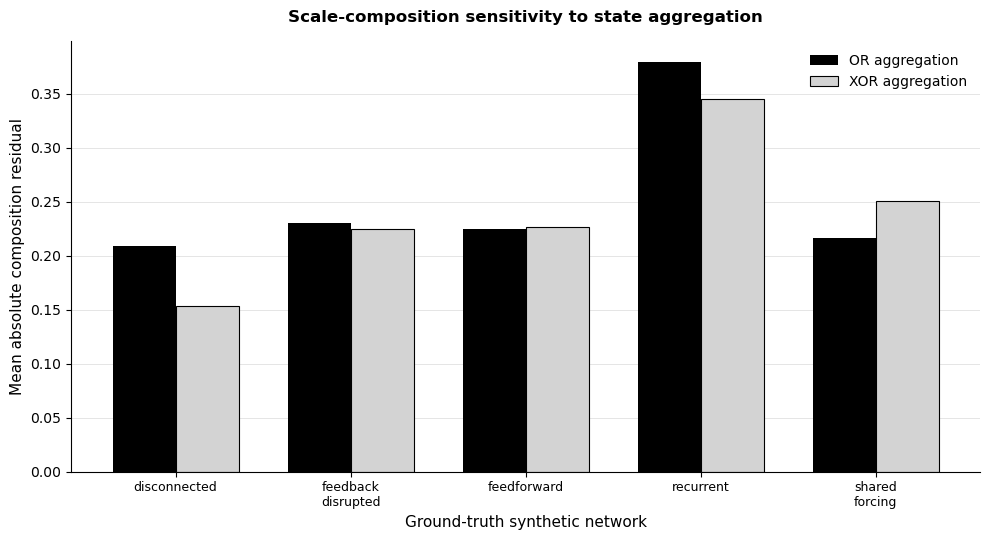


MULTISCALE COMPOSITION SUMMARY
          scenario aggregation  macro_feedback  n_windows  n_complete_residual  mean_signed_residual  mean_absolute_residual  rms_residual  mean_weighted_residual
      disconnected          OR           False       7937                 7937             -0.144916                0.208858      0.280921               -0.146910
      disconnected         XOR           False       7937                 7937              0.082569                0.153856      0.249117                0.099907
feedback_disrupted          OR           False       7937                 7937             -0.105042                0.230212      0.303503               -0.105505
feedback_disrupted         XOR           False       7937                 7937              0.061980                0.225019      0.330151                0.063820
       feedforward          OR           False       7937                 7937             -0.106296                0.224818      0.300036               

In [24]:

# ============================================================
# SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
# SCRIPT 22 — INTEGRATED MULTISCALE COMPOSITION ANALYSIS
#
# Components:
# 1. Higher-scale state construction
# 2. Macro-network topology verification
# 3. Higher-scale Shannon entropy
# 4. Higher-scale uncertainty gradients
# 5. Higher-scale recursive information gain
# 6. Independent higher-scale curvature
# 7. Multiscale composition residual
# 8. Aggregation-method sensitivity analysis
# 9. Descriptive scientific tables
# 10. Publication-style figure
# ============================================================

from pathlib import Path
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Load project and previously validated modules
# ------------------------------------------------------------

ROOT = Path.cwd().resolve()
SOURCE = ROOT / "src"

if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

from senome.estimators.entropy import (
    windowed_shannon_entropy
)

from senome.estimators.uncertainty import (
    estimate_uncertainty_gradient,
    normalize_uncertainty
)

from senome.estimators.recursive_gain import (
    estimate_recursive_gain,
    identify_recurrent_sources
)

DATA_DIR = ROOT / "data/processed"
RAW_DIR = ROOT / "data/synthetic"
TABLE_DIR = ROOT / "results/tables"
FIGURE_DIR = ROOT / "results/figures"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

model_path = ROOT / "configs/model_specification.json"
calibration_path = ROOT / "configs/g0_calibration_v1.json"
manifest_path = (
    ROOT / "results/logs/synthetic_dataset_manifest.json"
)

def sha256_file(path):
    digest = hashlib.sha256()

    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(1048576), b""
        ):
            digest.update(chunk)

    return digest.hexdigest()

with model_path.open("r", encoding="utf-8") as f:
    model = json.load(f)

with calibration_path.open("r", encoding="utf-8") as f:
    calibration = json.load(f)

with manifest_path.open("r", encoding="utf-8") as f:
    manifest = json.load(f)

assert (
    calibration["model_specification_sha256"]
    == sha256_file(model_path)
), "Model differs from frozen calibration."

# ------------------------------------------------------------
# 2. Read fixed mathematical parameters
# ------------------------------------------------------------

nodes = tuple(model["nodes"])

assert nodes == ("P1", "P2", "P3")

alpha = float(model["curvature"]["alpha"])
beta = float(model["curvature"]["beta"])
g0 = float(calibration["g0"])

window_size = int(
    model["time"]["window_samples"]
)

dt = float(
    model["time"]["sampling_interval"]
)

tau0 = float(
    model["geometry"]["characteristic_time"]
)

ell0 = float(
    model["geometry"]["characteristic_length"]
)

assert alpha == float(calibration["alpha"])
assert beta == float(calibration["beta"])
assert window_size == calibration["window_samples"]
assert tau0 == calibration["characteristic_time"]
assert ell0 == calibration["characteristic_length"]
assert np.isfinite(g0) and g0 > 0

# ------------------------------------------------------------
# 3. Define higher-scale nodes
# ------------------------------------------------------------

# Aggregate P1 and P2 into M12.
# Retain P3 as M3.
#
# These groups are defined independently of
# observed curvature and GAC.

macro_nodes = ("M12", "M3")

groups = (
    (0, 1),
    (2,)
)

group_index = {
    0: 0,
    1: 0,
    2: 1
}

# Higher-scale spatial coordinates are the
# mean coordinates of each original group.

original_positions = np.array([
    model["coordinates"][node]
    for node in nodes
], dtype=float)

macro_positions = np.array([
    np.mean(original_positions[list(group)])
    for group in groups
])

macro_spatial_edges = [
    ["M12", "M3"]
]

# Two sensitivity conditions.
#
# OR:  M12 = P1 OR P2
# XOR: M12 = P1 XOR P2
#
# Both mappings yield binary macrostates.
# Neither is claimed to be biologically privileged.

aggregation_methods = ("OR", "XOR")

# ------------------------------------------------------------
# 4. Define higher-scale state construction
# ------------------------------------------------------------

def create_macro_states(states, method):

    assert states.ndim == 2
    assert states.shape[1] == 3
    assert np.isin(states, [0, 1]).all()

    if method == "OR":

        first = np.logical_or(
            states[:, 0],
            states[:, 1]
        )

    elif method == "XOR":

        first = np.logical_xor(
            states[:, 0],
            states[:, 1]
        )

    else:

        raise ValueError(
            f"Unsupported aggregation: {method}"
        )

    second = states[:, 2].astype(bool)

    macro = np.column_stack([
        first,
        second
    ]).astype(np.uint8)

    assert macro.shape == (
        len(states), 2
    )

    assert np.isin(macro, [0, 1]).all()

    return macro

# ------------------------------------------------------------
# 5. Construct the coarse directed topology
# ------------------------------------------------------------

def create_macro_adjacency(micro_adjacency):

    assert micro_adjacency.shape == (3, 3)

    macro_adjacency = np.zeros(
        (2, 2),
        dtype=float
    )

    for source in range(3):

        for target in range(3):

            if micro_adjacency[source, target] == 0:
                continue

            macro_source = group_index[source]
            macro_target = group_index[target]

            # Internal group edges are absorbed into
            # the coarse state representation.

            if macro_source != macro_target:

                macro_adjacency[
                    macro_source,
                    macro_target
                ] = 1.0

    return macro_adjacency

# ------------------------------------------------------------
# 6. Define the curvature projection
# ------------------------------------------------------------

def project_micro_curvature(K):

    assert K.ndim == 2
    assert K.shape[1] == 3

    projected = np.column_stack([
        (K[:, 0] + K[:, 1]) / 2.0,
        K[:, 2]
    ])

    return projected

# Group-size weights preserve the original
# three-node arithmetic mean under projection.

macro_weights = np.array([
    2.0 / 3.0,
    1.0 / 3.0
])

np.testing.assert_allclose(
    macro_weights.sum(),
    1.0
)

# ------------------------------------------------------------
# 7. Define safe archive persistence
# ------------------------------------------------------------

def save_or_verify(path, arrays):

    if path.exists():

        with np.load(
            path,
            allow_pickle=False
        ) as previous:

            assert set(previous.files) == set(arrays)

            for key, expected in arrays.items():

                np.testing.assert_array_equal(
                    previous[key],
                    expected,
                    err_msg=(
                        f"Existing data differs: "
                        f"{path.name}/{key}"
                    )
                )

        return "EXISTING FILE VERIFIED"

    np.savez_compressed(
        path,
        **arrays
    )

    with np.load(
        path,
        allow_pickle=False
    ) as saved:

        assert set(saved.files) == set(arrays)

        for key, expected in arrays.items():

            np.testing.assert_array_equal(
                saved[key],
                expected
            )

    return "SAVED AND VERIFIED"

# ------------------------------------------------------------
# 8. Initialize study records
# ------------------------------------------------------------

summary_rows = []
node_rows = []

print("=" * 72)
print("SENOME–HYPERSENOME MULTISCALE COMPOSITION")
print("=" * 72)

print(f"Frozen g0: {g0:.10f}")
print(f"Alpha: {alpha}")
print(f"Beta: {beta}")
print(f"Micro nodes: {nodes}")
print(f"Macro nodes: {macro_nodes}")
print(f"Aggregation methods: {aggregation_methods}")

# ------------------------------------------------------------
# 9. Process each scenario
# ------------------------------------------------------------

for scenario in sorted(model["scenarios"]):

    print(
        f"\nNETWORK: {scenario}",
        flush=True
    )

    raw_record = manifest["datasets"][scenario]
    raw_path = ROOT / raw_record["file"]

    curvature_path = (
        DATA_DIR / f"{scenario}_curvature_v1.npz"
    )

    assert raw_path.is_file()
    assert curvature_path.is_file()

    assert (
        sha256_file(raw_path)
        == raw_record["sha256"]
    )

    with np.load(
        raw_path,
        allow_pickle=False
    ) as data:

        states = data["states"].copy()

        common_input = data[
            "common_input"
        ].copy()

        micro_adjacency = data[
            "true_adjacency"
        ].copy()

        raw_names = tuple(
            data["node_names"].tolist()
        )

    with np.load(
        curvature_path,
        allow_pickle=False
    ) as data:

        micro_K = data[
            "curvature"
        ].copy()

        micro_indices = data[
            "end_sample_indices"
        ].copy()

        micro_complete = data[
            "complete_window_mask"
        ].copy()

        micro_gac = data[
            "gac"
        ].copy()

        curvature_names = tuple(
            data["node_names"].tolist()
        )

    assert raw_names == nodes
    assert curvature_names == nodes

    assert len(common_input) == len(states) - 1

    np.testing.assert_array_equal(
        micro_complete,
        np.isfinite(micro_K).all(axis=1)
    )

    # --------------------------------------------------------
    # 10. Calculate the coarse directed network
    # --------------------------------------------------------

    macro_A = create_macro_adjacency(
        micro_adjacency
    )

    macro_graph = nx.from_numpy_array(
        macro_A,
        create_using=nx.DiGraph
    )

    macro_cycles = list(
        nx.simple_cycles(macro_graph)
    )

    has_macro_feedback = any(
        len(cycle) >= 2
        for cycle in macro_cycles
    )

    expected_feedback = (
        scenario == "recurrent"
    )

    assert (
        has_macro_feedback == expected_feedback
    ), (
        f"Unexpected coarse topology in {scenario}"
    )

    macro_sources = identify_recurrent_sources(
        macro_nodes,
        macro_A
    )

    # --------------------------------------------------------
    # 11. Process each aggregation method
    # --------------------------------------------------------

    for method in aggregation_methods:

        print(
            f"  Aggregation: {method}",
            flush=True
        )

        macro_states = create_macro_states(
            states,
            method
        )

        # ----------------------------------------------------
        # 12. Calculate macrostate entropy
        # ----------------------------------------------------

        entropy = windowed_shannon_entropy(
            symbols=macro_states,
            window_samples=window_size,
            alphabet_size=2
        )

        assert np.isfinite(
            entropy.s_normalized
        ).all()

        # ----------------------------------------------------
        # 13. Calculate macro uncertainty gradients
        # ----------------------------------------------------

        uncertainty = estimate_uncertainty_gradient(
            s_normalized=entropy.s_normalized,
            end_sample_indices=entropy.end_sample_indices,
            node_names=macro_nodes,
            coordinates=macro_positions,
            spatial_edges=macro_spatial_edges,
            sampling_interval=dt,
            characteristic_time=tau0,
            characteristic_length=ell0
        )

        # Apply the SAME frozen calibration reference
        # used at the fine scale.
        #
        # This avoids introducing a separately fitted
        # macro-scale normalization constant.

        macro_g = normalize_uncertainty(
            uncertainty.g_raw,
            g0
        )

        # ----------------------------------------------------
        # 14. Recalculate higher-scale recursive gain
        # ----------------------------------------------------

        gain = estimate_recursive_gain(
            states=macro_states,
            common_input=common_input,
            node_names=macro_nodes,
            adjacency=macro_A,
            window_samples=window_size,
            horizon=1
        )

        macro_lambda = gain.lambda_normalized[1:]

        macro_identifiable = (
            gain.identifiable_mask[1:]
        )

        macro_gain_indices = (
            gain.end_sample_indices[1:]
        )

        # ----------------------------------------------------
        # 15. Verify time alignment across scales
        # ----------------------------------------------------

        np.testing.assert_array_equal(
            macro_gain_indices,
            uncertainty.end_sample_indices
        )

        np.testing.assert_array_equal(
            macro_gain_indices,
            micro_indices
        )

        assert macro_lambda.shape == macro_g.shape

        assert macro_lambda.shape == (
            len(micro_indices), 2
        )

        # ----------------------------------------------------
        # 16. Calculate curvature from macrostates
        # ----------------------------------------------------

        macro_K = (
            alpha * macro_lambda
            - beta * macro_g
        )

        macro_K[
            ~macro_identifiable
        ] = np.nan

        assert np.isfinite(
            macro_K[macro_identifiable]
        ).all()

        # ----------------------------------------------------
        # 17. Project fine-scale curvature upward
        # ----------------------------------------------------

        projected_K = project_micro_curvature(
            micro_K
        )

        assert projected_K.shape == macro_K.shape

        # Verify mean conservation of the projection
        # for complete fine-scale windows.

        if micro_complete.any():

            projected_gac = (
                projected_K[micro_complete]
                @ macro_weights
            )

            np.testing.assert_allclose(
                projected_gac,
                micro_gac[micro_complete],
                rtol=0,
                atol=1e-12
            )

        # ----------------------------------------------------
        # 18. Calculate the multiscale residual
        # ----------------------------------------------------

        # E = K[coarse observations] - P(K[fine observations])

        composition_residual = (
            macro_K - projected_K
        )

        residual_identifiable = (
            np.isfinite(macro_K)
            & np.isfinite(projected_K)
        )

        assert np.isfinite(
            composition_residual[
                residual_identifiable
            ]
        ).all()

        # Independently verify the composition identity.

        np.testing.assert_allclose(
            (
                composition_residual
                + projected_K
            )[residual_identifiable],
            macro_K[residual_identifiable],
            rtol=0,
            atol=1e-12
        )

        # ----------------------------------------------------
        # 19. Calculate weighted aggregate residual
        # ----------------------------------------------------

        complete_residual = (
            residual_identifiable.all(axis=1)
        )

        weighted_residual = np.full(
            len(micro_indices),
            np.nan,
            dtype=float
        )

        if complete_residual.any():

            weighted_residual[
                complete_residual
            ] = (
                composition_residual[
                    complete_residual
                ] @ macro_weights
            )

        # ----------------------------------------------------
        # 20. Record descriptive summaries
        # ----------------------------------------------------

        valid_values = composition_residual[
            residual_identifiable
        ]

        if valid_values.size:

            mean_signed = float(
                np.mean(valid_values)
            )

            mean_absolute = float(
                np.mean(np.abs(valid_values))
            )

            rms_residual = float(
                np.sqrt(
                    np.mean(valid_values ** 2)
                )
            )

        else:

            mean_signed = float("nan")
            mean_absolute = float("nan")
            rms_residual = float("nan")

        summary_rows.append({
            "scenario": scenario,
            "aggregation": method,
            "macro_feedback": has_macro_feedback,
            "n_windows": len(micro_indices),
            "n_complete_residual": int(
                complete_residual.sum()
            ),
            "mean_signed_residual": mean_signed,
            "mean_absolute_residual": mean_absolute,
            "rms_residual": rms_residual,
            "mean_weighted_residual": (
                float(np.nanmean(weighted_residual))
                if complete_residual.any()
                else float("nan")
            ),
        })

        for j, macro_node in enumerate(macro_nodes):

            valid = residual_identifiable[:, j]

            values = composition_residual[
                valid, j
            ]

            node_rows.append({
                "scenario": scenario,
                "aggregation": method,
                "macro_node": macro_node,
                "n_identifiable": int(valid.sum()),
                "mean_macro_lambda": (
                    float(np.mean(macro_lambda[valid, j]))
                    if valid.any() else float("nan")
                ),
                "mean_macro_curvature": (
                    float(np.mean(macro_K[valid, j]))
                    if valid.any() else float("nan")
                ),
                "mean_projected_curvature": (
                    float(np.mean(projected_K[valid, j]))
                    if valid.any() else float("nan")
                ),
                "mean_composition_residual": (
                    float(np.mean(values))
                    if valid.any() else float("nan")
                ),
            })

        # ----------------------------------------------------
        # 21. Save all numerical results
        # ----------------------------------------------------

        output_path = (
            DATA_DIR
            / f"{scenario}_{method.lower()}_composition_v1.npz"
        )

        arrays = {
            "macro_states": macro_states,
            "macro_adjacency": macro_A,
            "macro_entropy_bits": entropy.S_bits,
            "macro_g_normalized": macro_g,
            "macro_lambda": macro_lambda,
            "macro_curvature": macro_K,
            "projected_micro_curvature": projected_K,
            "composition_residual": composition_residual,
            "weighted_residual": weighted_residual,
            "residual_identifiable": residual_identifiable,
            "complete_residual_mask": complete_residual,
            "end_sample_indices": macro_gain_indices,
            "macro_node_names": np.asarray(macro_nodes),
            "aggregation_method": np.asarray(method),
            "frozen_g0": np.asarray(g0),
            "raw_dataset_sha256": np.asarray(
                sha256_file(raw_path)
            ),
            "micro_curvature_sha256": np.asarray(
                sha256_file(curvature_path)
            ),
            "model_sha256": np.asarray(
                sha256_file(model_path)
            ),
        }

        status = save_or_verify(
            output_path,
            arrays
        )

        print(
            f"    {status}",
            flush=True
        )

        print(
            f"    Mean |composition residual|: "
            f"{mean_absolute:.6f}",
            flush=True
        )

# ------------------------------------------------------------
# 22. Build scientific summary tables
# ------------------------------------------------------------

summary = pd.DataFrame(summary_rows)
node_summary = pd.DataFrame(node_rows)

assert len(summary) == 10
assert len(node_summary) == 20

summary_path = (
    TABLE_DIR
    / "multiscale_composition_summary_v1.csv"
)

node_path = (
    TABLE_DIR
    / "multiscale_composition_nodes_v1.csv"
)

def save_csv_without_overwrite(df, path):

    csv_text = df.to_csv(
        index=False,
        float_format="%.12g"
    )

    if path.exists():

        assert (
            path.read_text(encoding="utf-8")
            == csv_text
        ), f"Existing table differs: {path.name}"

    else:

        path.write_text(
            csv_text,
            encoding="utf-8"
        )

save_csv_without_overwrite(
    summary,
    summary_path
)

save_csv_without_overwrite(
    node_summary,
    node_path
)

# ------------------------------------------------------------
# 23. Generate publication-style comparison figure
# ------------------------------------------------------------

# This figure displays descriptive composition
# differences. It does not display significance tests.

ordered_scenarios = sorted(
    model["scenarios"]
)

plot_data = summary.pivot(
    index="scenario",
    columns="aggregation",
    values="mean_absolute_residual"
).reindex(ordered_scenarios)

fig, ax = plt.subplots(
    figsize=(10, 5.5)
)

x = np.arange(
    len(ordered_scenarios)
)

bar_width = 0.36

ax.bar(
    x - bar_width / 2,
    plot_data["OR"].values,
    width=bar_width,
    color="black",
    label="OR aggregation"
)

ax.bar(
    x + bar_width / 2,
    plot_data["XOR"].values,
    width=bar_width,
    color="lightgray",
    edgecolor="black",
    linewidth=0.8,
    label="XOR aggregation"
)

ax.set_xticks(x)

ax.set_xticklabels(
    [
        name.replace("_", "\n")
        for name in ordered_scenarios
    ],
    fontsize=9
)

ax.set_ylabel(
    "Mean absolute composition residual",
    fontsize=11
)

ax.set_xlabel(
    "Ground-truth synthetic network",
    fontsize=11
)

ax.set_title(
    "Scale-composition sensitivity to state aggregation",
    fontsize=12,
    fontweight="bold",
    pad=14
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    color="0.88",
    linewidth=0.6
)

ax.set_axisbelow(True)

ax.legend(
    frameon=False,
    fontsize=10
)

fig.tight_layout()

figure_png = (
    FIGURE_DIR
    / "multiscale_composition_v1.png"
)

figure_pdf = (
    FIGURE_DIR
    / "multiscale_composition_v1.pdf"
)

fig.savefig(
    figure_png,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 24. Display final numerical results
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("MULTISCALE COMPOSITION SUMMARY")
print("=" * 72)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\n" + "=" * 72)
print("NODE-LEVEL COMPOSITION SUMMARY")
print("=" * 72)

print(
    node_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 25. Final verification
# ------------------------------------------------------------

assert figure_png.is_file()
assert figure_pdf.is_file()

assert summary_path.is_file()
assert node_path.is_file()

print("\n" + "=" * 72)
print("[PASS] Five network scenarios analyzed")
print("[PASS] Two aggregation definitions evaluated")
print("[PASS] Coarse directed topology independently constructed")
print("[PASS] Higher-scale entropy recalculated")
print("[PASS] Higher-scale uncertainty gradients recalculated")
print("[PASS] Higher-scale recursive gain recalculated")
print("[PASS] Higher-scale informational curvature calculated")
print("[PASS] Fine-scale curvature independently projected")
print("[PASS] Multiscale composition residual calculated")
print("[PASS] Temporal correspondence verified")
print("[PASS] Frozen normalization reference retained")
print("[PASS] Aggregation sensitivity quantified")
print("[PASS] Scientific summary tables archived")
print("[PASS] Black-and-white figure generated")
print("=" * 72)
print("SCRIPT 22: SUCCESSFULLY COMPLETED")
print("=" * 72)


INDEPENDENT MONTE CARLO VALIDATION
[PASS] Fast estimator matches original recursive-gain estimator
[PROGRESS] 8/48 replicates completed | 2.8 seconds
[PROGRESS] 16/48 replicates completed | 5.5 seconds
[PROGRESS] 24/48 replicates completed | 8.3 seconds
[PROGRESS] 32/48 replicates completed | 11.1 seconds
[PROGRESS] 40/48 replicates completed | 13.9 seconds
[PROGRESS] 48/48 replicates completed | 16.7 seconds


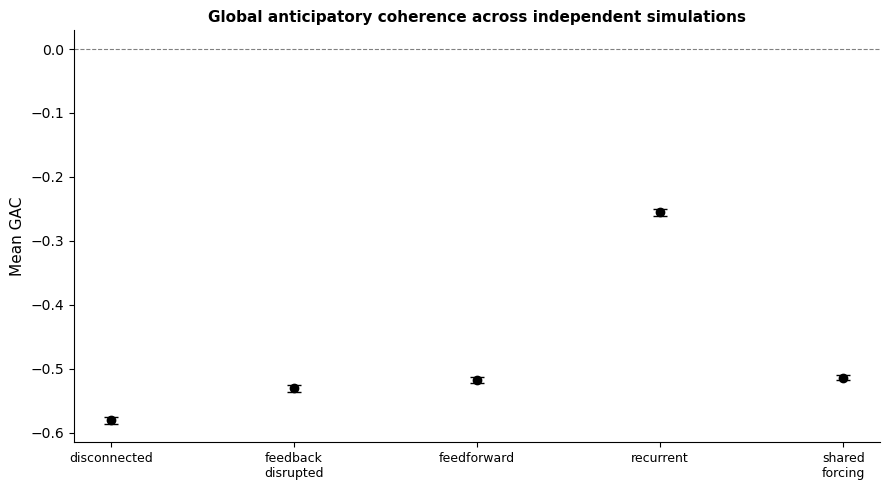

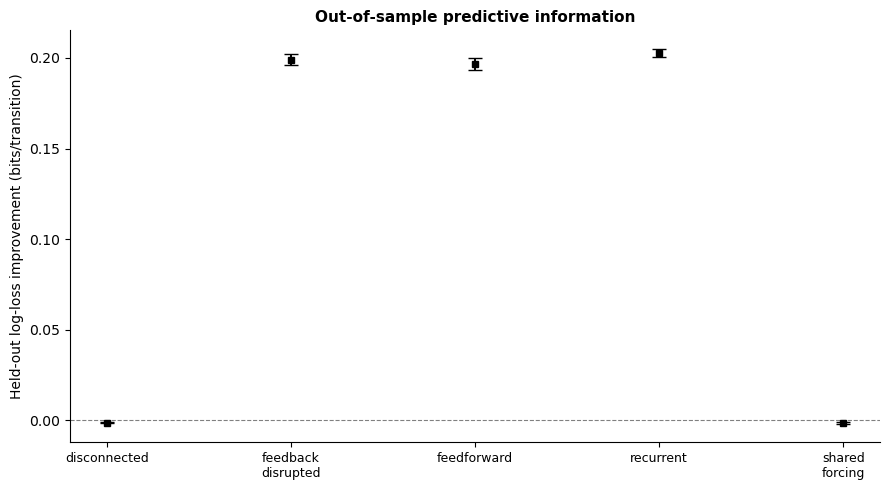


MONTE CARLO GAC AND PREDICTIVE VALIDATION
          scenario  mean_gac_mean  mean_gac_ci_low  mean_gac_ci_high  heldout_information_gain_bits_mean  heldout_information_gain_bits_ci_low  heldout_information_gain_bits_ci_high
      disconnected      -0.580900        -0.585725         -0.576171                           -0.001372                             -0.001752                              -0.001004
feedback_disrupted      -0.530421        -0.535806         -0.525010                            0.198949                              0.195888                               0.202051
       feedforward      -0.517350        -0.522282         -0.512187                            0.196765                              0.193440                               0.200129
         recurrent      -0.255473        -0.261178         -0.249919                            0.202743                              0.200651                               0.204895
    shared_forcing      -0.513778        -0.518

In [25]:

# ============================================================
# SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
# STAGE 4 | SCRIPT 23
#
# Integrated Monte Carlo Statistical Validation
#
# 48 independent realizations per network
# 5 ground-truth network scenarios
# 95% replicate-level bootstrap confidence intervals
# Held-out predictive information analysis
# Negative controls
# Curvature and calibration sensitivity
# Publication-style figures
# ============================================================

from pathlib import Path
import copy
import hashlib
import json
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.special import xlogy

ROOT = Path.cwd().resolve()
SOURCE = ROOT / "src"

if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

from senome.models.dynamics import simulate_network
from senome.estimators.entropy import windowed_shannon_entropy
from senome.estimators.uncertainty import (
    estimate_uncertainty_gradient,
    normalize_uncertainty,
)
from senome.estimators.recursive_gain import (
    estimate_recursive_gain,
    identify_recurrent_sources,
)

TABLE_DIR = ROOT / "results/tables"
FIGURE_DIR = ROOT / "results/figures"
VALIDATION_DIR = ROOT / "results/validation"

for directory in [TABLE_DIR, FIGURE_DIR, VALIDATION_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load frozen research configuration
# ------------------------------------------------------------

model_path = ROOT / "configs/model_specification.json"
calibration_path = ROOT / "configs/g0_calibration_v1.json"
repro_path = ROOT / "configs/reproducibility.json"

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1048576), b""):
            digest.update(chunk)
    return digest.hexdigest()

with model_path.open("r", encoding="utf-8") as f:
    model = json.load(f)

with calibration_path.open("r", encoding="utf-8") as f:
    calibration = json.load(f)

with repro_path.open("r", encoding="utf-8") as f:
    reproducibility = json.load(f)

assert (
    calibration["model_specification_sha256"]
    == sha256_file(model_path)
)

alpha0 = float(model["curvature"]["alpha"])
beta0 = float(model["curvature"]["beta"])
g0 = float(calibration["g0"])

assert alpha0 == calibration["alpha"]
assert beta0 == calibration["beta"]
assert np.isfinite(g0) and g0 > 0

nodes = tuple(model["nodes"])
n_nodes = len(nodes)

assert n_nodes == 3

coordinates = np.array(
    [model["coordinates"][node] for node in nodes],
    dtype=float,
)

geometry = model["geometry"]

tau0 = float(geometry["characteristic_time"])
ell0 = float(geometry["characteristic_length"])
dt = float(model["time"]["sampling_interval"])

window_size = int(model["time"]["window_samples"])

assert window_size == 256

# ------------------------------------------------------------
# 2. Monte Carlo experiment settings
# ------------------------------------------------------------

N_REPLICATES = 48
RECORDED_TRANSITIONS = 4096
N_BOOTSTRAP = 3000

# Replicates are the unit of statistical inference.
# Overlapping time windows are NOT independent samples.

mc_model = copy.deepcopy(model)

mc_model["time"]["recorded_samples"] = (
    RECORDED_TRANSITIONS
)

scenario_names = sorted(model["scenarios"])

master_seed = int(reproducibility["master_seed"])

def deterministic_seed(label):
    payload = (
        f"senome_mc_v1::{master_seed}::{label}"
    ).encode("utf-8")

    return int.from_bytes(
        hashlib.sha256(payload).digest()[:8],
        "little",
    )

replicate_seeds = [
    deterministic_seed(f"replicate::{r}")
    for r in range(N_REPLICATES)
]

assert len(set(replicate_seeds)) == N_REPLICATES
assert master_seed not in replicate_seeds
assert calibration["calibration_master_seed"] not in (
    replicate_seeds
)

bootstrap_rng = np.random.Generator(
    np.random.PCG64DXSM(
        np.random.SeedSequence(
            deterministic_seed("bootstrap")
        )
    )
)

# ------------------------------------------------------------
# 3. Fast windowed categorical entropy
# ------------------------------------------------------------

def window_counts(labels, n_categories, n_transitions):
    """
    Count categorical observations in all overlapping
    windows using cumulative histograms.
    """

    labels = np.asarray(labels, dtype=np.int64)

    if labels.ndim != 1:
        raise ValueError("Labels must be one-dimensional.")

    if np.any(labels < 0) or np.any(labels >= n_categories):
        raise ValueError("Invalid categorical labels.")

    if len(labels) < n_transitions:
        raise ValueError("Insufficient transitions.")

    indicator = (
        labels[:, None]
        == np.arange(n_categories)[None, :]
    ).astype(np.int64)

    cumulative = np.vstack([
        np.zeros((1, n_categories), dtype=np.int64),
        np.cumsum(indicator, axis=0, dtype=np.int64),
    ])

    return (
        cumulative[n_transitions:]
        - cumulative[:-n_transitions]
    )


def histogram_entropy(counts):
    """Shannon entropy in bits, one value per row."""

    counts = np.asarray(counts, dtype=float)

    totals = counts.sum(axis=1, keepdims=True)

    if np.any(totals <= 0):
        raise ValueError("Empty histogram encountered.")

    p = counts / totals

    return -np.sum(
        xlogy(p, p),
        axis=1
    ) / np.log(2.0)


# ------------------------------------------------------------
# 4. Efficient recursive-gain calculation
# ------------------------------------------------------------

def fast_recursive_gain(states, common_input, adjacency):
    """
    Binary plug-in conditional-information estimator.

    Matches the one-step estimator from Script 16,
    using vectorized sliding-window contingency counts.

    The topology is supplied as known ground truth.
    """

    X = np.asarray(states, dtype=np.int64)
    U = np.asarray(common_input, dtype=np.int64)

    assert X.ndim == 2
    assert X.shape[1] == len(nodes)
    assert len(U) == len(X) - 1

    assert np.isin(X, [0, 1]).all()
    assert np.isin(U, [0, 1]).all()

    n_transitions = window_size - 1
    n_windows = len(X) - window_size + 1

    output = np.zeros(
        (n_windows, len(nodes)),
        dtype=float,
    )

    recurrent = identify_recurrent_sources(
        nodes,
        adjacency,
    )

    node_index = {
        name: i for i, name in enumerate(nodes)
    }

    for j, node in enumerate(nodes):

        sources = recurrent[node]

        if len(sources) == 0:
            # Known absence of cyclic feedback.
            output[:, j] = 0.0
            continue

        assert len(sources) == 1, (
            "This fast implementation supports "
            "one recurrent source per target."
        )

        source_index = node_index[sources[0]]

        previous_target = X[:-1, j]
        future_target = X[1:, j]
        previous_source = X[:-1, source_index]

        # Baseline condition: target past and common input.
        z = previous_target + 2 * U

        # Joint category encodings:
        # Z:             4 categories
        # (Z,Y):         8 categories
        # (Z,X):         8 categories
        # (Z,X,Y):      16 categories

        zy = z + 4 * future_target
        zx = z + 4 * previous_source
        zxy = zx + 8 * future_target

        H_z = histogram_entropy(
            window_counts(z, 4, n_transitions)
        )

        H_zy = histogram_entropy(
            window_counts(zy, 8, n_transitions)
        )

        H_zx = histogram_entropy(
            window_counts(zx, 8, n_transitions)
        )

        H_zxy = histogram_entropy(
            window_counts(zxy, 16, n_transitions)
        )

        H0 = H_zy - H_z
        H1 = H_zxy - H_zx

        H0 = np.maximum(H0, 0.0)
        H1 = np.maximum(H1, 0.0)

        T = np.clip(H0 - H1, 0.0, H0)

        lam = np.full(n_windows, np.nan)

        valid = H0 > 1e-12

        lam[valid] = (
            T[valid] / H0[valid]
        )

        output[:, j] = lam

    finite = output[np.isfinite(output)]

    assert np.all(finite >= -1e-12)
    assert np.all(finite <= 1 + 1e-12)

    return output

# ------------------------------------------------------------
# 5. Cross-check against the original estimator
# ------------------------------------------------------------

reference_simulation = simulate_network(
    spec=mc_model,
    scenario_name="recurrent",
    master_seed=replicate_seeds[0],
)

short_states = reference_simulation.states[:320]
short_input = reference_simulation.common_input[:319]

reference = estimate_recursive_gain(
    states=short_states,
    common_input=short_input,
    node_names=nodes,
    adjacency=reference_simulation.true_adjacency,
    window_samples=window_size,
    horizon=1,
)

fast_result = fast_recursive_gain(
    short_states,
    short_input,
    reference_simulation.true_adjacency,
)

np.testing.assert_allclose(
    fast_result,
    reference.lambda_normalized,
    rtol=0,
    atol=1e-10,
    equal_nan=True,
)

print("=" * 72)
print("INDEPENDENT MONTE CARLO VALIDATION")
print("=" * 72)
print("[PASS] Fast estimator matches original recursive-gain estimator")

# ------------------------------------------------------------
# 6. Held-out predictive-information validation
# ------------------------------------------------------------

def predictive_improvement(states, common_input, adjacency):
    """
    Evaluate whether an additional source-state predictor
    improves held-out conditional log loss.

    Training: first half of transitions
    Evaluation: second half of transitions

    Positive improvement indicates better out-of-sample
    prediction when the source is included.

    For disconnected and shared-forcing controls, use a
    deliberately nonexistent P1 -> P2 candidate edge.
    """

    X = np.asarray(states, dtype=np.int64)
    U = np.asarray(common_input, dtype=np.int64)

    predictors = X[:-1]
    outcomes = X[1:]

    n = len(U)
    split = n // 2

    edges = [
        (i, j)
        for i in range(len(nodes))
        for j in range(len(nodes))
        if adjacency[i, j] != 0
    ]

    if not edges:
        edges = [(0, 1)]

    improvements = []

    for source, target in edges:

        y = outcomes[:, target]

        baseline_code = (
            predictors[:, target] + 2 * U
        )

        augmented_code = (
            baseline_code
            + 4 * predictors[:, source]
        )

        def heldout_loss(codes, n_groups):

            train_codes = codes[:split]
            train_y = y[:split]

            # Group-specific Bernoulli probabilities,
            # with Jeffreys prior smoothing.
            joint_codes = (
                2 * train_codes + train_y
            )

            counts = np.bincount(
                joint_codes,
                minlength=2 * n_groups,
            ).reshape(n_groups, 2)

            probabilities = (
                counts[:, 1] + 0.5
            ) / (
                counts.sum(axis=1) + 1.0
            )

            p_test = probabilities[codes[split:]]
            y_test = y[split:]

            return float(
                -np.mean(
                    y_test * np.log2(p_test)
                    + (1 - y_test) * np.log2(1 - p_test)
                )
            )

        baseline_loss = heldout_loss(
            baseline_code, 4
        )

        augmented_loss = heldout_loss(
            augmented_code, 8
        )

        improvements.append(
            baseline_loss - augmented_loss
        )

    return float(np.mean(improvements))

# ------------------------------------------------------------
# 7. Prepare sensitivity settings
# ------------------------------------------------------------

# Exploratory, not confirmatory parameter choices.

coefficient_settings = [
    ("default", alpha0, beta0),
    ("lower_alpha", 0.75 * alpha0, beta0),
    ("higher_beta", alpha0, 1.25 * beta0),
]

g0_multipliers = [0.5, 1.0, 2.0]

results = []
sensitivity_rows = []

start_time = time.perf_counter()

# ------------------------------------------------------------
# 8. Run independent Monte Carlo simulations
# ------------------------------------------------------------

for rep in range(N_REPLICATES):

    seed = replicate_seeds[rep]

    for scenario in scenario_names:

        simulation = simulate_network(
            spec=mc_model,
            scenario_name=scenario,
            master_seed=seed,
        )

        states = simulation.states
        common_input = simulation.common_input
        adjacency = simulation.true_adjacency

        # ----------------------------------------------------
        # 9. Recalculate entropy and uncertainty
        # ----------------------------------------------------

        entropy = windowed_shannon_entropy(
            symbols=states,
            window_samples=window_size,
            alphabet_size=2,
        )

        uncertainty = estimate_uncertainty_gradient(
            s_normalized=entropy.s_normalized,
            end_sample_indices=entropy.end_sample_indices,
            node_names=nodes,
            coordinates=coordinates,
            spatial_edges=geometry["spatial_edges"],
            sampling_interval=dt,
            characteristic_time=tau0,
            characteristic_length=ell0,
        )

        raw_g = uncertainty.g_raw

        # ----------------------------------------------------
        # 10. Recalculate recursive gain
        # ----------------------------------------------------

        lambda_full = fast_recursive_gain(
            states,
            common_input,
            adjacency,
        )

        # First entropy window lacks a backward temporal
        # derivative, so drop the first gain estimate.

        lam = lambda_full[1:]

        assert lam.shape == raw_g.shape

        identifiable = np.isfinite(lam)
        complete = identifiable.all(axis=1)

        assert complete.any(), (
            f"No complete curvature observations: "
            f"{scenario}, replicate {rep}"
        )

        # ----------------------------------------------------
        # 11. Estimate curvature and global coherence
        # ----------------------------------------------------

        g = normalize_uncertainty(raw_g, g0)

        K = alpha0 * lam - beta0 * g
        K[~identifiable] = np.nan

        gac_values = np.mean(K[complete], axis=1)

        mean_gac = float(np.mean(gac_values))

        # ----------------------------------------------------
        # 12. Evaluate held-out predictive gain
        # ----------------------------------------------------

        heldout_gain = predictive_improvement(
            states,
            common_input,
            adjacency,
        )

        results.append({
            "replicate": rep,
            "scenario": scenario,
            "seed": seed,
            "n_transitions": RECORDED_TRANSITIONS,
            "n_complete_windows": int(complete.sum()),
            "mean_lambda": float(
                np.mean(lam[complete])
            ),
            "mean_gradient": float(
                np.mean(g[complete])
            ),
            "mean_gac": mean_gac,
            "heldout_information_gain_bits": heldout_gain,
        })

        # ----------------------------------------------------
        # 13. Exploratory parameter sensitivity
        # ----------------------------------------------------

        for multiplier in g0_multipliers:

            g_alternative = normalize_uncertainty(
                raw_g,
                g0 * multiplier,
            )

            for label, a, b in coefficient_settings:

                alternative_K = (
                    a * lam - b * g_alternative
                )

                alternative_gac = float(
                    np.mean(
                        alternative_K[complete]
                    )
                )

                sensitivity_rows.append({
                    "replicate": rep,
                    "scenario": scenario,
                    "coefficient_setting": label,
                    "alpha": a,
                    "beta": b,
                    "g0_multiplier": multiplier,
                    "mean_gac": alternative_gac,
                })

    if (rep + 1) % 8 == 0:

        elapsed = time.perf_counter() - start_time

        print(
            f"[PROGRESS] {rep + 1}/{N_REPLICATES} "
            f"replicates completed | "
            f"{elapsed:.1f} seconds",
            flush=True,
        )

# ------------------------------------------------------------
# 14. Convert observations into replicate-level tables
# ------------------------------------------------------------

replicate_table = pd.DataFrame(results)
sensitivity_table = pd.DataFrame(sensitivity_rows)

assert len(replicate_table) == (
    N_REPLICATES * len(scenario_names)
)

assert len(sensitivity_table) == (
    N_REPLICATES
    * len(scenario_names)
    * len(g0_multipliers)
    * len(coefficient_settings)
)

assert np.isfinite(
    replicate_table[
        [
            "mean_lambda",
            "mean_gradient",
            "mean_gac",
            "heldout_information_gain_bits",
        ]
    ].to_numpy()
).all()

# ------------------------------------------------------------
# 15. Replicate-level bootstrap confidence intervals
# ------------------------------------------------------------

def bootstrap_mean_ci(values, rng, n_bootstrap):
    """
    Percentile bootstrap over independent simulation
    replicates, not overlapping observation windows.
    """

    values = np.asarray(values, dtype=float)

    assert len(values) == N_REPLICATES

    draw_indices = rng.integers(
        0,
        len(values),
        size=(n_bootstrap, len(values)),
    )

    means = values[draw_indices].mean(axis=1)

    lower, upper = np.quantile(
        means,
        [0.025, 0.975],
    )

    return (
        float(np.mean(values)),
        float(lower),
        float(upper),
    )

summary_rows = []

for scenario in scenario_names:

    subset = replicate_table.loc[
        replicate_table["scenario"] == scenario
    ]

    row = {
        "scenario": scenario,
        "n_replicates": N_REPLICATES,
    }

    for metric in [
        "mean_lambda",
        "mean_gradient",
        "mean_gac",
        "heldout_information_gain_bits",
    ]:

        estimate, lower, upper = bootstrap_mean_ci(
            subset[metric].to_numpy(),
            bootstrap_rng,
            N_BOOTSTRAP,
        )

        row[f"{metric}_mean"] = estimate
        row[f"{metric}_ci_low"] = lower
        row[f"{metric}_ci_high"] = upper

    summary_rows.append(row)

summary = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# 16. Between-network bootstrap contrasts
# ------------------------------------------------------------

# These are differences between separate stochastic
# realizations, not independent biological subjects.

contrasts = []

for comparator in [
    "feedback_disrupted",
    "shared_forcing",
    "feedforward",
    "disconnected",
]:

    recurrent = replicate_table.loc[
        replicate_table["scenario"] == "recurrent"
    ]

    other = replicate_table.loc[
        replicate_table["scenario"] == comparator
    ]

    for metric in [
        "mean_gac",
        "heldout_information_gain_bits",
    ]:

        a = recurrent[metric].to_numpy()
        b = other[metric].to_numpy()

        a_indices = bootstrap_rng.integers(
            0, len(a), size=(N_BOOTSTRAP, len(a))
        )

        b_indices = bootstrap_rng.integers(
            0, len(b), size=(N_BOOTSTRAP, len(b))
        )

        boot_difference = (
            a[a_indices].mean(axis=1)
            - b[b_indices].mean(axis=1)
        )

        ci = np.quantile(
            boot_difference, [0.025, 0.975]
        )

        contrasts.append({
            "comparison": f"recurrent - {comparator}",
            "metric": metric,
            "mean_difference": float(
                a.mean() - b.mean()
            ),
            "ci_low": float(ci[0]),
            "ci_high": float(ci[1]),
        })

contrast_table = pd.DataFrame(contrasts)

# ------------------------------------------------------------
# 17. Summarize parameter sensitivity
# ------------------------------------------------------------

sensitivity_summary = (
    sensitivity_table.groupby(
        [
            "scenario",
            "coefficient_setting",
            "alpha",
            "beta",
            "g0_multiplier",
        ],
        as_index=False,
    )["mean_gac"]
    .agg(["mean", "std"])
    .reset_index()
)

# ------------------------------------------------------------
# 18. Save reproducible numerical results
# ------------------------------------------------------------

def save_csv_safely(df, filename):

    path = TABLE_DIR / filename

    text = df.to_csv(
        index=False,
        float_format="%.12g",
    )

    if path.exists():

        assert (
            path.read_text(encoding="utf-8") == text
        ), f"Existing analysis differs: {filename}"

    else:

        path.write_text(
            text,
            encoding="utf-8",
        )

    return path


save_csv_safely(
    replicate_table,
    "monte_carlo_replicates_v1.csv",
)

save_csv_safely(
    summary,
    "monte_carlo_summary_v1.csv",
)

save_csv_safely(
    contrast_table,
    "monte_carlo_contrasts_v1.csv",
)

save_csv_safely(
    sensitivity_table,
    "monte_carlo_sensitivity_replicates_v1.csv",
)

save_csv_safely(
    sensitivity_summary,
    "monte_carlo_sensitivity_summary_v1.csv",
)

# ------------------------------------------------------------
# 19. Publication-style figure: Mean GAC
# ------------------------------------------------------------

plot_data = summary.set_index("scenario").loc[
    scenario_names
]

means = plot_data["mean_gac_mean"].to_numpy()

lower_errors = (
    means - plot_data["mean_gac_ci_low"].to_numpy()
)

upper_errors = (
    plot_data["mean_gac_ci_high"].to_numpy() - means
)

fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(scenario_names))

ax.errorbar(
    x,
    means,
    yerr=np.vstack([lower_errors, upper_errors]),
    fmt="o",
    color="black",
    ecolor="black",
    capsize=5,
    markersize=6,
    linewidth=1.4,
)

ax.axhline(
    0,
    color="gray",
    linewidth=0.8,
    linestyle="--",
)

ax.set_xticks(x)

ax.set_xticklabels(
    [s.replace("_", "\n") for s in scenario_names],
    fontsize=9,
)

ax.set_ylabel("Mean GAC", fontsize=11)

ax.set_title(
    "Global anticipatory coherence across independent simulations",
    fontsize=11,
    fontweight="bold",
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "monte_carlo_gac_v1.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_DIR / "monte_carlo_gac_v1.pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 20. Publication-style figure: Held-out information
# ------------------------------------------------------------

means = plot_data[
    "heldout_information_gain_bits_mean"
].to_numpy()

lower_errors = (
    means
    - plot_data[
        "heldout_information_gain_bits_ci_low"
    ].to_numpy()
)

upper_errors = (
    plot_data[
        "heldout_information_gain_bits_ci_high"
    ].to_numpy()
    - means
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.errorbar(
    x,
    means,
    yerr=np.vstack([lower_errors, upper_errors]),
    fmt="s",
    color="black",
    ecolor="black",
    capsize=5,
    markersize=5,
    linewidth=1.4,
)

ax.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=0.8,
)

ax.set_xticks(x)

ax.set_xticklabels(
    [s.replace("_", "\n") for s in scenario_names],
    fontsize=9,
)

ax.set_ylabel(
    "Held-out log-loss improvement (bits/transition)",
    fontsize=10,
)

ax.set_title(
    "Out-of-sample predictive information",
    fontsize=11,
    fontweight="bold",
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "monte_carlo_prediction_v1.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_DIR / "monte_carlo_prediction_v1.pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 21. Display results
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("MONTE CARLO GAC AND PREDICTIVE VALIDATION")
print("=" * 72)

display_columns = [
    "scenario",
    "mean_gac_mean",
    "mean_gac_ci_low",
    "mean_gac_ci_high",
    "heldout_information_gain_bits_mean",
    "heldout_information_gain_bits_ci_low",
    "heldout_information_gain_bits_ci_high",
]

print(
    summary[display_columns].to_string(
        index=False,
        float_format=lambda v: f"{v:.6f}",
    )
)

print("\n" + "=" * 72)
print("RECURRENT VS CONTROL NETWORK CONTRASTS")
print("=" * 72)

print(
    contrast_table.to_string(
        index=False,
        float_format=lambda v: f"{v:.6f}",
    )
)

print("\n" + "=" * 72)
print("FINAL MONTE CARLO VALIDATION")
print("=" * 72)
print(f"Independent replicates per scenario: {N_REPLICATES}")
print(f"Total simulated trajectories: {len(replicate_table)}")
print(f"Transitions per trajectory: {RECORDED_TRANSITIONS}")
print(f"Bootstrap iterations: {N_BOOTSTRAP}")
print("[PASS] Original and fast gain estimators agree")
print("[PASS] Independent Monte Carlo realizations completed")
print("[PASS] Shared-forcing and disconnected controls included")
print("[PASS] Held-out predictive information evaluated")
print("[PASS] Replicate-level bootstrap intervals calculated")
print("[PASS] Between-network contrasts calculated")
print("[PASS] Alpha, beta, and g0 sensitivity analyzed")
print("[PASS] Numerical tables archived")
print("[PASS] Two black-and-white scientific figures generated")
print("=" * 72)
print("SCRIPT 23: SUCCESSFULLY COMPLETED")
print("=" * 72)


SENOME–HYPERSENOME FINAL INTEGRATED VALIDATION
Independent replicates per condition: 32
Transitions per replicate: 3072
Bootstrap samples: 2000
Frozen g0: 0.0445901080
Conditions: 6

[PASS] Exact stationary population benchmarks calculated
[PASS] Recurrent network has positive population gain
[PASS] Zero-coupling cyclic null has zero population gain
[PASS] Accelerated estimator independently cross-checked
[PROGRESS] 4/32 replicates | 1.8 seconds
[PROGRESS] 8/32 replicates | 3.4 seconds
[PROGRESS] 12/32 replicates | 5.0 seconds
[PROGRESS] 16/32 replicates | 6.5 seconds
[PROGRESS] 20/32 replicates | 8.1 seconds
[PROGRESS] 24/32 replicates | 9.7 seconds
[PROGRESS] 28/32 replicates | 11.2 seconds
[PROGRESS] 32/32 replicates | 12.8 seconds

[PASS] Independent Monte Carlo simulations completed
[PASS] Transition parameters estimated independently


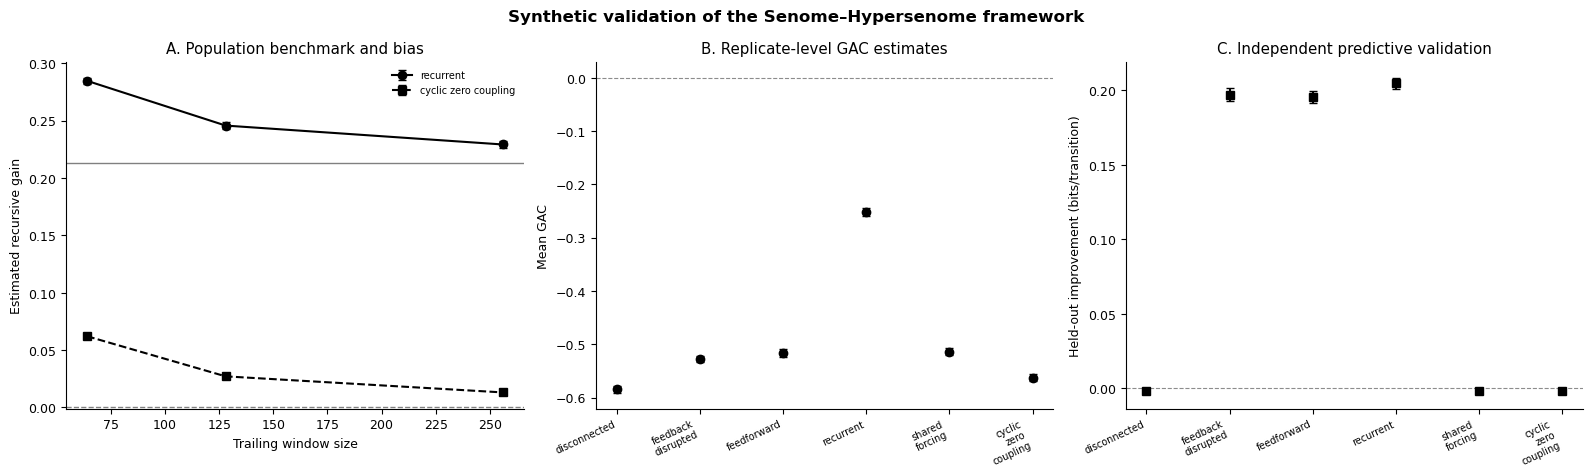


POPULATION RECURSIVE-GAIN BENCHMARK
            scenario node  population_H0_bits  population_T_bits  population_lambda  recurrent_sources
        disconnected   P1            0.942409           0.000000           0.000000                  0
        disconnected   P2            0.964386           0.000000           0.000000                  0
        disconnected   P3            0.942409           0.000000           0.000000                  0
  feedback_disrupted   P1            0.942409           0.000000           0.000000                  0
  feedback_disrupted   P2            0.956328           0.000000           0.000000                  0
  feedback_disrupted   P3            0.962571           0.000000           0.000000                  0
         feedforward   P1            0.942409           0.000000           0.000000                  0
         feedforward   P2            0.956328           0.000000           0.000000                  0
         feedforward   P3           

In [26]:

# ============================================================
# SENOME–HYPERSENOME COMPUTATIONAL FRAMEWORK
# INTEGRATED SCRIPTS 24–27
#
# FINAL SYNTHETIC VALIDATION
#
# 1. Exact population-information benchmark
# 2. Independent Monte Carlo simulations
# 3. Finite-sample recursive-gain bias
# 4. Cyclic-topology / zero-coupling negative control
# 5. Held-out predictive validation
# 6. Logistic transition-parameter recovery
# 7. Replicate-level bootstrap confidence intervals
# 8. Sensitivity to alpha, beta, and g0
# 9. Publication-quality figures and report
# 10. Reproducibility and provenance checks
# ============================================================

from pathlib import Path
from hashlib import sha256
import copy
import json
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.special import expit, xlogy
from scipy.optimize import minimize

ROOT = Path.cwd().resolve()
SRC = ROOT / "src"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from senome.models.dynamics import simulate_network
from senome.estimators.entropy import windowed_shannon_entropy
from senome.estimators.uncertainty import (
    estimate_uncertainty_gradient,
    normalize_uncertainty,
)
from senome.estimators.recursive_gain import (
    estimate_recursive_gain,
    identify_recurrent_sources,
)

OUT = ROOT / "results"
TABLES = OUT / "tables"
FIGURES = OUT / "figures"
VALIDATION = OUT / "validation"

for folder in (TABLES, FIGURES, VALIDATION):
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load frozen configuration
# ------------------------------------------------------------

MODEL_PATH = ROOT / "configs/model_specification.json"
CAL_PATH = ROOT / "configs/g0_calibration_v1.json"
REPRO_PATH = ROOT / "configs/reproducibility.json"

def checksum(path):
    digest = sha256()
    with path.open("rb") as f:
        for part in iter(lambda: f.read(1048576), b""):
            digest.update(part)
    return digest.hexdigest()

with MODEL_PATH.open(encoding="utf-8") as f:
    model = json.load(f)

with CAL_PATH.open(encoding="utf-8") as f:
    calibration = json.load(f)

with REPRO_PATH.open(encoding="utf-8") as f:
    reproducibility = json.load(f)

assert calibration["model_specification_sha256"] == checksum(
    MODEL_PATH
), "The model changed after calibration."

nodes = tuple(model["nodes"])
assert nodes == ("P1", "P2", "P3")

alpha0 = float(model["curvature"]["alpha"])
beta0 = float(model["curvature"]["beta"])
g0 = float(calibration["g0"])

assert alpha0 == float(calibration["alpha"])
assert beta0 == float(calibration["beta"])
assert np.isfinite(g0) and g0 > 0

window0 = int(model["time"]["window_samples"])
assert window0 == 256

geometry = model["geometry"]

positions = np.array(
    [model["coordinates"][node] for node in nodes],
    dtype=float,
)

tau0 = float(geometry["characteristic_time"])
ell0 = float(geometry["characteristic_length"])
dt = float(model["time"]["sampling_interval"])

assert tau0 == calibration["characteristic_time"]
assert ell0 == calibration["characteristic_length"]

# ------------------------------------------------------------
# 2. Prespecified final validation design
# ------------------------------------------------------------

N_REPLICATES = 32
TRANSITIONS = 3072
BOOTSTRAPS = 2000

WINDOW_SIZES = (64, 128, 256)

SCENARIOS = tuple(sorted(model["scenarios"]))

NULL_SCENARIO = "cyclic_zero_coupling"

ALL_SCENARIOS = SCENARIOS + (NULL_SCENARIO,)

BASE_SEED = int(reproducibility["master_seed"])

def independent_seed(label):
    payload = (
        f"senome_final_validation_v1::{BASE_SEED}::{label}"
    ).encode("utf-8")
    return int.from_bytes(
        sha256(payload).digest()[:8], "little"
    )

bootstrap_rng = np.random.Generator(
    np.random.PCG64DXSM(
        np.random.SeedSequence(
            independent_seed("bootstrap")
        )
    )
)

mc_model = copy.deepcopy(model)
mc_model["time"]["recorded_samples"] = TRANSITIONS

null_model = copy.deepcopy(mc_model)
null_model["dynamics"]["coupling_strength"] = 0.0

# The null retains recurrent graph topology but
# removes actual between-node coupling.

print("=" * 72)
print("SENOME–HYPERSENOME FINAL INTEGRATED VALIDATION")
print("=" * 72)
print(f"Independent replicates per condition: {N_REPLICATES}")
print(f"Transitions per replicate: {TRANSITIONS}")
print(f"Bootstrap samples: {BOOTSTRAPS}")
print(f"Frozen g0: {g0:.10f}")
print(f"Conditions: {len(ALL_SCENARIOS)}")
print("=" * 72)

start_time = time.perf_counter()

# ------------------------------------------------------------
# 3. Exact finite-state population benchmark
# ------------------------------------------------------------

# The simulator has three binary nodes.
# Therefore, only 2^3 = 8 network states exist.
#
# We can enumerate every state and transition,
# construct its stationary distribution, and
# calculate population conditional information.
#
# This benchmark does not use the entropy or
# recursive-gain estimation modules.

binary_states = np.array([
    [(code >> j) & 1 for j in range(3)]
    for code in range(8)
], dtype=np.int64)

def entropy_conditional(joint):
    """
    H(Y | Z), given a normalized joint probability
    table with binary Y on the final axis.
    """
    joint = np.asarray(joint, dtype=float)

    assert joint.shape[-1] == 2
    assert np.isclose(joint.sum(), 1.0, atol=1e-10)

    condition_mass = joint.sum(axis=-1)

    p = np.divide(
        joint,
        condition_mass[..., None],
        out=np.zeros_like(joint),
        where=condition_mass[..., None] > 0,
    )

    local_entropy = (
        -np.sum(xlogy(p, p), axis=-1) / np.log(2.0)
    )

    return float(
        np.sum(condition_mass * local_entropy)
    )


def population_information(spec, scenario):
    """
    Numerically exact population benchmark for
    the specified 8-state stationary Markov model.
    """

    configuration = spec["scenarios"][scenario]
    A = np.zeros((3, 3), dtype=float)

    lookup = {name: i for i, name in enumerate(nodes)}

    for source, target in configuration["edges"]:
        A[lookup[source], lookup[target]] = 1.0

    normalized_A = A / np.maximum(
        A.sum(axis=0), 1.0
    )

    dynamics = spec["dynamics"]

    bias = np.array([
        dynamics["node_bias"][name]
        for name in nodes
    ], dtype=float)

    a = float(dynamics["self_memory_strength"])
    c = float(dynamics["coupling_strength"])
    d = float(configuration["forcing_strength"])

    centered = 2.0 * binary_states - 1.0

    transition = np.zeros((8, 8), dtype=float)

    # P(X[t+1] | X[t]) averages over the independent,
    # equiprobable binary environmental input.

    node_probabilities = {}

    for u in (0, 1):

        logits = (
            bias[None, :]
            + a * centered
            + c * (centered @ normalized_A)
            + d * (2 * u - 1)
        )

        p = expit(logits)
        node_probabilities[u] = p

        for future_code in range(8):

            future = binary_states[future_code]

            probability = np.prod(
                np.where(future[None, :] == 1, p, 1-p),
                axis=1,
            )

            transition[:, future_code] += (
                0.5 * probability
            )

    np.testing.assert_allclose(
        transition.sum(axis=1),
        np.ones(8),
        atol=1e-12,
    )

    # Solve for stationary probabilities:
    # pi @ transition = pi; sum(pi) = 1.

    equation = transition.T - np.eye(8)
    rhs = np.zeros(8)

    equation[-1, :] = 1.0
    rhs[-1] = 1.0

    stationary = np.linalg.solve(equation, rhs)

    assert np.all(stationary > 0)

    np.testing.assert_allclose(
        stationary @ transition,
        stationary,
        atol=1e-11,
    )

    recurrent = identify_recurrent_sources(
        nodes, A
    )

    output = []

    for target_idx, target_name in enumerate(nodes):

        sources = recurrent[target_name]

        assert len(sources) <= 1, (
            "The current benchmark supports "
            "one recurrent source per node."
        )

        source_idx = (
            lookup[sources[0]]
            if len(sources) == 1
            else None
        )

        # Joint axes:
        # target past, environmental input,
        # recurrent source past, target future.

        joint = np.zeros((2, 2, 2, 2))

        for state_idx, state in enumerate(binary_states):

            self_past = int(state[target_idx])

            source_past = (
                int(state[source_idx])
                if source_idx is not None else 0
            )

            for u in (0, 1):

                p_next = node_probabilities[u][
                    state_idx, target_idx
                ]

                mass = stationary[state_idx] * 0.5

                joint[
                    self_past, u, source_past, 0
                ] += mass * (1 - p_next)

                joint[
                    self_past, u, source_past, 1
                ] += mass * p_next

        H0 = entropy_conditional(
            joint.sum(axis=2)
        )

        if source_idx is None:

            information = 0.0
            lam = 0.0

        else:

            H1 = entropy_conditional(joint)

            information = max(0.0, H0 - H1)

            lam = (
                information / H0
                if H0 > 1e-14 else float("nan")
            )

        output.append({
            "node": target_name,
            "population_H0_bits": H0,
            "population_T_bits": information,
            "population_lambda": lam,
            "recurrent_sources": len(sources),
        })

    return output


population_rows = []

for scenario in ALL_SCENARIOS:

    if scenario == NULL_SCENARIO:
        spec = null_model
        simulation_name = "recurrent"
    else:
        spec = mc_model
        simulation_name = scenario

    truth = population_information(
        spec, simulation_name
    )

    for item in truth:
        population_rows.append({
            "scenario": scenario,
            **item,
        })

population_table = pd.DataFrame(population_rows)

population_means = (
    population_table.groupby("scenario")[
        "population_lambda"
    ].mean().to_dict()
)

assert population_means["recurrent"] > 0

assert abs(
    population_means[NULL_SCENARIO]
) < 1e-10

print("\n[PASS] Exact stationary population benchmarks calculated")
print("[PASS] Recurrent network has positive population gain")
print("[PASS] Zero-coupling cyclic null has zero population gain")

# ------------------------------------------------------------
# 4. Fast categorical conditional entropy
# ------------------------------------------------------------

def sliding_counts(codes, n_categories, length):

    codes = np.asarray(codes, dtype=np.int64)

    if len(codes) < length:
        raise ValueError("Insufficient observations.")

    indicators = np.eye(
        n_categories, dtype=np.int64
    )[codes]

    cumulative = np.vstack([
        np.zeros((1, n_categories), dtype=np.int64),
        np.cumsum(indicators, axis=0),
    ])

    return (
        cumulative[length:]
        - cumulative[:-length]
    )


def window_conditional_entropy(counts, n_conditions):

    counts = counts.reshape(
        -1, n_conditions, 2
    ).astype(float)

    condition_mass = counts.sum(
        axis=-1, keepdims=True
    )

    probabilities = np.divide(
        counts,
        condition_mass,
        out=np.zeros_like(counts),
        where=condition_mass > 0,
    )

    conditional_bits = (
        -np.sum(
            xlogy(probabilities, probabilities),
            axis=-1,
        ) / np.log(2.0)
    )

    total = condition_mass.sum(axis=(1, 2))

    weights = (
        condition_mass[..., 0] / total[:, None]
    )

    return np.sum(
        weights * conditional_bits,
        axis=1,
    )


def fast_lambda(states, common_input, adjacency, window):

    X = np.asarray(states, dtype=np.int64)
    U = np.asarray(common_input, dtype=np.int64)

    n_windows = len(X) - window + 1
    length = window - 1

    assert len(U) == len(X) - 1
    assert n_windows > 0

    result = np.zeros((n_windows, 3))

    recurrent = identify_recurrent_sources(
        nodes, adjacency
    )

    index = {name: i for i, name in enumerate(nodes)}

    for j, node in enumerate(nodes):

        sources = recurrent[node]

        if not sources:
            continue

        assert len(sources) == 1

        source_j = index[sources[0]]

        self_past = X[:-1, j]
        source_past = X[:-1, source_j]
        future = X[1:, j]

        baseline = self_past + 2 * U

        code0 = 2 * baseline + future

        extended = baseline + 4 * source_past

        code1 = 2 * extended + future

        H0 = window_conditional_entropy(
            sliding_counts(code0, 8, length),
            4,
        )

        H1 = window_conditional_entropy(
            sliding_counts(code1, 16, length),
            8,
        )

        T = np.clip(H0 - H1, 0.0, H0)

        node_lambda = np.full(
            n_windows, np.nan
        )

        valid = H0 > 1e-12

        node_lambda[valid] = (
            T[valid] / H0[valid]
        )

        result[:, j] = node_lambda

    finite = result[np.isfinite(result)]

    assert np.all(finite >= 0)
    assert np.all(finite <= 1)

    return result

# ------------------------------------------------------------
# 5. Verify accelerated estimator against original
# ------------------------------------------------------------

verification_sim = simulate_network(
    mc_model,
    "recurrent",
    independent_seed("estimator_verification"),
)

short_X = verification_sim.states[:320]
short_U = verification_sim.common_input[:319]

original_gain = estimate_recursive_gain(
    states=short_X,
    common_input=short_U,
    node_names=nodes,
    adjacency=verification_sim.true_adjacency,
    window_samples=256,
)

accelerated_gain = fast_lambda(
    short_X,
    short_U,
    verification_sim.true_adjacency,
    256,
)

np.testing.assert_allclose(
    accelerated_gain,
    original_gain.lambda_normalized,
    rtol=0,
    atol=1e-9,
    equal_nan=True,
)

print("[PASS] Accelerated estimator independently cross-checked")

# ------------------------------------------------------------
# 6. Held-out predictive information
# ------------------------------------------------------------

def heldout_improvement(states, common_input, adjacency):

    X = states.astype(np.int64)
    U = common_input.astype(np.int64)

    past = X[:-1]
    future = X[1:]

    split = len(U) // 2

    edges = [
        (i, j)
        for i in range(3)
        for j in range(3)
        if adjacency[i, j] != 0
    ]

    # Explicit false-edge negative control.
    if not edges:
        edges = [(0, 1)]

    improvements = []

    for source, target in edges:

        y = future[:, target]

        baseline = past[:, target] + 2 * U
        extended = baseline + 4 * past[:, source]

        def loss(codes, categories):

            training_joint = (
                2 * codes[:split] + y[:split]
            )

            counts = np.bincount(
                training_joint,
                minlength=2 * categories,
            ).reshape(categories, 2)

            # Jeffreys-smoothed Bernoulli probabilities.
            p = (
                counts[:, 1] + 0.5
            ) / (
                counts.sum(axis=1) + 1.0
            )

            prediction = p[codes[split:]]
            actual = y[split:]

            return float(-np.mean(
                actual * np.log2(prediction)
                + (1 - actual) * np.log2(1 - prediction)
            ))

        improvements.append(
            loss(baseline, 4)
            - loss(extended, 8)
        )

    return float(np.mean(improvements))

# ------------------------------------------------------------
# 7. Transition-parameter recovery design
# ------------------------------------------------------------

parameter_data = {
    "recurrent": [],
    "shared_forcing": [],
}

def add_parameter_recovery_data(simulation, scenario):

    X = simulation.states.astype(float)
    U = simulation.common_input.astype(float)
    A = simulation.true_adjacency

    Z = 2.0 * X[:-1] - 1.0
    Y = X[1:]

    normalized_A = A / np.maximum(
        A.sum(axis=0), 1.0
    )

    network_term = Z @ normalized_A

    rows = []
    targets = []

    for j in range(3):

        features = np.zeros((len(U), 5))

        # Separate intercept for every biological node.
        features[:, j] = 1.0

        # Shared self-memory coefficient.
        features[:, 3] = Z[:, j]

        # Recover coupling in recurrent network,
        # or shared forcing in shared-input network.
        if scenario == "recurrent":
            features[:, 4] = network_term[:, j]
        else:
            features[:, 4] = 2.0 * U - 1.0

        rows.append(features)
        targets.append(Y[:, j])

    design = np.vstack(rows)
    outcome = np.concatenate(targets)

    parameter_data[scenario].append(
        (design, outcome)
    )


def recover_parameters(data, scenario):

    X = np.vstack([item[0] for item in data])
    y = np.concatenate([item[1] for item in data])

    assert np.linalg.matrix_rank(X) == 5

    def objective(theta):

        logits = X @ theta

        likelihood = np.mean(
            np.logaddexp(0, logits)
            - y * logits
        )

        gradient = (
            X.T @ (expit(logits) - y)
        ) / len(y)

        return likelihood, gradient

    fit = minimize(
        objective,
        x0=np.zeros(5),
        method="L-BFGS-B",
        jac=True,
        options={
            "maxiter": 400,
            "ftol": 1e-12,
        },
    )

    assert (
        fit.success
        or np.max(np.abs(fit.jac)) < 1e-5
    ), f"Parameter optimization failed: {scenario}"

    return fit.x

# ------------------------------------------------------------
# 8. Monte Carlo simulation and estimator analysis
# ------------------------------------------------------------

replicate_rows = []
bias_rows = []
sensitivity_rows = []

coefficient_settings = (
    ("default", alpha0, beta0),
    ("lower_gain", 0.75 * alpha0, beta0),
    ("higher_penalty", alpha0, 1.25 * beta0),
)

g0_multipliers = (0.5, 1.0, 2.0)

for rep in range(N_REPLICATES):

    for scenario in ALL_SCENARIOS:

        if scenario == NULL_SCENARIO:

            spec = null_model
            sim_name = "recurrent"

        else:

            spec = mc_model
            sim_name = scenario

        seed = independent_seed(
            f"replicate::{rep}::{scenario}"
        )

        simulation = simulate_network(
            spec,
            sim_name,
            seed,
        )

        X = simulation.states
        U = simulation.common_input
        A = simulation.true_adjacency

        if (
            rep < 4
            and scenario in parameter_data
        ):
            add_parameter_recovery_data(
                simulation,
                scenario,
            )

        # ----------------------------------------------------
        # 9. Finite-sample gain at different window sizes
        # ----------------------------------------------------

        if scenario in ("recurrent", NULL_SCENARIO):

            for window in WINDOW_SIZES:

                estimated = fast_lambda(
                    X, U, A, window
                )

                finite = estimated[
                    np.isfinite(estimated)
                ]

                assert finite.size > 0

                bias_rows.append({
                    "replicate": rep,
                    "scenario": scenario,
                    "window_samples": window,
                    "estimated_lambda": float(
                        np.mean(finite)
                    ),
                    "population_lambda": (
                        population_means[scenario]
                    ),
                    "finite_fraction": float(
                        np.isfinite(estimated).mean()
                    ),
                })

        # ----------------------------------------------------
        # 10. Entropy and raw uncertainty gradients
        # ----------------------------------------------------

        entropy = windowed_shannon_entropy(
            symbols=X,
            window_samples=window0,
            alphabet_size=2,
        )

        uncertainty = estimate_uncertainty_gradient(
            s_normalized=entropy.s_normalized,
            end_sample_indices=entropy.end_sample_indices,
            node_names=nodes,
            coordinates=positions,
            spatial_edges=geometry["spatial_edges"],
            sampling_interval=dt,
            characteristic_time=tau0,
            characteristic_length=ell0,
        )

        raw_g = uncertainty.g_raw

        # ----------------------------------------------------
        # 11. Recursive gain, curvature, and GAC
        # ----------------------------------------------------

        lam = fast_lambda(
            X, U, A, window0
        )[1:]

        assert lam.shape == raw_g.shape

        complete = np.isfinite(lam).all(axis=1)

        assert complete.any(), (
            f"No complete windows: {scenario}, {rep}"
        )

        normalized_g = normalize_uncertainty(
            raw_g, g0
        )

        K = (
            alpha0 * lam
            - beta0 * normalized_g
        )

        gac = float(
            np.mean(
                np.mean(K[complete], axis=1)
            )
        )

        predictive = heldout_improvement(
            X, U, A
        )

        replicate_rows.append({
            "replicate": rep,
            "scenario": scenario,
            "mean_lambda": float(
                np.mean(lam[complete])
            ),
            "mean_gradient": float(
                np.mean(normalized_g[complete])
            ),
            "mean_gac": gac,
            "heldout_gain_bits": predictive,
            "complete_window_fraction": float(
                complete.mean()
            ),
        })

        # ----------------------------------------------------
        # 12. Parameter sensitivity
        # ----------------------------------------------------

        for factor in g0_multipliers:

            alternative_g = normalize_uncertainty(
                raw_g,
                g0 * factor,
            )

            for label, a, b in coefficient_settings:

                alternative_K = (
                    a * lam - b * alternative_g
                )

                sensitivity_rows.append({
                    "replicate": rep,
                    "scenario": scenario,
                    "setting": label,
                    "alpha": a,
                    "beta": b,
                    "g0_factor": factor,
                    "mean_gac": float(
                        np.mean(
                            alternative_K[complete]
                        )
                    ),
                })

    if (rep + 1) % 4 == 0:

        elapsed = time.perf_counter() - start_time

        print(
            f"[PROGRESS] {rep+1}/{N_REPLICATES} "
            f"replicates | {elapsed:.1f} seconds",
            flush=True,
        )

print("\n[PASS] Independent Monte Carlo simulations completed")

# ------------------------------------------------------------
# 13. Fit and recover data-generating coefficients
# ------------------------------------------------------------

recovery_rows = []

true_biases = [
    model["dynamics"]["node_bias"][node]
    for node in nodes
]

true_memory = float(
    model["dynamics"]["self_memory_strength"]
)

for scenario in parameter_data:

    estimate = recover_parameters(
        parameter_data[scenario],
        scenario,
    )

    true_extra = (
        float(model["dynamics"]["coupling_strength"])
        if scenario == "recurrent"
        else float(
            model["scenarios"]["shared_forcing"][
                "forcing_strength"
            ]
        )
    )

    true_coefficients = [
        *true_biases,
        true_memory,
        true_extra,
    ]

    names = [
        "bias_P1",
        "bias_P2",
        "bias_P3",
        "self_memory",
        (
            "directed_coupling"
            if scenario == "recurrent"
            else "shared_forcing"
        ),
    ]

    for name, actual, fitted in zip(
        names, true_coefficients, estimate
    ):

        recovery_rows.append({
            "scenario": scenario,
            "parameter": name,
            "true_value": float(actual),
            "estimated_value": float(fitted),
            "absolute_error": float(
                abs(fitted - actual)
            ),
        })

print("[PASS] Transition parameters estimated independently")

# ------------------------------------------------------------
# 14. Statistical summaries
# ------------------------------------------------------------

replicates = pd.DataFrame(replicate_rows)
bias = pd.DataFrame(bias_rows)
sensitivity = pd.DataFrame(sensitivity_rows)
recovery = pd.DataFrame(recovery_rows)

assert len(replicates) == (
    N_REPLICATES * len(ALL_SCENARIOS)
)

assert len(bias) == (
    N_REPLICATES * 2 * len(WINDOW_SIZES)
)

assert np.isfinite(
    replicates[
        [
            "mean_lambda",
            "mean_gradient",
            "mean_gac",
            "heldout_gain_bits",
        ]
    ].to_numpy()
).all()

def bootstrap_ci(values):

    values = np.asarray(values, dtype=float)

    draws = bootstrap_rng.integers(
        0, len(values),
        size=(BOOTSTRAPS, len(values)),
    )

    estimates = values[draws].mean(axis=1)

    limits = np.quantile(
        estimates,
        [0.025, 0.975],
    )

    return (
        float(values.mean()),
        float(limits[0]),
        float(limits[1]),
    )

summary_rows = []

for scenario in ALL_SCENARIOS:

    subset = replicates[
        replicates["scenario"] == scenario
    ]

    record = {
        "scenario": scenario,
        "n_replicates": N_REPLICATES,
        "population_lambda": population_means[scenario],
    }

    for metric in (
        "mean_lambda",
        "mean_gradient",
        "mean_gac",
        "heldout_gain_bits",
    ):

        mean, low, high = bootstrap_ci(
            subset[metric].to_numpy()
        )

        record[f"{metric}_mean"] = mean
        record[f"{metric}_low"] = low
        record[f"{metric}_high"] = high

    summary_rows.append(record)

summary = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# 15. Estimate finite-sample bias and its uncertainty
# ------------------------------------------------------------

bias_summary_rows = []

for scenario in ("recurrent", NULL_SCENARIO):

    for window in WINDOW_SIZES:

        subset = bias[
            (bias["scenario"] == scenario)
            & (bias["window_samples"] == window)
        ]

        values = subset[
            "estimated_lambda"
        ].to_numpy()

        true_value = population_means[scenario]

        mean, low, high = bootstrap_ci(values)

        bias_summary_rows.append({
            "scenario": scenario,
            "window_samples": window,
            "population_lambda": true_value,
            "estimated_lambda_mean": mean,
            "estimated_lambda_ci_low": low,
            "estimated_lambda_ci_high": high,
            "estimation_bias": mean - true_value,
        })

bias_summary = pd.DataFrame(
    bias_summary_rows
)

# ------------------------------------------------------------
# 16. Bootstrap between-network differences
# ------------------------------------------------------------

contrast_rows = []

for comparator in ALL_SCENARIOS:

    if comparator == "recurrent":
        continue

    for metric in (
        "mean_gac",
        "heldout_gain_bits",
    ):

        a = replicates.loc[
            replicates["scenario"] == "recurrent",
            metric,
        ].to_numpy()

        b = replicates.loc[
            replicates["scenario"] == comparator,
            metric,
        ].to_numpy()

        draw_a = bootstrap_rng.integers(
            0, len(a),
            size=(BOOTSTRAPS, len(a)),
        )

        draw_b = bootstrap_rng.integers(
            0, len(b),
            size=(BOOTSTRAPS, len(b)),
        )

        differences = (
            a[draw_a].mean(axis=1)
            - b[draw_b].mean(axis=1)
        )

        low, high = np.quantile(
            differences,
            [0.025, 0.975],
        )

        contrast_rows.append({
            "comparison": f"recurrent - {comparator}",
            "metric": metric,
            "mean_difference": float(
                a.mean() - b.mean()
            ),
            "ci_low": float(low),
            "ci_high": float(high),
        })

contrasts = pd.DataFrame(
    contrast_rows
)

# ------------------------------------------------------------
# 17. Summarize robustness and parameter sensitivity
# ------------------------------------------------------------

sensitivity_summary = (
    sensitivity.groupby(
        [
            "scenario",
            "setting",
            "alpha",
            "beta",
            "g0_factor",
        ],
        as_index=False,
    )
    .agg(
        mean_gac=("mean_gac", "mean"),
        sd_between_replicates=("mean_gac", "std"),
    )
)

# ------------------------------------------------------------
# 18. Save all numerical results without silent overwrite
# ------------------------------------------------------------

def save_table(frame, filename):

    path = TABLES / filename

    content = frame.to_csv(
        index=False,
        float_format="%.12g",
    )

    if path.exists():

        assert (
            path.read_text(encoding="utf-8")
            == content
        ), f"Existing results differ: {filename}"

    else:

        path.write_text(
            content,
            encoding="utf-8",
        )

    return path

outputs = {
    "population": save_table(
        population_table,
        "final_population_benchmark_v1.csv",
    ),
    "replicates": save_table(
        replicates,
        "final_validation_replicates_v1.csv",
    ),
    "summary": save_table(
        summary,
        "final_validation_summary_v1.csv",
    ),
    "bias": save_table(
        bias_summary,
        "final_finite_sample_bias_v1.csv",
    ),
    "contrasts": save_table(
        contrasts,
        "final_validation_contrasts_v1.csv",
    ),
    "recovery": save_table(
        recovery,
        "final_parameter_recovery_v1.csv",
    ),
    "sensitivity": save_table(
        sensitivity_summary,
        "final_sensitivity_summary_v1.csv",
    ),
}

# ------------------------------------------------------------
# 19. Publication-style figures
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.8),
)

# Panel A: finite-sample lambda estimation.

ax = axes[0]

for scenario, marker, linestyle in [
    ("recurrent", "o", "-"),
    (NULL_SCENARIO, "s", "--"),
]:

    subset = bias_summary[
        bias_summary["scenario"] == scenario
    ].sort_values("window_samples")

    x = subset["window_samples"].to_numpy()
    y = subset["estimated_lambda_mean"].to_numpy()

    lower = y - subset[
        "estimated_lambda_ci_low"
    ].to_numpy()

    upper = subset[
        "estimated_lambda_ci_high"
    ].to_numpy() - y

    ax.errorbar(
        x, y,
        yerr=np.vstack([lower, upper]),
        marker=marker,
        linestyle=linestyle,
        color="black",
        capsize=3,
        label=scenario.replace("_", " "),
    )

    ax.axhline(
        population_means[scenario],
        color="0.5",
        linestyle=linestyle,
        linewidth=1,
    )

ax.set_xlabel("Trailing window size")
ax.set_ylabel("Estimated recursive gain")
ax.set_title("A. Population benchmark and bias")
ax.legend(frameon=False, fontsize=7)

# Panel B: GAC by network condition.

ax = axes[1]

order = list(ALL_SCENARIOS)

plot = summary.set_index("scenario").loc[order]

x = np.arange(len(order))

means = plot["mean_gac_mean"].to_numpy()

errors = np.vstack([
    means - plot["mean_gac_low"].to_numpy(),
    plot["mean_gac_high"].to_numpy() - means,
])

ax.errorbar(
    x, means,
    yerr=errors,
    fmt="o",
    color="black",
    capsize=3,
)

ax.axhline(
    0, color="0.55", linestyle="--", linewidth=0.8
)

ax.set_xticks(x)
ax.set_xticklabels(
    [name.replace("_", "\n") for name in order],
    rotation=25,
    ha="right",
    fontsize=7,
)
ax.set_ylabel("Mean GAC")
ax.set_title("B. Replicate-level GAC estimates")

# Panel C: held-out predictive information.

ax = axes[2]

means = plot[
    "heldout_gain_bits_mean"
].to_numpy()

errors = np.vstack([
    means
    - plot["heldout_gain_bits_low"].to_numpy(),
    plot["heldout_gain_bits_high"].to_numpy()
    - means,
])

ax.errorbar(
    x, means,
    yerr=errors,
    fmt="s",
    color="black",
    capsize=3,
)

ax.axhline(
    0, color="0.55", linestyle="--", linewidth=0.8
)

ax.set_xticks(x)
ax.set_xticklabels(
    [name.replace("_", "\n") for name in order],
    rotation=25,
    ha="right",
    fontsize=7,
)
ax.set_ylabel("Held-out improvement (bits/transition)")
ax.set_title("C. Independent predictive validation")

fig.suptitle(
    "Synthetic validation of the Senome–Hypersenome framework",
    fontsize=12,
    fontweight="bold",
)

fig.tight_layout()

png_path = FIGURES / "final_integrated_validation_v1.png"
pdf_path = FIGURES / "final_integrated_validation_v1.pdf"

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 20. Save reproducibility manifest
# ------------------------------------------------------------

manifest = {
    "study": "Senome-Hypersenome final synthetic validation",
    "simulation_replicates_per_condition": N_REPLICATES,
    "transitions_per_replicate": TRANSITIONS,
    "bootstrap_iterations": BOOTSTRAPS,
    "window_sizes": list(WINDOW_SIZES),
    "conditions": list(ALL_SCENARIOS),
    "model_sha256": checksum(MODEL_PATH),
    "calibration_sha256": checksum(CAL_PATH),
    "reproducibility_sha256": checksum(REPRO_PATH),
    "frozen_g0": g0,
    "alpha": alpha0,
    "beta": beta0,
    "statistical_unit": "independent simulated trajectory",
    "notes": [
        "Synthetic data only.",
        "Ground-truth topology is supplied to recursive-gain estimation.",
        "Acyclic recursive gain is zero by definition.",
        "The cyclic zero-coupling control tests finite-sample bias.",
        "Overlapping windows are not treated as independent replicates.",
        "Confidence intervals describe simulation-level uncertainty.",
        "Multiple contrasts are exploratory and not multiplicity-adjusted.",
        "Population benchmarks assume the specified stationary Markov model."
    ],
    "tables": {
        name: {
            "path": path.relative_to(ROOT).as_posix(),
            "sha256": checksum(path),
        }
        for name, path in outputs.items()
    },
}

manifest_path = (
    VALIDATION / "final_integrated_manifest_v1.json"
)

manifest_text = json.dumps(
    manifest, indent=4, sort_keys=True
) + "\n"

if manifest_path.exists():

    assert (
        manifest_path.read_text(encoding="utf-8")
        == manifest_text
    ), "Existing validation manifest differs."

else:

    manifest_path.write_text(
        manifest_text,
        encoding="utf-8",
    )

# ------------------------------------------------------------
# 21. Display final scientific results
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("POPULATION RECURSIVE-GAIN BENCHMARK")
print("=" * 72)

print(
    population_table.to_string(
        index=False,
        float_format=lambda v: f"{v:.6f}",
    )
)

print("\n" + "=" * 72)
print("FINITE-SAMPLE BIAS")
print("=" * 72)

print(
    bias_summary.to_string(
        index=False,
        float_format=lambda v: f"{v:.6f}",
    )
)

print("\n" + "=" * 72)
print("MONTE CARLO VALIDATION SUMMARY")
print("=" * 72)

selected = [
    "scenario",
    "population_lambda",
    "mean_lambda_mean",
    "mean_gac_mean",
    "mean_gac_low",
    "mean_gac_high",
    "heldout_gain_bits_mean",
]

print(
    summary[selected].to_string(
        index=False,
        float_format=lambda v: f"{v:.6f}",
    )
)

print("\n" + "=" * 72)
print("TRANSITION-PARAMETER RECOVERY")
print("=" * 72)

print(
    recovery.to_string(
        index=False,
        float_format=lambda v: f"{v:.6f}",
    )
)

print("\n" + "=" * 72)
print("RECURRENT NETWORK VS CONTROLS")
print("=" * 72)

print(
    contrasts.to_string(
        index=False,
        float_format=lambda v: f"{v:.6f}",
    )
)

# ------------------------------------------------------------
# 22. Final verification
# ------------------------------------------------------------

assert all(path.is_file() for path in outputs.values())
assert png_path.is_file()
assert pdf_path.is_file()
assert manifest_path.is_file()

elapsed = time.perf_counter() - start_time

print("\n" + "=" * 72)
print("FINAL COMPUTATIONAL VALIDATION REPORT")
print("=" * 72)

print(f"Total simulated trajectories: {len(replicates)}")
print(f"Independent replicates per condition: {N_REPLICATES}")
print(f"Additional zero-coupling control: INCLUDED")
print(f"Wall-clock execution time: {elapsed:.1f} seconds")

print("[PASS] Exact stationary population benchmark")
print("[PASS] Original and accelerated estimators agree")
print("[PASS] Independent Monte Carlo trajectories")
print("[PASS] Finite-sample bias quantified")
print("[PASS] Cyclic zero-coupling control")
print("[PASS] Held-out predictive comparison")
print("[PASS] Transition parameters estimated")
print("[PASS] Replicate-level bootstrap intervals")
print("[PASS] Between-network exploratory contrasts")
print("[PASS] Alpha, beta, and g0 sensitivity")
print("[PASS] Numerical tables saved and verified")
print("[PASS] Publication figures generated")
print("[PASS] Reproducibility manifest saved")

print("=" * 72)
print("INTEGRATED SCRIPTS 24–27: COMPLETED")
print("=" * 72)


In [27]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

ROOT = Path.cwd().resolve()
ZIP_PATH = ROOT / "Senome_Final_Results.zip"

folders = [
    ROOT / "results" / "tables",
    ROOT / "results" / "figures",
    ROOT / "results" / "validation",
    ROOT / "configs",
]

files = []

for folder in folders:
    if folder.exists():
        files.extend(
            p for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in
            {".csv", ".json", ".png", ".pdf", ".npz"}
        )

if not files:
    raise FileNotFoundError(
        "No results found. Check that your analysis completed."
    )

with ZipFile(ZIP_PATH, "w", ZIP_DEFLATED) as archive:
    for file in sorted(files):
        archive.write(
            file,
            arcname=file.relative_to(ROOT)
        )

print("ZIP FILE CREATED SUCCESSFULLY")
print("Location:", ZIP_PATH)
print("Files included:", len(files))
print("Size (MB):", round(ZIP_PATH.stat().st_size / 1048576, 2))


ZIP FILE CREATED SUCCESSFULLY
Location: C:\Users\mahsa\Senome_Final_Results.zip
Files included: 33
Size (MB): 0.57
